# BIL539 - M2 final: hierarchical breast-ultrasound classification

This notebook evaluates image-free, classical-feature, and ResNet-18 baselines on a frozen patient-grouped split. The selected end-to-end result is **CascadeThreshold**: B2s stage-1 predictions, B2 stage-2 predictions, and thresholds selected on validation four-leaf macro-F1. B2s itself trains only the stage-1 model; it does not train independent subtype models.

| Test view | n | macro-F1 | 95% grouped-bootstrap CI |
|---|---:|---:|---:|
| Stage 1 - malignant vs benign | 821 | 0.7997 | 0.7652 to 0.8327 |
| Stage 2a - benign subtypes | 259 | 0.8015 | 0.7373 to 0.8573 |
| Stage 2b - malignant subtypes | 135 | 0.8138 | 0.7336 to 0.8780 |
| **Cascade - end-to-end, four leaves** | 394 | **0.6393** | **0.5784 to 0.6953** |
| Oracle - true branch supplied | 394 | 0.8077 | 0.7548 to 0.8541 |

The CascadeThreshold-B2 cascade difference is +0.0372 (paired 95% CI -0.0090 to 0.0828), so the point estimate is higher but the paired evidence is inconclusive. The oracle is diagnostic, not an end-to-end result.

## Run order

`SETUP -> SPLIT -> EVAL -> B0a/B0b -> B1 -> B2 -> B2s -> threshold search -> leaderboard -> metrics`

On a fresh Colab, upload `BUSCoT.zip` to MyDrive and run the notebook top to bottom. The saved outputs in this copy are the reported run; cells have not been rerun during report editing.

- **SETUP / SPLIT / EVAL** - prepare data, load or build and verify the frozen split, and define evaluation helpers.
- **B0a / B0b** - global-majority and source-only baselines; neither uses image pixels.
- **B1** - HOG + GLCM + LBP with an RBF-SVM; grouped CV for the feature/model settings is confined to training data.
- **B2** - one ImageNet-pretrained ResNet-18 with three masked binary heads.
- **B2s** - trains a dedicated stage-1 ResNet-18 only. Its cascade reuses B2 stage-2 predictions.
- **B2st** - B2s stage 1 with a validation-selected stage-1 threshold; stage-2 predictions remain from B2.
- **CascadeThreshold** - reuses B2s stage 1 and B2 stage-2 scores; selects all three thresholds on validation four-leaf macro-F1. No new network is trained.
- **LEADERBOARD / METRICS** - summarize stored prediction tables and grouped-bootstrap comparisons.

Checkpoint, feature-grid, and threshold choices use training/validation only; test is for final evaluation. The split is frozen at random state 42; model seed is 99. The source-only baseline requires source metadata and is diagnostic, not deployable.

## Data

BUS-CoT package. `BUS-Lesion/` images and `DatasetFiles/` metadata are extracted from `BUSCoT.zip` on Drive by the setup cell.

The split cell below loads `bus-hier-work/splits_v1.csv` if it exists; otherwise it **rebuilds it from scratch** — metadata → leaf labels → patient/source linkage → md5 duplicates → union-find groups → `StratifiedGroupKFold` 80/20 with `random_state=42` — and saves it to Drive so later sessions reuse it.

Either way, six published counts are asserted before anything trains: 5156 rows, 3476/859/821, 2401 four-leaf rows, 1613 train, 394 val, and the exact per-class test distribution. A mismatch raises instead of producing numbers that cannot be compared.


In [3]:
# ============================================================
# SETUP - run ONLY this cell in every new session.
# Mounts Drive, prepares the data, defines the paths and the seed.
# ============================================================
import json, os, random, subprocess, sys, time, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

DRIVE     = Path("/content/drive/MyDrive")
ZIP_PATH  = DRIVE / "BUSCoT.zip"
DATA_DIR  = Path("/content/data")
WORK      = DRIVE / "bus-hier-work"
FIG_DIR   = WORK / "figures"
for _d in (DATA_DIR, WORK, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

SEED = 99
RUN_TAG = "s99_nw0"  # checkpoint namespace: seed + DataLoader policy
random.seed(SEED)
np.random.seed(SEED)

# Unpack only the two folders we need, not the entire zip.
# The metadata JSON is needed right away; lesion images are read by the B2 cell.
# (The .extracted_v1 marker skips re-running this cell.)
def _needed(name):
    return (("/BUS-Lesion/" in name) or name.startswith("BUS-Lesion/")
            or ("/DatasetFiles/" in name) or name.startswith("DatasetFiles/"))

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"{ZIP_PATH} not found. Upload BUSCoT.zip to the root of My Drive and rerun."
    )

MARKER = DATA_DIR / ".extracted_v1"
if not MARKER.exists():
    _t0 = time.time()
    with zipfile.ZipFile(ZIP_PATH) as _z:
        _names = [n for n in _z.namelist() if _needed(n)]
        print(f"To extract: {len(_names)} files (of {len(_z.namelist())} in the zip)")
        for _n in _names:
            _z.extract(_n, DATA_DIR)
    MARKER.write_text("ok")
    print(f"Data extracted in {time.time() - _t0:.0f} s")
else:
    print("Data already extracted, skipping.")

try:
    LESION_DIR = next(DATA_DIR.rglob("BUS-Lesion"))
    DF_DIR     = next(DATA_DIR.rglob("DatasetFiles"))
except StopIteration:
    raise RuntimeError(
        f"BUS-Lesion/ or DatasetFiles/ missing under {DATA_DIR}. "
        "The split cell cannot run without both."
    ) from None

# Environment record (for reproducibility)
if IN_COLAB:
    with open(WORK / "requirements.lock.txt", "w") as _f:
        subprocess.run([sys.executable, "-m", "pip", "freeze"], stdout=_f)

print("-" * 62)
print("READY")
print("LESION_DIR :", LESION_DIR)
print("DF_DIR     :", DF_DIR)
print("WORK       :", WORK)
print("SEED       :", SEED)


Mounted at /content/drive
To extract: 5221 files (of 58719 in the zip)
Data extracted in 9 s
--------------------------------------------------------------
READY
LESION_DIR : /content/data/BUSCoT/BUSCoT/BUS-Lesion
DF_DIR     : /content/data/BUSCoT/BUSCoT/DatasetFiles
WORK       : /content/drive/MyDrive/bus-hier-work
SEED       : 99


In [4]:
# ============================================================
# SPLIT - M2's frozen split: load it, or rebuild it from the dataset package.
#
#   lesion metadata -> leaf label (idc_nst / fibroadenoma / other_*)
#   BUS-Expert metadata -> patient_id + source
#   md5 -> exact duplicates
#   union-find over patient_id + md5 -> StratifiedGroupKFold 80/20, seed 42
#
# The six published counts are asserted below. If they do not match, this is a
# different split and nothing downstream is comparable to the reported numbers.
# ============================================================
import hashlib
import re

from sklearn.model_selection import StratifiedGroupKFold

SPLIT_PATH = WORK / "splits_v1.csv"

# NOT a free seed. M2 built the split with random_state=42; changing it produces a
# different val/test assignment and check_split() below will refuse to continue.
SPLIT_SEED = 42

IDC = "invasive breast carcinoma (of no special type)"


def leaf_of(r):
    """M2's leaf rule: IDC wins, then fibroadenoma, then the rest by pathology."""
    if pd.isna(r.subtype_keys):
        return None
    keys = r.subtype_keys.split("|")
    if IDC in keys:
        return "idc_nst"
    if "fibroadenoma" in keys:
        return "fibroadenoma"
    return "other_benign" if r.pathology == "Benign" else "other_malignant"


def build_split():
    """Rebuild splits_v1.csv from BUSCoT.zip contents. One time, ~2-3 min (md5 over 5156 files)."""
    lesion = json.load(open(DF_DIR / "lesion_dataset.json", encoding="utf-8"))
    rows = []
    for k, v in lesion.items():
        ph = v.get("pathology_histology") or {}
        st = ph.get("subtype")
        rows.append({
            "key": k,
            "split": v.get("split"),
            "pathology": ph.get("pathology"),
            "subtype_keys": "|".join(st.keys()) if isinstance(st, dict) and st else None,
            "image_path": v.get("image_path"),
        })
    df = pd.DataFrame(rows)
    df["leaf"] = df.apply(leaf_of, axis=1)

    expert = json.load(open(DF_DIR / "BUS-Expert_dataset.json", encoding="utf-8"))
    items = expert.items() if isinstance(expert, dict) else enumerate(expert)
    erows = []
    for k, r in items:
        blob = json.dumps(r.get("image_file"), ensure_ascii=False)
        hit = re.search(r"(\d{6})@(?:raw|cropped)", blob) or re.search(r"(\d{6})", str(k))
        erows.append({"eid": hit.group(1) if hit else None,
                      "patient_id": r.get("patient_id"),
                      "dataset": r.get("dataset")})
    ex = pd.DataFrame(erows)

    df["eid"] = df["image_path"].str.extract(r"/(\d{6})@")[0]
    m = df.merge(ex.drop_duplicates("eid"), on="eid", how="left")
    print(f"matched to BUS-Expert: {m['patient_id'].notna().sum()}/{len(m)}")

    root = LESION_DIR.parent
    m["md5"] = [hashlib.md5((root / p).read_bytes()).hexdigest() for p in m["image_path"]]

    # 1) drop duplicate groups whose pathology disagrees
    bad_md5 = m.groupby("md5").filter(lambda x: x["pathology"].nunique() > 1)["md5"].unique()
    drop = set(m.loc[m["md5"].isin(bad_md5), "key"])
    # 2) drop the trainval twin of a duplicate that landed in test
    test_md5 = set(m.loc[m["split"] == "test", "md5"])
    drop |= set(m.loc[(m["split"] == "trainval") & m["md5"].isin(test_md5)
                      & ~m["md5"].isin(bad_md5), "key"])
    clean = m[~m["key"].isin(drop)].copy()
    print(f"removed {len(drop)} records | remaining {len(clean)}")

    # 3) union-find so a patient or an exact duplicate never spans splits
    parent = {}

    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for r in clean.itertuples():
        for a, b in ((("pid", r.patient_id), ("key", r.key)),
                     (("md5", r.md5), ("key", r.key))):
            ra, rb = find(a), find(b)
            if ra != rb:
                parent[ra] = rb
    clean["group"] = [str(find(("key", k))) for k in clean["key"]]

    # 4) trainval -> train/val, stratified on the stage-1 label
    tv = clean[clean["split"] == "trainval"].reset_index(drop=True)
    y = (tv["pathology"] == "Malignant").astype(int)
    tr_idx, va_idx = next(
        StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)
        .split(tv, y, groups=tv["group"]))
    tv["fold"] = "train"
    tv.loc[va_idx, "fold"] = "val"
    final = pd.concat([tv.assign(final_split=tv["fold"]),
                       clean[clean["split"] == "test"].assign(final_split="test")])

    cols = ["key", "image_path", "patient_id", "group", "dataset", "pathology",
            "leaf", "subtype_keys", "md5", "final_split"]
    final[cols].to_csv(SPLIT_PATH, index=False)
    return final[cols]


def check_split(f):
    """M2's published counts. Any mismatch means this is a different split."""
    got = dict(
        n=int(len(f)),
        split={k: int(v) for k, v in f["final_split"].value_counts().items()},
        leaves=int(f["leaf"].notna().sum()),
        train4=int((f["final_split"].eq("train") & f["leaf"].notna()).sum()),
        val4=int((f["final_split"].eq("val") & f["leaf"].notna()).sum()),
        test_leaf={str(k): int(v) for k, v in
                   f.loc[f["final_split"].eq("test"), "leaf"].value_counts().items()},
    )
    want = dict(
        n=5156, split={"train": 3476, "val": 859, "test": 821}, leaves=2401,
        train4=1613, val4=394,
        test_leaf={"other_benign": 162, "fibroadenoma": 97,
                   "other_malignant": 81, "idc_nst": 54},
    )
    bad = {k: (got[k], want[k]) for k in want if got[k] != want[k]}
    if bad:
        import sklearn
        raise RuntimeError(
            f"split mismatch (got, want): {bad}\n"
            f"installed scikit-learn: {sklearn.__version__}\n"
            "This split differs from the saved evaluation split, so the reported\n"
            "numbers would not be comparable. If scikit-learn changed the grouping,\n"
            f"restore the original {SPLIT_PATH.name} instead of rebuilding."
        )
    print(f"split OK: {got['n']} rows | {got['split']} | 4-leaf {got['leaves']}"
          f" | train4 {got['train4']} val4 {got['val4']}")


if SPLIT_PATH.exists():
    print("split: loaded", SPLIT_PATH)
    final = pd.read_csv(SPLIT_PATH)
else:
    print("split: absent -> rebuilding from the dataset package (one time, ~2-3 min)")
    final = build_split()
    print("split: rebuilt ->", SPLIT_PATH)

final["key"] = final["key"].astype(str)
assert final["key"].is_unique, "splits_v1.csv has duplicate keys"
check_split(final)

# membership fingerprint: counts alone cannot prove the same train/val assignment
FINGERPRINT = hashlib.md5("\n".join(f"{k}\t{s}" for k, s in sorted(
    zip(final["key"], final["final_split"]))).encode()).hexdigest()[:12]
print("split fingerprint:", FINGERPRINT)
print()
print(pd.crosstab(final["final_split"], final["leaf"].fillna("(no subtype)")))


split: absent -> rebuilding from the dataset package (one time, ~2-3 min)
matched to BUS-Expert: 5163/5163
removed 7 records | remaining 5156
split: rebuilt -> /content/drive/MyDrive/bus-hier-work/splits_v1.csv
split OK: 5156 rows | {'train': 3476, 'val': 859, 'test': 821} | 4-leaf 2401 | train4 1613 val4 394
split fingerprint: 7edda1954d2e

leaf         (no subtype)  fibroadenoma  idc_nst  other_benign  \
final_split                                                      
test                  427            97       54           162   
train                1863           323      232           620   
val                   465            67       56           172   

leaf         other_malignant  
final_split                   
test                      81  
train                    438  
val                       99  


## Evaluation helpers

`evaluate_experiment` writes `preds/<exp_id>.csv`, scores the three stage views plus the cascade and the oracle, and bootstraps macro-F1 by patient group. `save_results` appends to `results.csv`, replacing older rows with the same `exp_id`.


In [5]:
# ============================================================
# EVAL - common evaluation code
# B0, B1 and ResNet-18 use the same functions (a fair comparison requires it).
# This cell runs once; later cells only call it.
#
# Prediction contract (one table per model, for ALL rows):
#   key | p1 s1 | p2a s2a | p2b s2b
#   p* = hard prediction (1 = malignant / fibroadenoma / idc_nst)
#   s* = continuous score, P(y=1); NaN if absent -> AUC is not computed
# ============================================================
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, average_precision_score,
                             balanced_accuracy_score, f1_score, roc_auc_score)

LEAVES = ["fibroadenoma", "other_benign", "idc_nst", "other_malignant"]
LEAF_IDX = {l: i for i, l in enumerate(LEAVES)}
STAGES = ["stage1", "stage2a", "stage2b"]
EVALS = STAGES + ["leaf_cascade", "leaf_oracle"]
PRED_COLS = {"stage1": ("p1", "s1"), "stage2a": ("p2a", "s2a"), "stage2b": ("p2b", "s2b")}
RESULT_COLS = ["exp_id", "model", "evaluation", "split", "n", "coverage", "acc",
               "bal_acc", "macro_f1", "f1_lo", "f1_hi", "roc_auc", "pr_auc", "notes"]
N_BOOT = 2000

PRED_DIR = WORK / "preds"
PRED_DIR.mkdir(parents=True, exist_ok=True)


def stage_frames(df):
    """Returns the rows and binary label (y = 1 = positive class) of each stage."""
    out = {}
    s1 = df[df["pathology"].notna()].copy()
    s1["y"] = (s1["pathology"] == "Malignant").astype(int)
    out["stage1"] = s1

    s2a = df[df["leaf"].isin(["fibroadenoma", "other_benign"])].copy()
    s2a["y"] = (s2a["leaf"] == "fibroadenoma").astype(int)
    out["stage2a"] = s2a

    s2b = df[df["leaf"].isin(["idc_nst", "other_malignant"])].copy()
    s2b["y"] = (s2b["leaf"] == "idc_nst").astype(int)
    out["stage2b"] = s2b
    return out


def leaf_from_branch(branch, pred_2a, pred_2b):
    """branch: 1 = malignant branch. Returns the end-to-end 4-leaf prediction."""
    branch = np.asarray(branch)
    benign_leaf = np.where(np.asarray(pred_2a) == 1, "fibroadenoma", "other_benign")
    malign_leaf = np.where(np.asarray(pred_2b) == 1, "idc_nst", "other_malignant")
    return np.where(branch == 1, malign_leaf, benign_leaf)


def macro_f1_np(y, p, k):
    """Same value as sklearn f1_score(average='macro', labels=range(k), zero_division=0), but fast."""
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    den = cm.sum(0) + cm.sum(1)
    f1 = np.divide(2.0 * np.diag(cm), den, out=np.zeros(k), where=den > 0)
    return float(f1.mean())


def binary_metrics(y, pred, score=None):
    """Binary metrics. ROC-AUC / PR-AUC are not computed when score is None or NaN."""
    y, pred = np.asarray(y), np.asarray(pred)
    m = {
        "n": len(y),
        "acc": accuracy_score(y, pred),
        "bal_acc": balanced_accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, average="macro", labels=[0, 1], zero_division=0),
        "roc_auc": np.nan, "pr_auc": np.nan,
    }
    if score is not None:
        score = np.asarray(score, float)
        if not np.isnan(score).any():
            try:
                m["roc_auc"] = roc_auc_score(y, score)
                m["pr_auc"] = average_precision_score(y, score)
            except ValueError:
                pass
    return m


def eval_arrays(P, final, evaluation, split):
    """Extracts the arrays of one evaluation from the prediction table (P). Same filter for all models."""
    d = final[final["final_split"] == split].merge(P, on="key", how="left", validate="one_to_one")
    need = ["p1", "p2a", "p2b"]
    assert d[need].notna().all().all(), "Rows are missing in the prediction table (p1/p2a/p2b)."
    if evaluation in STAGES:
        sub = stage_frames(d)[evaluation]
        pc, sc = PRED_COLS[evaluation]
        return dict(y=sub["y"].to_numpy(np.int64), pred=sub[pc].to_numpy(np.int64),
                    score=sub[sc].to_numpy(float), groups=sub["group"].to_numpy(),
                    k=2, n=len(sub), n_total=len(d))
    d = d[d["pathology"].notna()]
    if evaluation == "leaf_cascade":
        branch = d["p1"].to_numpy(np.int64)
    elif evaluation == "leaf_oracle":
        branch = (d["pathology"].to_numpy() == "Malignant").astype(np.int64)
    else:
        raise ValueError(evaluation)
    pred_leaf = leaf_from_branch(branch, d["p2a"].to_numpy(), d["p2b"].to_numpy())
    mask = d["leaf"].notna().to_numpy()
    y = np.array([LEAF_IDX[x] for x in d["leaf"].to_numpy()[mask]], dtype=np.int64)
    p = np.array([LEAF_IDX[x] for x in pred_leaf[mask]], dtype=np.int64)
    return dict(y=y, pred=p, score=None, groups=d["group"].to_numpy()[mask],
                k=len(LEAVES), n=int(mask.sum()), n_total=len(d))


def _group_members(groups):
    _, inv = np.unique(np.asarray(groups), return_inverse=True)
    order = np.argsort(inv, kind="stable")
    bounds = np.r_[0, np.cumsum(np.bincount(inv))]
    return [order[bounds[i]:bounds[i + 1]] for i in range(len(bounds) - 1)]


# seed only drives the Monte Carlo resampling; it does not change the estimate.
def boot_macro_f1(y, preds, groups, k, n_boot=N_BOOT, seed=42):
    """Group-level bootstrap. preds = {name: prediction array}; the same resamples are
    applied to all predictions (paired). Returns: {name: macro-F1 array of length n_boot}."""
    y = np.asarray(y, np.int64)
    preds = {a: np.asarray(p, np.int64) for a, p in preds.items()}
    members = _group_members(groups)
    rng = np.random.default_rng(seed)
    out = {a: np.empty(n_boot) for a in preds}
    for b in range(n_boot):
        pick = rng.integers(0, len(members), size=len(members))
        idx = np.concatenate([members[i] for i in pick])
        for a, p in preds.items():
            out[a][b] = macro_f1_np(y[idx], p[idx], k)
    return out


def add_row(rows, exp_id, model, eval_name, split, m, n_total=None,
            f1_ci=(np.nan, np.nan), notes=""):
    """Appends one row to the results table (single-table rule: results.csv)."""
    rows.append({
        "exp_id": exp_id, "model": model, "evaluation": eval_name, "split": split,
        "n": m["n"],
        "coverage": (m["n"] / n_total) if n_total else np.nan,
        "acc": round(m["acc"], 4),
        "bal_acc": round(m.get("bal_acc", np.nan), 4),
        "macro_f1": round(m["macro_f1"], 4),
        "f1_lo": round(f1_ci[0], 4), "f1_hi": round(f1_ci[1], 4),
        "roc_auc": round(m.get("roc_auc", np.nan), 4),
        "pr_auc": round(m.get("pr_auc", np.nan), 4),
        "notes": notes,
    })


def evaluate_experiment(exp_id, model_name, P, final, splits=("val", "test"),
                        notes="", n_boot=N_BOOT):
    """Saves a model prediction table (P); returns rows for 3 stages + cascade + oracle."""
    P = P.copy()
    assert P["key"].is_unique
    P.to_csv(PRED_DIR / f"{exp_id}.csv", index=False)
    rows = []
    for split in splits:
        n_split = int((final["final_split"] == split).sum())
        for ev in EVALS:
            A = eval_arrays(P, final, ev, split)
            boots = boot_macro_f1(A["y"], {"m": A["pred"]}, A["groups"], A["k"], n_boot)["m"]
            ci = tuple(np.percentile(boots, [2.5, 97.5]))
            if ev in STAGES:
                m = binary_metrics(A["y"], A["pred"], A["score"])
                add_row(rows, exp_id, model_name, ev, split, m, f1_ci=ci,
                        notes=("binary stage; " + notes).strip("; "))
            else:
                m = {"n": A["n"],
                     "acc": accuracy_score(A["y"], A["pred"]),
                     "bal_acc": balanced_accuracy_score(A["y"], A["pred"]),
                     "macro_f1": f1_score(A["y"], A["pred"], average="macro",
                                          labels=list(range(A["k"])), zero_division=0)}
                note = {"leaf_cascade": "branch = stage1 prediction",
                        "leaf_oracle": "branch = true branch (not a ceiling; source+true branch)"}[ev]
                add_row(rows, exp_id, model_name, ev, split, m, n_total=n_split, f1_ci=ci,
                        notes=f"4-leaf, labeled only; {note}; {notes}".strip("; "))
    return rows


def paired_diff_rows(exp_a, exp_b, final, splits=("test",), evaluations=EVALS,
                     n_boot=N_BOOT, seed=42):
    """macro-F1(A) minus macro-F1(B): 95% CI with the same group-bootstrap samples.
    Predictions are read from the WORK/preds/<exp_id>.csv files."""
    Pa = pd.read_csv(PRED_DIR / f"{exp_a}.csv")
    Pb = pd.read_csv(PRED_DIR / f"{exp_b}.csv")
    rows = []
    for split in splits:
        n_split = int((final["final_split"] == split).sum())
        for ev in evaluations:
            A = eval_arrays(Pa, final, ev, split)
            B = eval_arrays(Pb, final, ev, split)
            assert np.array_equal(A["y"], B["y"]) and np.array_equal(A["groups"], B["groups"]), \
                "Samples must be identical for a paired comparison"
            boots = boot_macro_f1(A["y"], {"a": A["pred"], "b": B["pred"]},
                                  A["groups"], A["k"], n_boot, seed)
            diff = boots["a"] - boots["b"]
            lo, hi = np.percentile(diff, [2.5, 97.5])
            point = macro_f1_np(A["y"], A["pred"], A["k"]) - macro_f1_np(B["y"], B["pred"], B["k"])
            rows.append({
                "exp_id": f"D_{exp_a}-{exp_b}", "model": f"{exp_a} - {exp_b}",
                "evaluation": ev, "split": split, "n": A["n"],
                "coverage": (A["n"] / n_split) if ev not in STAGES else np.nan,
                "acc": np.nan, "bal_acc": np.nan,
                "macro_f1": round(point, 4), "f1_lo": round(float(lo), 4), "f1_hi": round(float(hi), 4),
                "roc_auc": np.nan, "pr_auc": np.nan,
                "notes": "paired group-bootstrap macro-F1 difference (A - B)"})
    return rows


def save_results(rows, path=None):
    """Appends to results.csv; older rows with the same exp_id are replaced."""
    path = path or (WORK / "results.csv")
    new = pd.DataFrame(rows)[RESULT_COLS]
    if path.exists():
        old = pd.read_csv(path)
        old = old[~old["exp_id"].isin(new["exp_id"].unique())]
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(path, index=False)
    return new


print("Common evaluation code ready.")


Common evaluation code ready.


## Baselines B0a / B0b — no image

Both look at zero pixels, so they define the floor the networks must clear.

- **B0a** — the train majority class, repeated at every stage.
- **B0b** — the train majority class *per source* (dataset field). It needs source information at inference time, so it is a diagnostic reference, not a deployable model.

Neither has hyperparameters, so nothing is selected on test.


In [6]:
# ============================================================
# B0a / B0b - baselines that do not look at the image
#   B0a = the train majority class at every stage
#   B0b = the train majority class per source (dataset)
#         (source info required at inference -> diagnostic reference)
# No hyperparameters ÃƒÆ’Ã†â€™Ãƒâ€ Ã¢â‚¬â„¢ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â¢ÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â¢ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¡Ãƒâ€šÃ‚Â¬ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â ÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â¢ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¡Ãƒâ€šÃ‚Â¬ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂÃƒâ€šÃ‚Â¢ no selection on test; val and test are reported together.
# ============================================================
import time

t0 = time.time()
final = pd.read_csv(WORK / "splits_v1.csv")

# --- 0) Consistency check with the frozen split ---
say = final["final_split"].value_counts().to_dict()
assert say == {"train": 3476, "val": 859, "test": 821}, f"Unexpected split counts: {say}"
labeled = final[final["leaf"].notna()]
assert len(labeled) == 2401, f"Labeled records must be 2401, found {len(labeled)}"
assert (labeled["final_split"] == "test").sum() == 394, "Labeled test must be 394"
assert final["key"].is_unique
print("splits_v1.csv matches the expected counts (5156 = 3476 + 859 + 821).")

# Back up the previous results.csv (20 rows, old evaluation code) once
_rp, _bak = WORK / "results.csv", WORK / "results_before_refactor.csv"
if _rp.exists() and not _bak.exists():
    pd.read_csv(_rp).to_csv(_bak, index=False)
    print("Previous results.csv backed up:", _bak.name)

frames = stage_frames(final)


# --- 1) B0 models (learn from train, predict on any row) ---
def b0_fit(tr, kind):
    glob = int(tr["y"].mean() >= 0.5)
    if kind == "B0a":
        return {"glob": glob}
    maj = tr.groupby("dataset")["y"].agg(lambda s: int(s.mean() >= 0.5))
    return {"glob": glob, "maj": maj}


def b0_predict(obj, df):
    if "maj" not in obj:                      # B0a: sabit tahmin
        return np.full(len(df), obj["glob"], dtype=int)
    pred = df["dataset"].map(obj["maj"])      # B0b: per source
    return pred.fillna(obj["glob"]).astype(int).to_numpy()


# --- 2) Prediction tables -> common evaluation ---
NOTES = {"B0a": "constant prediction; no score (AUC not computed)",
         "B0b": "input = source (dataset); diagnostic reference; no score (AUC not computed)"}
rows = []
for kind, model_name in (("B0a", "majority"), ("B0b", "source-only")):
    fits = {st: b0_fit(frames[st][frames[st]["final_split"] == "train"], kind) for st in STAGES}
    P = pd.DataFrame({"key": final["key"]})
    for st in STAGES:
        pc, sc = PRED_COLS[st]
        P[pc] = b0_predict(fits[st], final)
        P[sc] = np.nan
    rows += evaluate_experiment(kind, model_name, P, final, notes=NOTES[kind])

# --- 3) Paired difference (B0b - B0a): first use of the common code ---
rows += paired_diff_rows("B0b", "B0a", final, splits=("val", "test"))

res = save_results(rows)

_show = ["exp_id", "evaluation", "n", "coverage", "acc", "bal_acc", "macro_f1", "f1_lo", "f1_hi"]
print("\n== TEST ==")
print(res[(res["split"] == "test")][_show].to_string(index=False))
print("\n== VAL ==")
print(res[(res["split"] == "val")][_show].to_string(index=False))

# --- 4) Agreement with the Handoff v3 numbers (acc, macro-F1) ---
EXPECTED = {   # (exp_id, split, evaluation): (acc, macro_f1)
    ("B0a", "test", "stage1"): (0.5432, 0.3520), ("B0a", "test", "stage2a"): (0.6255, 0.3848),
    ("B0a", "test", "stage2b"): (0.6000, 0.3750), ("B0a", "test", "leaf_cascade"): (0.4112, 0.1457),
    ("B0a", "test", "leaf_oracle"): (0.6168, 0.3799),
    ("B0b", "test", "stage1"): (0.6017, 0.6002), ("B0b", "test", "stage2a"): (0.7568, 0.7534),
    ("B0b", "test", "stage2b"): (0.8370, 0.8344), ("B0b", "test", "leaf_cascade"): (0.4188, 0.3169),
    ("B0b", "test", "leaf_oracle"): (0.7843, 0.7939),
    ("B0b", "val", "stage1"): (0.5646, 0.5558), ("B0b", "val", "stage2a"): (0.7824, 0.7626),
    ("B0b", "val", "stage2b"): (0.9419, 0.9386), ("B0b", "val", "leaf_cascade"): (0.4137, 0.3105),
    ("B0b", "val", "leaf_oracle"): (0.8452, 0.8506),
}
bad = 0
for (e, s, ev), (acc, f1) in EXPECTED.items():
    r = res[(res.exp_id == e) & (res.split == s) & (res.evaluation == ev)].iloc[0]
    ok = abs(r["acc"] - acc) < 1.5e-4 and abs(r["macro_f1"] - f1) < 1.5e-4
    bad += (not ok)
    if not ok:
        print(f"MISMATCH {e} {s} {ev}: found acc={r['acc']} f1={r['macro_f1']} | expected {acc} / {f1}")
print(f"\nHandoff v3 agreement: {len(EXPECTED) - bad}/{len(EXPECTED)} rows matched.")
print("Note: the CI values may differ slightly from the old numbers because of the new bootstrap (fixed labels, 2000 draws).")
print(f"Saved: {WORK / 'results.csv'}  ({len(res)} rows, {time.time() - t0:.0f} s)")


splits_v1.csv matches the expected counts (5156 = 3476 + 859 + 821).

== TEST ==
   exp_id   evaluation   n  coverage    acc  bal_acc  macro_f1  f1_lo  f1_hi
      B0a       stage1 821       NaN 0.5432   0.5000    0.3520 0.3287 0.3735
      B0a      stage2a 259       NaN 0.6255   0.5000    0.3848 0.3509 0.4139
      B0a      stage2b 135       NaN 0.6000   0.5000    0.3750 0.3220 0.4176
      B0a leaf_cascade 394  0.479903 0.4112   0.2500    0.1457 0.1264 0.1631
      B0a  leaf_oracle 394  0.479903 0.6168   0.5000    0.3799 0.3467 0.4066
      B0b       stage1 821       NaN 0.6017   0.6115    0.6002 0.5447 0.6477
      B0b      stage2a 259       NaN 0.7568   0.7766    0.7534 0.6778 0.8212
      B0b      stage2b 135       NaN 0.8370   0.8457    0.8344 0.7302 0.9146
      B0b leaf_cascade 394  0.479903 0.4188   0.4408    0.3169 0.2665 0.3639
      B0b  leaf_oracle 394  0.479903 0.7843   0.8111    0.7939 0.7285 0.8477
D_B0b-B0a       stage1 821       NaN    NaN      NaN    0.2482 0.1792 0.

## B1 — classical features + SVM

HOG + GLCM + LBP on the same 224 px grayscale images, cached to `bus-hier-work/features_224.npz`. Not a deep model and not competitive, but it shows how far hand-crafted texture features get.

Step 1 extracts features (cached, ~3 min; needs `scikit-image`, preinstalled on Colab). Step 2 fits `StandardScaler + SVC(rbf, class_weight="balanced")`, with the C/γ grid chosen by group CV **inside train only** — validation and test are never used for selection.


In [7]:
# ============================================================
# B1 step 1 - HOG + GLCM + LBP feature extraction (+ timing)
# Output: WORK/features_224.npz  (X, key, cfg, blocks)
# If the cache is valid (same cfg + same key set) it does not extract again.
# There is NO SVM in this cell (Step 2 is a separate cell).
# ============================================================
import json
import time
from PIL import Image
from skimage.feature import graycomatrix, graycoprops, hog, local_binary_pattern

RUN_FULL = True          # False -> timing only, skip the full extraction

final = pd.read_csv(WORK / "splits_v1.csv")
IMG_ROOT = LESION_DIR.parent
assert final["key"].is_unique, "key must be unique"
KEYS = np.array(final["key"].astype(str).tolist(), dtype=str)   # <U, not object (no pickle required)

FEAT_CFG = {
    "size": [224, 224],
    "resize": "bilinear; aspect ratio not preserved",
    "gray": "RGB -> PIL 'L' (uint8)",
    "hog": {"orientations": 9, "pixels_per_cell": [32, 32],
            "cells_per_block": [2, 2], "block_norm": "L2-Hys"},
    "glcm": {"levels": 32, "distances": [1, 3], "angles_deg": [0, 45, 90, 135],
             "symmetric": True, "normed": True,
             "props": ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]},
    "lbp": {"P": 8, "R": 1, "method": "uniform", "bins": 10},
}
CFG_JSON = json.dumps(FEAT_CFG, sort_keys=True)
CACHE = WORK / "features_224.npz"


def _to_u8(im):
    a = np.array(im)
    if a.dtype != np.uint8:                      # same transform as EDA-4
        a = a.astype(np.float32)
        lo, hi = np.percentile(a, [1, 99])
        if hi <= lo:
            hi = lo + 1
        a = (np.clip((a - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    return a


def load_gray(path):
    with Image.open(path) as im:
        a = _to_u8(im)
    if a.ndim == 3:
        a = a[..., :3]
    img = Image.fromarray(a).convert("L")
    img = img.resize(tuple(FEAT_CFG["size"]), Image.Resampling.BILINEAR)
    return np.asarray(img, dtype=np.uint8)


def extract_one(g):
    """g: 224x224 uint8 gray. Returns: the (hog, glcm, lbp) vectors."""
    c = FEAT_CFG
    h = hog(g, orientations=c["hog"]["orientations"],
            pixels_per_cell=tuple(c["hog"]["pixels_per_cell"]),
            cells_per_block=tuple(c["hog"]["cells_per_block"]),
            block_norm=c["hog"]["block_norm"], feature_vector=True)
    L = c["glcm"]["levels"]
    q = (g.astype(np.int32) * L // 256).astype(np.uint8)
    glcm = graycomatrix(q, distances=c["glcm"]["distances"],
                        angles=np.deg2rad(c["glcm"]["angles_deg"]), levels=L,
                        symmetric=c["glcm"]["symmetric"], normed=c["glcm"]["normed"])
    gl = np.concatenate([graycoprops(glcm, p).ravel() for p in c["glcm"]["props"]])
    gl = np.nan_to_num(gl, nan=0.0)              # correlation may be NaN on flat images
    lbp = local_binary_pattern(g, c["lbp"]["P"], c["lbp"]["R"], method=c["lbp"]["method"])
    lh = np.bincount(lbp.astype(np.int64).ravel(), minlength=c["lbp"]["bins"])[:c["lbp"]["bins"]]
    return h, gl, lh / lbp.size


def extract_path(path):
    h, gl, lh = extract_one(load_gray(path))
    return np.concatenate([h, gl, lh]).astype(np.float32), (len(h), len(gl), len(lh))


def cache_valid():
    if not CACHE.exists():
        return False
    z = np.load(CACHE, allow_pickle=False)
    if str(z["cfg"]) != CFG_JSON:
        print("Cache exists but cfg differs -> will re-extract.")
        return False
    ck = z["key"].astype(str)
    if len(set(ck)) != len(ck) or set(ck) != set(KEYS):
        print("Cache exists but the key set differs from splits_v1 -> will re-extract.")
        return False
    return True


paths = [IMG_ROOT / p for p in final["image_path"]]
missing = [str(p) for p in paths if not p.exists()]
assert not missing, f"{len(missing)} images not found, examples: {missing[:3]}"

if cache_valid():
    z = np.load(CACHE, allow_pickle=False)
    print(f"Cache valid, extraction skipped: {CACHE.name}  X={z['X'].shape}  blocks={z['blocks'].tolist()}")
else:
    # --- timing: 100 random images ---
    rng = np.random.default_rng(0)
    probe = rng.choice(len(paths), size=min(100, len(paths)), replace=False)
    t0 = time.time()
    for i in probe:
        _, dims = extract_path(paths[i])
    per_img = (time.time() - t0) / len(probe)
    print(f"Feature size: HOG {dims[0]} + GLCM {dims[1]} + LBP {dims[2]} = {sum(dims)}")
    print(f"~{per_img * 1000:.0f} ms/image  ->  estimated {per_img * len(paths) / 60:.1f} min for {len(paths)} images")

    if RUN_FULL:
        t0 = time.time()
        X = np.empty((len(paths), sum(dims)), dtype=np.float32)
        for i, p in enumerate(paths):
            X[i], _ = extract_path(p)
            if (i + 1) % 1000 == 0:
                print(f"  {i + 1}/{len(paths)}  ({(time.time() - t0) / 60:.1f} dk)")
        assert np.isfinite(X).all(), "NaN/inf present in the features"
        np.savez(CACHE, X=X, key=KEYS, cfg=np.array(CFG_JSON), blocks=np.array(dims))
        print(f"Saved: {CACHE}  X={X.shape}  ({(time.time() - t0) / 60:.1f} min)")
    else:
        print("RUN_FULL=False: full extraction was not run.")

# --- Quick sanity check ---
if CACHE.exists():
    z = np.load(CACHE, allow_pickle=False)
    X, dims = z["X"], z["blocks"].tolist()
    edges = np.cumsum([0] + dims)
    for name, a, b in zip(["HOG", "GLCM", "LBP"], edges[:-1], edges[1:]):
        blk = X[:, a:b]
        print(f"{name:5s} size={b - a:5d}  mean={blk.mean():.4f}  std={blk.std():.4f}  "
              f"const_cols={int((blk.std(0) == 0).sum())}")

Feature size: HOG 1296 + GLCM 40 + LBP 10 = 1346
~23 ms/image  ->  estimated 1.9 min for 5156 images
  1000/5156  (0.4 dk)
  2000/5156  (0.7 dk)
  3000/5156  (1.0 dk)
  4000/5156  (1.4 dk)
  5000/5156  (1.7 dk)
Saved: /content/drive/MyDrive/bus-hier-work/features_224.npz  X=(5156, 1346)  (1.8 min)
HOG   size= 1296  mean=0.1395  std=0.0911  const_cols=0
GLCM  size=   40  mean=1.6917  std=3.0492  const_cols=0
LBP   size=   10  mean=0.1000  std=0.0869  const_cols=0


In [8]:
# ============================================================
# B1 step 2 - StandardScaler + SVC(class_weight="balanced")
# Input : WORK/features_224.npz (Step 1) + splits_v1.csv
# Output : WORK/preds/B1.csv, results.csv (B1, D_B1-B0b, D_B1-B0a),
#         WORK/b1_cv_grid.csv, WORK/b1_best_params.json
# Selection only via group CV inside train; val/test are not used for selection.
# ============================================================
import json
import time
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

t0 = time.time()
final = pd.read_csv(WORK / "splits_v1.csv")
assert final["key"].is_unique
assert (final.index == np.arange(len(final))).all()     # frames index = row position
frames = stage_frames(final)

# --- Align features by key (do not trust the row order) ---
z = np.load(WORK / "features_224.npz", allow_pickle=False)
fkeys = z["key"].astype(str)
assert len(set(fkeys)) == len(fkeys), "Duplicate keys in the cache"
fkey_cfg = json.loads(str(z["cfg"]))
miss = set(final["key"].astype(str)) - set(fkeys)
assert not miss, f"Keys missing from the cache: {len(miss)}"
row_of = pd.Series(np.arange(len(fkeys)), index=fkeys)
X_all = z["X"][row_of.loc[final["key"].astype(str)].to_numpy()].astype(np.float64)
assert np.isfinite(X_all).all()
print("X_all:", X_all.shape, "| feature cfg size:", fkey_cfg["size"])

C_GRID = [0.1, 1.0, 10.0]
G_MULT = [0.1, 1.0, 10.0]
N_FOLDS = 3
GAMMA0 = 1.0 / X_all.shape[1]       # after StandardScaler 'scale' ~ 1/n_features


def make_model(C, g):
    return make_pipeline(StandardScaler(),
                         SVC(kernel="rbf", C=C, gamma=g, class_weight="balanced", cache_size=1000))


def cv_macro_f1(Xtr, ytr, gtr, C, g):
    sc = []
    for a, b in GroupKFold(n_splits=N_FOLDS).split(Xtr, ytr, gtr):
        m = make_model(C, g).fit(Xtr[a], ytr[a])
        sc.append(f1_score(ytr[b], m.predict(Xtr[b]), average="macro", labels=[0, 1], zero_division=0))
    return float(np.mean(sc)), float(np.std(sc))


P = pd.DataFrame({"key": final["key"]})
grid_rows, best_params = [], {}
for st in STAGES:
    ts = time.time()
    sub = frames[st]
    tr = sub[sub["final_split"] == "train"]
    pos = tr.index.to_numpy()
    Xtr, ytr, gtr = X_all[pos], tr["y"].to_numpy(), tr["group"].to_numpy()

    res_st = []
    for C in C_GRID:
        for gm in G_MULT:
            mean_f1, std_f1 = cv_macro_f1(Xtr, ytr, gtr, C, gm * GAMMA0)
            res_st.append({"stage": st, "C": C, "gamma_mult": gm, "gamma": gm * GAMMA0,
                           "cv_macro_f1": mean_f1, "cv_std": std_f1})
    gdf = pd.DataFrame(res_st)
    grid_rows.append(gdf)
    best = gdf.sort_values(["cv_macro_f1", "C", "gamma_mult"], ascending=[False, True, True]).iloc[0]
    best_params[st] = {"C": float(best["C"]), "gamma_mult": float(best["gamma_mult"]),
                       "gamma": float(best["gamma"]), "cv_macro_f1": float(best["cv_macro_f1"]),
                       "n_train": int(len(tr))}

    clf = make_model(best["C"], best["gamma"]).fit(Xtr, ytr)
    assert list(clf.classes_) == [0, 1], "Positive class direction differs from expected"
    s = clf.decision_function(X_all)          # >0 -> class 1 (positive)
    p = clf.predict(X_all)
    assert (p == (s > 0)).mean() > 0.999
    pc, sc_ = PRED_COLS[st]
    P[pc] = p.astype(int)
    P[sc_] = s
    print(f"{st}: n_train={len(tr)}  best C={best['C']} gamma_mult={best['gamma_mult']}  "
          f"CV macro-F1={best['cv_macro_f1']:.4f} ÃƒÆ’Ã†â€™Ãƒâ€ Ã¢â‚¬â„¢ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬Ãƒâ€¦Ã‚Â¡ÃƒÆ’Ã†â€™ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¡ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± {best['cv_std']:.4f}  ({time.time() - ts:.0f} sn)")

pd.concat(grid_rows, ignore_index=True).to_csv(WORK / "b1_cv_grid.csv", index=False)
with open(WORK / "b1_best_params.json", "w") as f:
    json.dump({"grid": {"C": C_GRID, "gamma_mult": G_MULT, "gamma0": GAMMA0, "folds": N_FOLDS},
               "best": best_params, "feat_cfg": fkey_cfg}, f, indent=2)

# --- Common evaluation + paired differences ---
B1_NOTE = "HOG+GLCM+LBP->SVC(rbf,balanced); score=decision_function (not a calibrated probability)"
rows = evaluate_experiment("B1", "hog-glcm-lbp-svc", P, final, notes=B1_NOTE)
rows += paired_diff_rows("B1", "B0b", final, splits=("val", "test"))
rows += paired_diff_rows("B1", "B0a", final, splits=("val", "test"))
res = save_results(rows)

_show = ["exp_id", "evaluation", "n", "coverage", "acc", "bal_acc", "macro_f1",
         "f1_lo", "f1_hi", "roc_auc", "pr_auc"]
_sel = res[res["exp_id"].isin(["B1", "D_B1-B0b", "D_B1-B0a"])]
for sp in ("test", "val"):
    print(f"\n== {sp.upper()} ==")
    print(_sel[_sel["split"] == sp][_show].to_string(index=False))
print(f"\nSaved: {WORK / 'results.csv'}  ({len(res)} rows) | preds/B1.csv | {time.time() - t0:.0f} s")

X_all: (5156, 1346) | feature cfg size: [224, 224]
stage1: n_train=3476  best C=1.0 gamma_mult=1.0  CV macro-F1=0.7087 ÃƒÆ’Ã†â€™Ãƒâ€ Ã¢â‚¬â„¢ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬Ãƒâ€¦Ã‚Â¡ÃƒÆ’Ã†â€™ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¡ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0057  (193 sn)
stage2a: n_train=943  best C=10.0 gamma_mult=1.0  CV macro-F1=0.7636 ÃƒÆ’Ã†â€™Ãƒâ€ Ã¢â‚¬â„¢ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬Ãƒâ€¦Ã‚Â¡ÃƒÆ’Ã†â€™ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¡ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0094  (18 sn)
stage2b: n_train=670  best C=1.0 gamma_mult=1.0  CV macro-F1=0.7713 ÃƒÆ’Ã†â€™Ãƒâ€ Ã¢â‚¬â„¢ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬Ãƒâ€¦Ã‚Â¡ÃƒÆ’Ã†â€™ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¡ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â± 0.0337  (10 sn)

== TEST ==
  exp_id   evaluation   n  coverage    acc  bal_acc  macro_f1   f1_lo   f1_hi  roc_auc  pr_auc
      B1       stage1 821       NaN 0.7333   0.7328    0.7320  0.6897  0.7721   0.8146  0.7507
      B1      stage2a 259       NaN 0.7181   0.7002    0.6998  0.6271  0.7687   0.8187  0.6904
      B1      stage2b 135       NaN 0.7259   0.7315    0.7220  0.6165  0.8158   0.7892  0.6309
      

## B2s - dedicated stage-1 model

B2s trains one ResNet-18 for stage 1 only and selects its checkpoint on validation stage-1 macro-F1. Its stage-2a and stage-2b predictions are copied unchanged from B2. On test, B2s stage-1 macro-F1 is 0.7993 versus 0.7832 for B2; the difference is not conclusive (paired 95% CI -0.0148 to 0.0439). The B2s and B2 cascade comparison is likewise inconclusive: +0.0244, CI [-0.0231, 0.0703].

In [9]:
# ============================================================
# B2 - STEP 1: settings + image cache + label/mask + model
# Output : WORK/images_224_rgb.npy (+ _keys.npy)  [uint8, N x 224 x 224 x 3]
# No training in this cell. No decisions are made on test.
# Prerequisite: the SETUP and EVAL cells above.
# ============================================================
import hashlib
import json
import os
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

def save_atomic(obj, path):
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)            # leaves no half-written checkpoint


for _n in ("WORK", "LESION_DIR", "SEED", "STAGES", "LEAVES", "LEAF_IDX", "leaf_from_branch", "stage_frames", "macro_f1_np",
           "evaluate_experiment", "paired_diff_rows", "save_results"):
    assert _n in globals(), (f"'{_n}' is not defined: run the SETUP and EVAL "
                             f"cells above, then rerun this cell.")

# --- 1) Frozen B2 settings (if changed, checkpoints are counted incompatible) ---
B2_CFG = {
    "exp_id": "B2-HierarchicalJointLoss",
    "arch": "resnet18", "weights": "IMAGENET1K_V1",
    "input": "rgb", "size": 224,
    "resize": "bilinear; aspect ratio not preserved (same as B1)",
    "heads": "single network, 3 binary heads (stage1, stage2a, stage2b); positive = 1",
    "dropout": 0.2,
    "loss": "lambda_stage1 * weighted masked BCE + lambda_leaf * hierarchical four-leaf NLL",
    "loss_weights": {"stage1": 1.0, "leaf": 1.0},
    "epochs_max": 25, "patience": 6, "min_delta": 1e-4, "batch_size": 64,
    "optimizer": "AdamW", "lr_backbone": 1e-4, "lr_head": 1e-3, "weight_decay": 1e-4,
    "sched": "CosineAnnealingLR(T_max=epochs_max, eta_min=1e-6), per epoch",
    "amp": True,
    "aug": {"rrc_scale": [0.7, 1.0], "rrc_ratio": [0.85, 1.18], "hflip": 0.5,
            "affine_deg": 10, "brightness": 0.2, "contrast": 0.2},
    "select": "val: four-leaf cascade macro-F1 (all heads use logit threshold 0); test unused",
    "seed": SEED,
}
B2_CFG_JSON = json.dumps(B2_CFG, sort_keys=True)
B2_CFG_HASH = hashlib.md5(B2_CFG_JSON.encode()).hexdigest()[:10]
assert B2_CFG["input"] in ("rgb", "gray3")
S = B2_CFG["size"]

# --- 2) Device ---
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = bool(B2_CFG["amp"] and DEVICE == "cuda")
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
if DEVICE == "cpu":
    print("WARNING: no GPU. Runtime > Change runtime type > select GPU. "
          "Training on CPU is very slow.")

# --- 3) Split + labels (common stage definitions) ---
final = pd.read_csv(WORK / "splits_v1.csv")
assert final["key"].is_unique
assert (final.index == np.arange(len(final))).all()
N = len(final)
say = final["final_split"].value_counts().to_dict()
assert say == {"train": 3476, "val": 859, "test": 821}, f"Unexpected split counts: {say}"

frames = stage_frames(final)
Y = np.zeros((N, 3), np.float32)        # binary label (meaningless outside the mask)
M = np.zeros((N, 3), bool)              # is the label present (stage coverage)
for j, st in enumerate(STAGES):
    sub = frames[st]
    Y[sub.index.to_numpy(), j] = sub["y"].to_numpy()
    M[sub.index.to_numpy(), j] = True

LEAF_Y = np.full(N, -1, dtype=np.int64)
for _leaf, _leaf_idx in LEAF_IDX.items():
    LEAF_Y[final["leaf"].to_numpy() == _leaf] = _leaf_idx

tr_idx = np.where(final["final_split"] == "train")[0]
va_idx = np.where(final["final_split"] == "val")[0]
te_idx = np.where(final["final_split"] == "test")[0]
EXPECT_N = {"train": (3476, 943, 670), "val": (859, 239, 155), "test": (821, 259, 135)}
for nm, ix in (("train", tr_idx), ("val", va_idx), ("test", te_idx)):
    got = tuple(int(M[ix, j].sum()) for j in range(3))
    assert got == EXPECT_N[nm], f"{nm} stage counts differ from expected: {got}"
print("Labeled counts (stage1 / 2a / 2b):",
      {nm: tuple(int(M[ix, j].sum()) for j in range(3))
       for nm, ix in (("train", tr_idx), ("val", va_idx), ("test", te_idx))})

# Class weights: from TRAIN only, per head [neg, pos]
CW = np.zeros((3, 2), np.float32)
for j, st in enumerate(STAGES):
    m = M[tr_idx, j]
    n_pos = float(Y[tr_idx, j][m].sum())
    n_neg = float(m.sum() - n_pos)
    CW[j] = [m.sum() / (2 * n_neg), m.sum() / (2 * n_pos)]
    print(f"  {st}: train n={int(m.sum())}  pos={int(n_pos)}  neg={int(n_neg)}  "
          f"weight neg={CW[j, 0]:.3f} pos={CW[j, 1]:.3f}")
CW_T = torch.tensor(CW, device=DEVICE)

# --- 4) Image cache (uint8 RGB, in key order) ---
IMG_ROOT = LESION_DIR.parent
KEYS = final["key"].astype(str).to_numpy()
IMG_CACHE = WORK / f"images_{S}_{B2_CFG['input']}.npy"
KEY_CACHE = WORK / f"images_{S}_{B2_CFG['input']}_keys.npy"


def load_img(path):
    """Same uint8 transform as B1 (21A); returns 224x224 uint8 RGB (or gray3)."""
    with Image.open(path) as im:
        if im.mode in ("P", "LA", "RGBA", "CMYK"):
            im = im.convert("RGB")
        a = np.array(im)
    if a.dtype != np.uint8:
        a = a.astype(np.float32)
        lo, hi = np.percentile(a, [1, 99])
        if hi <= lo:
            hi = lo + 1
        a = (np.clip((a - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    if a.ndim == 2:
        a = np.stack([a] * 3, -1)
    a = a[..., :3]
    img = Image.fromarray(a)
    if B2_CFG["input"] == "gray3":
        img = img.convert("L").convert("RGB")
    img = img.resize((S, S), Image.Resampling.BILINEAR)
    return np.asarray(img, dtype=np.uint8)


def cache_ok():
    if not (IMG_CACHE.exists() and KEY_CACHE.exists()):
        return False
    k = np.load(KEY_CACHE, allow_pickle=True)
    return len(k) == N and np.array_equal(k.astype(str), KEYS)


paths = [IMG_ROOT / p for p in final["image_path"]]
_missing = [str(p) for p in paths if not p.exists()]
assert not _missing, f"{len(_missing)} images not found, examples: {_missing[:3]}"

if cache_ok():
    IMGS = np.load(IMG_CACHE, mmap_mode=None)
    print(f"Image cache valid: {IMG_CACHE.name}  {IMGS.shape} {IMGS.dtype}")
else:
    t0 = time.time()
    IMGS = np.empty((N, S, S, 3), dtype=np.uint8)
    for i, p in enumerate(paths):
        IMGS[i] = load_img(p)
        if (i + 1) % 1000 == 0:
            print(f"  {i + 1}/{N}  ({(time.time() - t0) / 60:.1f} dk)")
    _tmp = WORK / "images_tmp.npy"
    np.save(_tmp, IMGS)
    os.replace(_tmp, IMG_CACHE)
    np.save(KEY_CACHE, KEYS)                 # keys file last: its existence signals a complete cache
    print(f"Cache written: {IMG_CACHE}  {IMGS.shape}  ({(time.time() - t0) / 60:.1f} min)")
assert IMGS.shape == (N, S, S, 3) and IMGS.dtype == np.uint8

# --- 5) Dataset / loader ---
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
_a = B2_CFG["aug"]
TRAIN_TF = v2.Compose([
    v2.RandomResizedCrop(S, scale=tuple(_a["rrc_scale"]), ratio=tuple(_a["rrc_ratio"]), antialias=True),
    v2.RandomHorizontalFlip(_a["hflip"]),
    v2.RandomAffine(degrees=_a["affine_deg"]),
    v2.ColorJitter(brightness=_a["brightness"], contrast=_a["contrast"]),
])


class BusDS(Dataset):
    def __init__(self, idx, train):
        self.idx, self.train = np.asarray(idx), train

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        r = int(self.idx[i])
        x = torch.from_numpy(IMGS[r]).permute(2, 0, 1)        # uint8 CHW
        if self.train:
            x = TRAIN_TF(x)
        x = (x.float() / 255.0 - MEAN) / STD
        return x, torch.from_numpy(Y[r]), torch.from_numpy(M[r].astype(np.float32))


class BusJointDS(BusDS):
    """B2-only dataset that adds leaf targets without changing B2s/B2m batches."""

    def __getitem__(self, i):
        x, y, m = super().__getitem__(i)
        r = int(self.idx[i])
        return x, y, m, torch.tensor(LEAF_Y[r], dtype=torch.long)


@torch.no_grad()
def predict_logits(model, rows, bs=128):
    """(len(rows), 3) logit matrix for the given row positions; no augmentation."""
    model.eval()
    out = []
    mean, std = MEAN.to(DEVICE), STD.to(DEVICE)
    for a in range(0, len(rows), bs):
        r = np.asarray(rows[a:a + bs])
        x = torch.from_numpy(IMGS[r]).to(DEVICE).permute(0, 3, 1, 2).float() / 255.0
        x = (x - mean) / std
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            lg = model(x)
        out.append(lg.float().cpu().numpy())
    return np.concatenate(out)


# --- 6) Model ---
class B2Net(nn.Module):
    """ResNet-18 body (ImageNet) + 3 binary heads: logit[:,0]=stage1, [:,1]=2a, [:,2]=2b."""

    def __init__(self, pretrained=True, dropout=0.2):
        super().__init__()
        w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        bb = torchvision.models.resnet18(weights=w)
        self.feat_dim = bb.fc.in_features
        bb.fc = nn.Identity()
        self.backbone = bb
        self.drop = nn.Dropout(dropout)
        self.heads = nn.Linear(self.feat_dim, 3)

    def forward(self, x):
        return self.heads(self.drop(self.backbone(x)))


def hierarchical_joint_loss(logits, y, m, leaf_y):
    """Weighted Stage-1 BCE plus NLL of the normalized four-leaf hierarchy."""
    s1, s2a, s2b = logits.unbind(dim=1)
    bce_s1 = F.binary_cross_entropy_with_logits(s1, y[:, 0], reduction="none")
    w_s1 = torch.where(y[:, 0] > 0.5, CW_T[0, 1], CW_T[0, 0])
    stage1_loss = (bce_s1 * w_s1 * m[:, 0]).sum() / m[:, 0].sum().clamp(min=1.0)

    log_leaf_probs = torch.stack((
        F.logsigmoid(-s1) + F.logsigmoid(s2a),
        F.logsigmoid(-s1) + F.logsigmoid(-s2a),
        F.logsigmoid(s1) + F.logsigmoid(s2b),
        F.logsigmoid(s1) + F.logsigmoid(-s2b),
    ), dim=1)
    has_leaf = leaf_y >= 0
    leaf_loss = (F.nll_loss(log_leaf_probs[has_leaf], leaf_y[has_leaf])
                 if has_leaf.any() else logits.new_zeros(()))
    weights = B2_CFG["loss_weights"]
    return weights["stage1"] * stage1_loss + weights["leaf"] * leaf_loss


def val_stage_f1(logits_val):
    """Per-stage validation macro-F1 at logit threshold 0; diagnostic only."""
    f1s = []
    for j in range(3):
        m = M[va_idx, j]
        y = Y[va_idx, j][m].astype(np.int64)
        p = (logits_val[m, j] > 0).astype(np.int64)
        f1s.append(macro_f1_np(y, p, 2))
    return f1s


def val_cascade_f1(logits_val):
    """Four-leaf validation cascade macro-F1 at logit threshold 0 for all heads."""
    val_leaf = final.iloc[va_idx]["leaf"].to_numpy()
    mask = np.isin(val_leaf, LEAVES)
    assert mask.any(), "Validation split has no four-leaf labels."
    y = np.array([LEAF_IDX[x] for x in val_leaf[mask]], dtype=np.int64)
    branch = (logits_val[mask, 0] > 0).astype(np.int64)
    pred_leaf = leaf_from_branch(
        branch,
        (logits_val[mask, 1] > 0).astype(np.int64),
        (logits_val[mask, 2] > 0).astype(np.int64),
    )
    pred = np.array([LEAF_IDX[x] for x in pred_leaf], dtype=np.int64)
    return macro_f1_np(y, pred, len(LEAVES))


# --- 7) Quick sanity check (no training) ---
_net = B2Net(pretrained=True, dropout=B2_CFG["dropout"]).to(DEVICE)
_ds = BusDS(tr_idx[:8], train=True)
_xb, _yb, _mb = next(iter(DataLoader(_ds, batch_size=8)))
with torch.no_grad():
    _lg = _net.eval()(_xb.to(DEVICE))
print("Sample batch:", tuple(_xb.shape), "-> logit", tuple(_lg.shape),
      "| input range: [%.2f, %.2f]" % (float(_xb.min()), float(_xb.max())))
print(f"Parameter count: {sum(p.numel() for p in _net.parameters()) / 1e6:.2f} M")
del _net, _ds, _xb, _yb, _mb, _lg

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cuda (Tesla T4)
Labeled counts (stage1 / 2a / 2b): {'train': (3476, 943, 670), 'val': (859, 239, 155), 'test': (821, 259, 135)}
  stage1: train n=3476  pos=1691  neg=1785  weight neg=0.974 pos=1.028
  stage2a: train n=943  pos=323  neg=620  weight neg=0.760 pos=1.460
  stage2b: train n=670  pos=232  neg=438  weight neg=0.765 pos=1.444
  1000/5156  (0.0 dk)
  2000/5156  (0.1 dk)
  3000/5156  (0.1 dk)
  4000/5156  (0.1 dk)
  5000/5156  (0.2 dk)
Cache written: /content/drive/MyDrive/bus-hier-work/images_224_rgb.npy  (5156, 224, 224, 3)  (0.4 min)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 201MB/s]


Sample batch: (8, 3, 224, 224) -> logit (8, 3) | input range: [-2.12, 2.64]
Parameter count: 11.18 M
B2_CFG hash: daf1eb1c33  -> 23A done; run 23B for training.


### Cleaning and image-property notes
- The release contained 5,163 metadata records; 48 disk files lacked metadata and were excluded. These are pre-clean counts.
- Duplicate audit removed 7 records (6 from conflicting-label MD5 groups, 1 trainval copy of a test image), leaving 5,156. The frozen split contains 2,544 patient/hash groups and no cross-split group overlap; 33 duplicate groups (66 records) remain within splits.
- All 5,156 scanned images are 224x224 RGB. Median file size is 37.6 KB; 72.1% are exact grayscale and 15.9% contain at least 20 colored pixels. These are descriptive pixel heuristics, not verified modality labels.

The audit cell below is read-only. Model results come from the current frozen split and the final leaderboard.

In [10]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

final = pd.read_csv(WORK / "splits_v1.csv")

# 1) Group sizes
gs = final.groupby("group").agg(n=("key", "size"), n_pid=("patient_id", "nunique"),
                                split=("final_split", "first"))
print("== Group size ==")
print(gs["n"].describe().round(2).to_dict())
print(gs.sort_values("n", ascending=False).head(8))
print("Groups with more than one patient_id:", int((gs.n_pid > 1).sum()))
print("Share of the largest group within its own split: %.3f" %
      (gs["n"].max() / (final.final_split == gs.sort_values("n", ascending=False).iloc[0]["split"]).sum()))

# 2) MD5 duplicates left inside the split (same group, but let us count them)
d = final[final.md5.duplicated(keep=False)]
print("\n== Remaining duplicates ==")
print("Records containing duplicates:", len(d), "| groups:", d.md5.nunique())
print(d.groupby("final_split").size())

# 3) Labeled images: split x leaf x source
lab = final[final.leaf.notna()]
print("\n== Labeled: split+leaf x source ==")
print(pd.crosstab([lab.final_split, lab.leaf], lab.dataset))

# 4) Source-only reference: learn from train, predict on test
tr, te = final[final.final_split == "train"], final[final.final_split == "test"]

def source_only(mask_fn, label, name):
    a, b = tr[mask_fn(tr)], te[mask_fn(te)]
    maj = a.groupby("dataset")[label].agg(lambda s: s.value_counts().idxmax())
    glob = a[label].value_counts().idxmax()
    pred = b["dataset"].map(maj).fillna(glob)
    print(f"{name:8s} n_test={len(b):4d} | source-only acc={accuracy_score(b[label], pred):.3f} "
          f"bal_acc={balanced_accuracy_score(b[label], pred):.3f} | global majority acc={(b[label] == glob).mean():.3f}")

print("\n== Source-only (learned from train, evaluated on test) ==")
source_only(lambda d: d.pathology.notna(), "pathology", "stage1")
source_only(lambda d: d.leaf.isin(["fibroadenoma", "other_benign"]), "leaf", "stage2a")
source_only(lambda d: d.leaf.isin(["idc_nst", "other_malignant"]), "leaf", "stage2b")

== Group size ==
{'count': 2544.0, 'mean': 2.03, 'std': 1.67, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 2.0, 'max': 19.0}
                                   n  n_pid  split
group                                             
('key', 'trainval_003733@0.png')  19      1  train
('key', 'trainval_007483@0.png')  19      1  train
('key', 'trainval_005305@0.png')  18      1    val
('key', 'trainval_007819@1.png')  16      1  train
('key', 'trainval_008197@0.png')  12      2  train
('key', 'trainval_004522@0.png')  12      1  train
('key', 'trainval_003725@1.png')  12      1  train
('key', 'trainval_007875@0.png')  12      1    val
Groups with more than one patient_id: 11
Share of the largest group within its own split: 0.005

== Remaining duplicates ==
Records containing duplicates: 66 | groups: 33
final_split
test     12
train    44
val      10
dtype: int64

== Labeled: split+leaf x source ==
dataset                      BUDIAT  BUSBRA  ROCO  TUHD  Web data
final_split leaf                 

In [11]:
# ============================================================
# B2 - one shared ResNet-18, three heads: train -> predict -> evaluate
#   stage1 / stage2a / stage2b are three binary heads of ONE network.
#   Loss: masked, class-weighted BCE, heads summed (CW from train only).
#   Selection: mean macro-F1 of the three stages on VALIDATION only.
# Output: WORK/b2_s99_nw0/{last,best}.pt + history.csv,
#         WORK/preds/B2.csv, results.csv (B2, D_B2-B1)
# B2s (next cell) reuses the stage-2 heads stored here, so B2.csv must exist.
# Re-running resumes from last.pt; existing checkpoints are not overwritten.
# ============================================================
import time

from tqdm.auto import tqdm

for _n in ("B2Net", "BusDS", "predict_logits", "val_stage_f1", "IMGS", "N", "Y", "M",
           "CW_T", "tr_idx", "va_idx", "final", "KEYS", "PRED_DIR", "STAGES",
           "PRED_COLS", "evaluate_experiment", "paired_diff_rows", "save_results",
           "save_atomic", "DEVICE", "USE_AMP", "SEED", "RUN_TAG"):
    assert _n in globals(), f"Run the B2 settings cell above first; missing '{_n}'."

B2_REF_CFG = {**B2_CFG, "exp_id": "B2",
              "loss": "masked BCE-with-logits; per-head weight n/(2*n_class); heads summed equally",
              "select": "val: mean macro-F1 of the 3 stages (hard threshold = logit 0); test unused"}
B2_REF_HASH = hashlib.md5(json.dumps(B2_REF_CFG, sort_keys=True).encode()).hexdigest()[:10]

RUN_DIR = WORK / f"b2_{RUN_TAG}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
LAST, BEST, HIST = RUN_DIR / "last.pt", RUN_DIR / "best.pt", RUN_DIR / "history.csv"
B2_CSV = PRED_DIR / "B2.csv"
TIME_BUDGET_MIN = 90        # safety stop; re-running resumes from last.pt


def masked_wbce(logits, y, m):
    """Per head: masked, class-weighted mean BCE; heads are summed."""
    bce = F.binary_cross_entropy_with_logits(logits, y, reduction="none")
    w = torch.where(y > 0.5, CW_T[:, 1], CW_T[:, 0])
    per_head = (bce * w * m).sum(0) / m.sum(0).clamp(min=1.0)
    return per_head.sum()


if B2_CSV.exists():
    print(f"B2 predictions already on disk ({B2_CSV.name}); training skipped.")
    B2_PRED = pd.read_csv(B2_CSV)
    B2_PRED["key"] = B2_PRED["key"].astype(str)
else:
    torch.manual_seed(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    np.random.seed(SEED)
    model = B2Net(pretrained=True, dropout=B2_CFG["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(
        [{"params": model.backbone.parameters(), "lr": B2_CFG["lr_backbone"]},
         {"params": model.heads.parameters(), "lr": B2_CFG["lr_head"]}],
        weight_decay=B2_CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=B2_CFG["epochs_max"], eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    start_ep, hist, best_score, best_ep, bad, finished = 0, [], -1.0, -1, 0, False
    if LAST.exists():
        _ck = torch.load(LAST, map_location="cpu", weights_only=False)
        assert _ck["cfg_hash"] == B2_REF_HASH, (
            f"Existing B2 checkpoint was built with a different config "
            f"({_ck['cfg_hash']} != {B2_REF_HASH}). Rename {RUN_DIR.name} manually if this is intended.")
        model.load_state_dict(_ck["model"])
        opt.load_state_dict(_ck["opt"])
        sched.load_state_dict(_ck["sched"])
        scaler.load_state_dict(_ck["scaler"])
        start_ep, hist = _ck["epoch"] + 1, _ck["history"]
        best_score, best_ep, bad, finished = _ck["best_score"], _ck["best_ep"], _ck["bad"], _ck["finished"]
        print(f"Resume B2: epoch {start_ep}/{B2_CFG['epochs_max']} | best val mean stage-F1 "
              f"{best_score:.4f} @ {best_ep} | bad={bad} | finished={finished}")
    else:
        print("Starting B2 from ImageNet initialization.")

    def b2_train_epoch(ep):
        model.train()
        torch.manual_seed(SEED * 1000 + ep)
        g = torch.Generator().manual_seed(SEED + ep)
        dl = DataLoader(BusDS(tr_idx, train=True), batch_size=B2_CFG["batch_size"], shuffle=True,
                        generator=g, num_workers=0, drop_last=True, pin_memory=(DEVICE == "cuda"))
        tot, nb = 0.0, 0
        bar = tqdm(dl, desc=f"B2 ep {ep:>2} train", unit="batch", leave=False)
        for x, y, m in bar:
            x, y, m = x.to(DEVICE, non_blocking=True), y.to(DEVICE), m.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                lg = model(x)
            loss = masked_wbce(lg.float(), y, m)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            tot += float(loss)
            nb += 1
            bar.set_postfix(loss=f"{tot / nb:.4f}")
        return tot / nb

    if not finished:
        t_run = time.time()
        tqdm.write(f"{'ep':>3} {'loss':>7} {'f1_s1':>7} {'f1_2a':>7} {'f1_2b':>7} {'mean':>7} {'lr':>8} {'s':>4}")
        epoch_bar = tqdm(range(start_ep, B2_CFG["epochs_max"]), desc="B2 epoch", unit="ep")
        for ep in epoch_bar:
            t_ep = time.time()
            tr_loss = b2_train_epoch(ep)
            f1s = val_stage_f1(predict_logits(model, va_idx))
            score = float(np.mean(f1s))
            lr_now = opt.param_groups[0]["lr"]
            sched.step()

            improved = score > best_score + B2_CFG["min_delta"]
            if improved:
                best_score, best_ep, bad = score, ep, 0
                save_atomic({"model": model.state_dict(), "epoch": ep, "val_score": score,
                             "val_f1": f1s, "cfg_hash": B2_REF_HASH}, BEST)
            else:
                bad += 1
            hist.append({"epoch": ep, "train_loss": tr_loss, "val_f1_stage1": f1s[0],
                         "val_f1_stage2a": f1s[1], "val_f1_stage2b": f1s[2],
                         "val_score": score, "lr_backbone": lr_now, "best": bool(improved)})
            finished = (bad >= B2_CFG["patience"]) or (ep == B2_CFG["epochs_max"] - 1)
            save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                         "scaler": scaler.state_dict(), "epoch": ep, "history": hist,
                         "best_score": best_score, "best_ep": best_ep, "bad": bad,
                         "finished": finished, "cfg_hash": B2_REF_HASH}, LAST)
            pd.DataFrame(hist).to_csv(HIST, index=False)

            tqdm.write(f"{ep:>3} {tr_loss:>7.4f} {f1s[0]:>7.4f} {f1s[1]:>7.4f} {f1s[2]:>7.4f} "
                       f"{score:>7.4f} {lr_now:>8.1e} {time.time() - t_ep:>4.0f}" + ("  *" if improved else ""))
            epoch_bar.set_postfix(val=f"{score:.4f}", best=f"{best_score:.4f}@{best_ep}", bad=bad)
            if finished:
                epoch_bar.close()
                print("B2 finished: " + ("patience exhausted." if bad >= B2_CFG["patience"]
                                         else "epoch limit reached."))
                break
            if TIME_BUDGET_MIN and (time.time() - t_run) / 60 > TIME_BUDGET_MIN:
                epoch_bar.close()
                print(f"Time budget reached ({TIME_BUDGET_MIN} min). Checkpoint written; "
                      f"re-running this cell resumes training.")
                break
    else:
        print("B2 training already finished; reusing its best checkpoint.")

    assert BEST.exists(), "No B2 best checkpoint was produced."
    _best = torch.load(BEST, map_location="cpu", weights_only=False)
    assert _best["cfg_hash"] == B2_REF_HASH
    model = B2Net(pretrained=False, dropout=B2_CFG["dropout"]).to(DEVICE)
    model.load_state_dict(_best["model"])
    print(f"B2 best validation mean stage-F1: {_best['val_score']:.4f} @ epoch {_best['epoch']} "
          f"| stage1/2a/2b = {', '.join(f'{v:.4f}' for v in _best['val_f1'])}")
    if HIST.exists():
        print(pd.read_csv(HIST).round(4).tail(8).to_string(index=False))

    LG = predict_logits(model, np.arange(N))
    assert LG.shape == (N, 3) and np.isfinite(LG).all()
    P = pd.DataFrame({"key": final["key"].astype(str)})
    for _j, _st in enumerate(STAGES):
        _pc, _sc = PRED_COLS[_st]
        P[_pc] = (LG[:, _j] > 0).astype(int)
        P[_sc] = LG[:, _j]
    assert P["key"].is_unique and len(P) == N
    B2_PRED = P

# --- Common evaluation (idempotent: save_results replaces this exp_id's rows) ---
B2_NOTE = ("ResNet-18 ImageNet, single network 3 heads, image only; checkpoint selected on val "
           "(val optimistic); score=logit (not a calibrated probability)")
B2_ROWS = evaluate_experiment("B2", "resnet18-imagenet-multihead", B2_PRED, final, notes=B2_NOTE)
if (PRED_DIR / "B1.csv").exists():
    B2_ROWS += paired_diff_rows("B2", "B1", final, splits=("val", "test"))
else:
    print("preds/B1.csv missing: D_B2-B1 is skipped (run B1 first if the comparison is needed).")
_RES = save_results(B2_ROWS)
_SHOW = ["exp_id", "evaluation", "n", "coverage", "acc", "bal_acc", "macro_f1", "f1_lo", "f1_hi"]
print("\n== TEST ==")
print(_RES[(_RES["split"] == "test") & _RES["exp_id"].isin(["B2", "D_B2-B1"])][_SHOW].to_string(index=False))
print(f"\nSaved: {B2_CSV} | {WORK / 'results.csv'}")

Starting B2 from ImageNet initialization.
 ep    loss   f1_s1   f1_2a   f1_2b    mean       lr    s


B2 epoch:   0%|          | 0/25 [00:00<?, ?ep/s]

B2 ep  0 train:   0%|          | 0/54 [00:00<?, ?batch/s]

/tmp/ipykernel_444/3612808674.py:93: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  tot += float(loss)


  0  1.6779  0.6738  0.7127  0.7827  0.7231  1.0e-04   24  *


B2 ep  1 train:   0%|          | 0/54 [00:00<?, ?batch/s]

... (37 outputs left out)

B2 ep 20 train:   0%|          | 0/54 [00:00<?, ?batch/s]

 20  0.1199  0.7171  0.8180  0.8084  0.7812  1.0e-05   22


B2 ep 21 train:   0%|          | 0/54 [00:00<?, ?batch/s]

 21  0.1118  0.7317  0.8264  0.8134  0.7905  7.1e-06   23
B2 finished: patience exhausted.
B2 best validation mean stage-F1: 0.7940 @ epoch 15 | stage1/2a/2b = 0.7189, 0.8306, 0.8324
 epoch  train_loss  val_f1_stage1  val_f1_stage2a  val_f1_stage2b  val_score  lr_backbone  best
    14      0.2040         0.7276          0.8294          0.7857     0.7809          0.0 False
    15      0.2009         0.7189          0.8306          0.8324     0.7940          0.0  True
    16      0.1762         0.7344          0.8238          0.7842     0.7808          0.0 False
    17      0.1511         0.7321          0.8298          0.7973     0.7864          0.0 False
    18      0.1371         0.7274          0.8180          0.7948     0.7801          0.0 False
    19      0.1246         0.7206          0.8306          0.8084     0.7865          0.0 False
    20      0.1199         0.7171          0.8180          0.8084     0.7812          0.0 False
    21      0.1118         0.7317          0.8264

## B2s - dedicated stage-1 model

B2s trains one ResNet-18 for stage 1 only and selects its checkpoint on validation stage-1 macro-F1. Its stage-2a and stage-2b predictions are copied unchanged from B2. On test, B2s stage-1 macro-F1 is 0.7993 versus 0.7832 for B2; the paired difference is +0.0162 (95% CI -0.0148 to 0.0439), so it is inconclusive. The B2s and B2 cascade comparison is likewise inconclusive: +0.0244, CI [-0.0231, 0.0703].

In [12]:
# ============================================================
# B2s - dedicated stage-1, stage-2a and stage-2b models
# Train/selection: stage-1 labels only; test used only for final evaluation.
# Cascade: B2s stage-1 + unchanged B2 stage-2 predictions, to isolate routing.
# ============================================================
import time
from tqdm.auto import tqdm

for _name in ("B2_CFG", "B2Net", "BusDS", "WORK", "final", "Y", "M", "CW_T",
              "DEVICE", "USE_AMP", "tr_idx", "va_idx", "KEYS", "PRED_DIR",
              "predict_logits", "macro_f1_np", "evaluate_experiment", "paired_diff_rows",
              "save_results", "save_atomic"):
    assert _name in globals(), f"Run the notebook through B2 evaluation first; missing {_name}."
assert M[tr_idx, 0].all() and M[va_idx, 0].all(), "Stage-1 labels must exist for all train/val rows."
assert (PRED_DIR / "B2.csv").exists(), "Run the B2 prediction cell first."

B2S_CFG = {
    "exp_id": "B2s", "arch": "resnet18", "weights": "IMAGENET1K_V1",
    "input": B2_CFG["input"], "size": B2_CFG["size"], "dropout": B2_CFG["dropout"],
    "objective": "single stage-1 masked, train-only class-weighted BCE-with-logits",
    "select": "validation stage-1 macro-F1 at logit 0; test unused",
    "epochs_max": B2_CFG["epochs_max"], "patience": B2_CFG["patience"],
    "min_delta": B2_CFG["min_delta"], "batch_size": B2_CFG["batch_size"],
    "lr_backbone": B2_CFG["lr_backbone"], "lr_head": B2_CFG["lr_head"],
    "weight_decay": B2_CFG["weight_decay"], "seed": SEED, "aug": B2_CFG["aug"],
    "stage2_for_cascade": "unchanged B2 predictions; not trained by B2s",
}
B2S_CFG_HASH = hashlib.sha256(json.dumps(B2S_CFG, sort_keys=True).encode()).hexdigest()[:10]

class B2Stage1Net(nn.Module):
    def __init__(self, pretrained=True, dropout=0.2):
        super().__init__()
        weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = torchvision.models.resnet18(weights=weights)
        feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(feat_dim, 1)

    def forward(self, x):
        return self.head(self.drop(self.backbone(x))).squeeze(1)

B2S_DIR = WORK / f"b2s_{RUN_TAG}"
B2S_DIR.mkdir(parents=True, exist_ok=True)
B2S_LAST, B2S_BEST = B2S_DIR / "last.pt", B2S_DIR / "best.pt"
B2S_HIST = B2S_DIR / "history.csv"
(B2S_DIR / "config.json").write_text(json.dumps(B2S_CFG, indent=2), encoding="utf-8")

torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True  # reproducible
torch.backends.cudnn.benchmark = False
np.random.seed(SEED)
B2S_MODEL = B2Stage1Net(pretrained=True, dropout=B2S_CFG["dropout"]).to(DEVICE)
B2S_OPT = torch.optim.AdamW(
    [{"params": B2S_MODEL.backbone.parameters(), "lr": B2S_CFG["lr_backbone"]},
     {"params": B2S_MODEL.head.parameters(), "lr": B2S_CFG["lr_head"]}],
    weight_decay=B2S_CFG["weight_decay"])
B2S_SCHED = torch.optim.lr_scheduler.CosineAnnealingLR(
    B2S_OPT, T_max=B2S_CFG["epochs_max"], eta_min=1e-6)
B2S_SCALER = torch.amp.GradScaler("cuda", enabled=USE_AMP)
B2S_START, B2S_HISTORY, B2S_BEST_SCORE, B2S_BEST_EPOCH, B2S_BAD, B2S_FINISHED = 0, [], -1.0, -1, 0, False

if B2S_LAST.exists():
    _ck = torch.load(B2S_LAST, map_location="cpu", weights_only=False)
    assert _ck["cfg_hash"] == B2S_CFG_HASH, (
        f"Existing B2s checkpoint has a different config ({_ck['cfg_hash']} != {B2S_CFG_HASH}).")
    B2S_MODEL.load_state_dict(_ck["model"])
    B2S_OPT.load_state_dict(_ck["opt"])
    B2S_SCHED.load_state_dict(_ck["sched"])
    B2S_SCALER.load_state_dict(_ck["scaler"])
    B2S_START, B2S_HISTORY = _ck["epoch"] + 1, _ck["history"]
    B2S_BEST_SCORE, B2S_BEST_EPOCH = _ck["best_score"], _ck["best_epoch"]
    B2S_BAD, B2S_FINISHED = _ck["bad_epochs"], _ck["finished"]
    print(f"Resume B2s: epoch {B2S_START}/{B2S_CFG['epochs_max']} | best val stage-1 F1 "
          f"{B2S_BEST_SCORE:.4f} @ {B2S_BEST_EPOCH} | finished={B2S_FINISHED}")
else:
    print("Starting B2s from ImageNet initialization; stage-1 objective only.")


def b2s_train_epoch(epoch):
    B2S_MODEL.train()
    torch.manual_seed(SEED * 1000 + epoch)
    generator = torch.Generator().manual_seed(SEED + epoch)
    loader = DataLoader(
        BusDS(tr_idx, train=True), batch_size=B2S_CFG["batch_size"], shuffle=True,
        generator=generator, num_workers=0, drop_last=True, pin_memory=(DEVICE == "cuda"))
    total, batches = 0.0, 0
    bar = tqdm(loader, desc=f"B2s ep {epoch:>2} train", unit="batch", leave=False)
    for x, y, _mask in bar:
        x = x.to(DEVICE, non_blocking=True)
        target = y[:, 0].to(DEVICE)
        B2S_OPT.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = B2S_MODEL(x)
        weights = torch.where(target > 0.5, CW_T[0, 1], CW_T[0, 0])
        loss = (F.binary_cross_entropy_with_logits(logits.float(), target, reduction="none") * weights).mean()
        B2S_SCALER.scale(loss).backward()
        B2S_SCALER.step(B2S_OPT)
        B2S_SCALER.update()
        total += float(loss)
        batches += 1
        bar.set_postfix(loss=f"{total / batches:.4f}")
    return total / batches


if not B2S_FINISHED:
    tqdm.write(" ep train_loss val_stage1_macro_f1 lr_backbone")
    epoch_bar = tqdm(range(B2S_START, B2S_CFG["epochs_max"]), desc="B2s epoch", unit="ep")
    for epoch in epoch_bar:
        start = time.time()
        train_loss = b2s_train_epoch(epoch)
        val_logits = predict_logits(B2S_MODEL, va_idx).reshape(-1)
        val_y = Y[va_idx, 0].astype(np.int64)
        val_f1 = macro_f1_np(val_y, (val_logits > 0).astype(np.int64), 2)
        lr_now = B2S_OPT.param_groups[0]["lr"]
        B2S_SCHED.step()
        improved = val_f1 > B2S_BEST_SCORE + B2S_CFG["min_delta"]
        if improved:
            B2S_BEST_SCORE, B2S_BEST_EPOCH, B2S_BAD = val_f1, epoch, 0
            save_atomic({"model": B2S_MODEL.state_dict(), "epoch": epoch,
                         "val_stage1_macro_f1": val_f1, "cfg_hash": B2S_CFG_HASH}, B2S_BEST)
        else:
            B2S_BAD += 1
        B2S_HISTORY.append({"epoch": epoch, "train_loss": train_loss,
                            "val_stage1_macro_f1": val_f1, "lr_backbone": lr_now,
                            "best": bool(improved)})
        B2S_FINISHED = (B2S_BAD >= B2S_CFG["patience"] or epoch == B2S_CFG["epochs_max"] - 1)
        save_atomic({"model": B2S_MODEL.state_dict(), "opt": B2S_OPT.state_dict(),
                     "sched": B2S_SCHED.state_dict(), "scaler": B2S_SCALER.state_dict(),
                     "epoch": epoch, "history": B2S_HISTORY,
                     "best_score": B2S_BEST_SCORE, "best_epoch": B2S_BEST_EPOCH,
                     "bad_epochs": B2S_BAD, "finished": B2S_FINISHED,
                     "cfg_hash": B2S_CFG_HASH}, B2S_LAST)
        pd.DataFrame(B2S_HISTORY).to_csv(B2S_HIST, index=False)
        tqdm.write(f"{epoch:>3} {train_loss:>9.4f} {val_f1:>20.4f} {lr_now:>11.1e} "
                   f"({time.time() - start:.0f}s)" + (" *" if improved else ""))
        epoch_bar.set_postfix(val=f"{val_f1:.4f}", best=f"{B2S_BEST_SCORE:.4f}@{B2S_BEST_EPOCH}", bad=B2S_BAD)
        if B2S_FINISHED:
            epoch_bar.close()
            print("B2s training finished: patience exhausted." if B2S_BAD >= B2S_CFG["patience"]
                  else "B2s training finished: epoch limit reached.")
            break
else:
    print("B2s training already finished; reusing its saved checkpoint.")

assert B2S_BEST.exists(), "No B2s best checkpoint was produced."
_best = torch.load(B2S_BEST, map_location=DEVICE, weights_only=False)
assert _best["cfg_hash"] == B2S_CFG_HASH
B2S_MODEL.load_state_dict(_best["model"])
print(f"B2s best validation stage-1 macro-F1: {_best['val_stage1_macro_f1']:.4f} "
      f"@ epoch {_best['epoch']} | completed epochs: {len(B2S_HISTORY)}")
print(pd.DataFrame(B2S_HISTORY).round(4).tail(8).to_string(index=False))

# Replace only stage-1 scores/predictions; retain B2 stage-2 predictions for an isolated routing test.
_B2 = pd.read_csv(PRED_DIR / "B2.csv")
assert _B2["key"].is_unique and set(_B2["key"]) == set(KEYS)
_B2S_LOGITS = predict_logits(B2S_MODEL, np.arange(N)).reshape(-1)
_B2S_SCORE_BY_KEY = pd.Series(_B2S_LOGITS, index=KEYS)
_B2S_PRED = _B2.copy()
_B2S_PRED["s1"] = _B2S_PRED["key"].map(_B2S_SCORE_BY_KEY)
assert np.isfinite(_B2S_PRED["s1"]).all()
_B2S_PRED["p1"] = (_B2S_PRED["s1"] > 0).astype(np.int64)

# Validation-only threshold sweep for the dedicated model; the test set is not inspected here.
_B2S_VAL_LOGITS = _B2S_LOGITS[va_idx]
_B2S_VAL_Y = Y[va_idx, 0].astype(np.int64)
_B2S_THRESHOLDS = np.unique(np.r_[
    np.nextafter(float(_B2S_VAL_LOGITS.min()), -np.inf), 0.0,
    np.quantile(_B2S_VAL_LOGITS, np.linspace(0.0, 1.0, 201)),
    np.nextafter(float(_B2S_VAL_LOGITS.max()), np.inf),
])
_B2S_SWEEP = []
for _threshold in _B2S_THRESHOLDS:
    _pred = (_B2S_VAL_LOGITS > _threshold).astype(np.int64)
    _tn = int(np.sum((_B2S_VAL_Y == 0) & (_pred == 0)))
    _fp = int(np.sum((_B2S_VAL_Y == 0) & (_pred == 1)))
    _fn = int(np.sum((_B2S_VAL_Y == 1) & (_pred == 0)))
    _tp = int(np.sum((_B2S_VAL_Y == 1) & (_pred == 1)))
    _recall = _tp / max(_tp + _fn, 1)
    _specificity = _tn / max(_tn + _fp, 1)
    _B2S_SWEEP.append({
        "threshold": float(_threshold),
        "macro_f1": macro_f1_np(_B2S_VAL_Y, _pred, 2),
        "balanced_accuracy": (_recall + _specificity) / 2,
        "malignant_recall": _recall, "specificity": _specificity,
        "false_negatives": _fn, "false_positives": _fp,
    })
_B2S_THRESHOLD_TABLE = pd.DataFrame(_B2S_SWEEP).sort_values(
    ["macro_f1", "balanced_accuracy", "malignant_recall", "threshold"],
    ascending=[False, False, False, True],
).reset_index(drop=True)
_B2S_THRESHOLD = float(_B2S_THRESHOLD_TABLE.iloc[0]["threshold"])
print("B2s threshold selected on validation only:")
print("Default threshold (0):")
print(_B2S_THRESHOLD_TABLE.loc[
    np.isclose(_B2S_THRESHOLD_TABLE["threshold"], 0.0)].iloc[0].to_frame().T.to_string(index=False))
print("Selected threshold:", _B2S_THRESHOLD)
print(_B2S_THRESHOLD_TABLE.head(5).to_string(index=False))
_B2ST_PRED = _B2S_PRED.copy()
_B2ST_PRED["p1"] = (_B2ST_PRED["s1"] > _B2S_THRESHOLD).astype(np.int64)

_B2S_ROWS = evaluate_experiment(
    "B2s", "resnet18-stage1-only; B2 stage-2 heads reused", _B2S_PRED, final,
    notes="stage-1-only training; fixed logit-0 threshold; cascade uses unchanged B2 stage-2 predictions")
_B2ST_ROWS = evaluate_experiment(
    "B2st", "resnet18-stage1-only; validation-selected threshold", _B2ST_PRED, final,
    notes=f"stage-1-only training; threshold={_B2S_THRESHOLD:.6g} selected on validation; cascade uses unchanged B2 stage-2 predictions")
_B2S_DIFF = paired_diff_rows("B2s", "B2", final, splits=("test",))
_B2ST_DIFF = paired_diff_rows("B2st", "B2", final, splits=("test",))
save_results(_B2S_ROWS + _B2ST_ROWS + _B2S_DIFF + _B2ST_DIFF)
print("\nB2s/B2st test results and paired differences vs B2:")
print(pd.DataFrame(_B2S_ROWS + _B2ST_ROWS + _B2S_DIFF + _B2ST_DIFF).loc[
    lambda d: (d["split"] == "test") & d["evaluation"].isin(["stage1", "leaf_cascade", "leaf_oracle"]),
    ["exp_id", "evaluation", "n", "macro_f1", "f1_lo", "f1_hi"],
].to_string(index=False))

# Source-stratified stage-1 errors are descriptive; they are not used for model selection.
_B2_SRC = final.loc[final["final_split"] == "test", ["key", "dataset", "pathology"]].merge(
    _B2[["key", "p1"]].rename(columns={"p1": "p1_b2"}),
    on="key", how="left", validate="one_to_one")
_B2_SRC = _B2_SRC.merge(
    _B2S_PRED[["key", "p1"]].rename(columns={"p1": "p1_b2s"}),
    on="key", how="left", validate="one_to_one").merge(
    _B2ST_PRED[["key", "p1"]].rename(columns={"p1": "p1_b2st"}),
    on="key", how="left", validate="one_to_one")
_B2_SRC["y"] = (_B2_SRC["pathology"] == "Malignant").astype(np.int64)
_source_rows = []
for _source, _group in _B2_SRC.groupby("dataset", dropna=False):
    _row = {"source": _source, "n": len(_group)}
    for _name, _column in (("B2", "p1_b2"), ("B2s", "p1_b2s"), ("B2st", "p1_b2st")):
        _pred = _group[_column].to_numpy(dtype=np.int64)
        _y = _group["y"].to_numpy(dtype=np.int64)
        _row[f"{_name}_macro_f1"] = macro_f1_np(_y, _pred, 2)
        _row[f"{_name}_FN"] = int(np.sum((_y == 1) & (_pred == 0)))
        _row[f"{_name}_FP"] = int(np.sum((_y == 0) & (_pred == 1)))
    _source_rows.append(_row)
print("\nTest stage-1 errors by source (descriptive):")
print(pd.DataFrame(_source_rows).sort_values("n", ascending=False).to_string(index=False))
print(f"\nSaved: {PRED_DIR / 'B2s.csv'}, {PRED_DIR / 'B2st.csv'} | {WORK / 'results.csv'}")

Starting B2s from ImageNet initialization; stage-1 objective only.
 ep train_loss val_stage1_macro_f1 lr_backbone


B2s epoch:   0%|          | 0/25 [00:00<?, ?ep/s]

B2s ep  0 train:   0%|          | 0/54 [00:00<?, ?batch/s]

  0    0.6079               0.6879     1.0e-04 (22s) *


B2s ep  1 train:   0%|          | 0/54 [00:00<?, ?batch/s]

  1    0.5176               0.5915     1.0e-04 (22s)


... (34 outputs left out)

B2s ep 19 train:   0%|          | 0/54 [00:00<?, ?batch/s]

 19    0.0357               0.7484     1.4e-05 (24s)


B2s ep 20 train:   0%|          | 0/54 [00:00<?, ?batch/s]

 20    0.0350               0.7507     1.0e-05 (22s)
B2s training finished: patience exhausted.
B2s best validation stage-1 macro-F1: 0.7539 @ epoch 14 | completed epochs: 21
 epoch  train_loss  val_stage1_macro_f1  lr_backbone  best
    13      0.0873               0.7284          0.0 False
    14      0.0602               0.7539          0.0  True
    15      0.0700               0.7298          0.0 False
    16      0.0527               0.7390          0.0 False
    17      0.0518               0.7460          0.0 False
    18      0.0390               0.7390          0.0 False
    19      0.0357               0.7484          0.0 False
    20      0.0350               0.7507          0.0 False
B2s threshold selected on validation only:
Default threshold (0):
 threshold  macro_f1  balanced_accuracy  malignant_recall  specificity  false_negatives  false_positives
       0.0  0.753884           0.755032          0.764411     0.745652             94.0            117.0
Selected threshold

### Training curves for the report
The next cell reads the recorded per-epoch histories for B2 and B2s and saves a PNG under WORK/figures. B2s is the dedicated stage-1 experiment; the other two heads remain from B2. These are training/validation curves, not test-set metrics. The threshold search does not retrain a model and therefore has no training-loss curve.

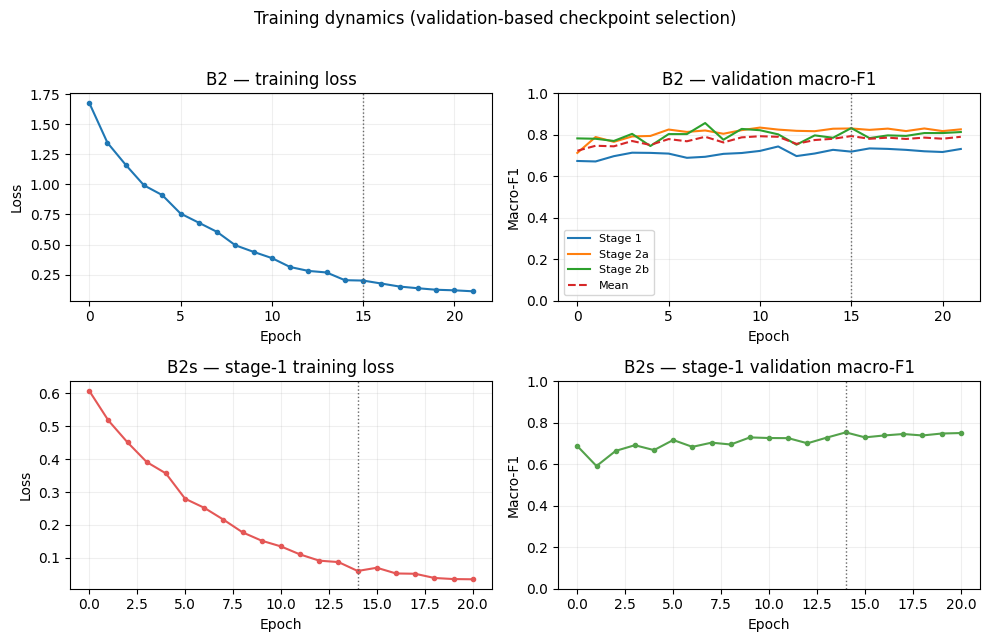

Saved report figure: /content/drive/MyDrive/bus-hier-work/figures/training_curves.png


In [13]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

def generate_training_curves():
    b2_hist_path = WORK / f"b2_{RUN_TAG}" / "history.csv"
    b2s_hist_path = WORK / f"b2s_{RUN_TAG}" / "history.csv"
    for path in (b2_hist_path, b2s_hist_path):
        if not path.exists():
            raise FileNotFoundError(f"Training history not found: {path}. Run the corresponding training cell first.")

    b2_hist = pd.read_csv(b2_hist_path).sort_values("epoch")
    b2s_hist = pd.read_csv(b2s_hist_path).sort_values("epoch")
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))

    axes[0, 0].plot(b2_hist["epoch"], b2_hist["train_loss"], marker="o", ms=3)
    axes[0, 0].set(title="B2 — training loss", xlabel="Epoch", ylabel="Loss")
    axes[0, 1].plot(b2_hist["epoch"], b2_hist["val_f1_stage1"], label="Stage 1")
    axes[0, 1].plot(b2_hist["epoch"], b2_hist["val_f1_stage2a"], label="Stage 2a")
    axes[0, 1].plot(b2_hist["epoch"], b2_hist["val_f1_stage2b"], label="Stage 2b")
    axes[0, 1].plot(b2_hist["epoch"], b2_hist["val_score"], "--", label="Mean")
    axes[0, 1].set(title="B2 — validation macro-F1", xlabel="Epoch", ylabel="Macro-F1", ylim=(0, 1))
    axes[0, 1].legend(fontsize=8)

    axes[1, 0].plot(b2s_hist["epoch"], b2s_hist["train_loss"], marker="o", ms=3, color="#e45756")
    axes[1, 0].set(title="B2s — stage-1 training loss", xlabel="Epoch", ylabel="Loss")
    axes[1, 1].plot(b2s_hist["epoch"], b2s_hist["val_stage1_macro_f1"], marker="o", ms=3, color="#54a24b")
    axes[1, 1].set(title="B2s — stage-1 validation macro-F1", xlabel="Epoch", ylabel="Macro-F1", ylim=(0, 1))

    for ax, hist in ((axes[0, 0], b2_hist), (axes[0, 1], b2_hist),
                     (axes[1, 0], b2s_hist), (axes[1, 1], b2s_hist)):
        if "best" in hist.columns:
            best = hist[hist["best"].astype(str).str.lower().eq("true")]
            if not best.empty:
                ax.axvline(best.iloc[-1]["epoch"], color="#666666", linestyle=":", linewidth=1)
        ax.grid(alpha=0.2)

    fig.suptitle("Training dynamics (validation-based checkpoint selection)")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    out_path = WORK / "figures" / "training_curves.png"
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved report figure: {out_path}")

generate_training_curves()


## Cascade threshold — validation-only three-head search

Reads `preds/B2s.csv` and nothing else. Every combination of the probability grid 0.40–0.60 for the three heads is scored on **validation four-leaf cascade macro-F1**; ties break toward higher stage-1 F1, then higher malignant recall, then the thresholds closest to 0.50. All three thresholds are locked before test is touched.

The 0.50/0.50/0.50 baseline is reported alongside, so the threshold contribution is visible rather than folded into the model.


In [14]:
# ============================================================
# Cascade-objective threshold experiment (joint validation-only selection)
# Selects a bounded threshold grid for all three heads; test is evaluation-only.
# ============================================================
for _name in ("final", "PRED_DIR", "LEAVES", "LEAF_IDX", "leaf_from_branch",
              "macro_f1_np", "evaluate_experiment", "paired_diff_rows", "save_results"):
    assert _name in globals(), f"Run the preceding model/evaluation cells first; missing {_name}."

_CTH_BASE = pd.read_csv(PRED_DIR / "B2s.csv")
_CTH_BASE["key"] = _CTH_BASE["key"].astype(str)
assert _CTH_BASE["key"].is_unique, "B2s.csv has duplicate keys"
assert {"s1", "s2a", "s2b"}.issubset(_CTH_BASE.columns), "B2s predictions lack expected logit columns"

# Only validation records with four-leaf labels contribute to threshold selection.
_CTH_VAL = final.loc[
    (final["final_split"] == "val") & final["leaf"].isin(LEAVES),
    ["key", "pathology", "leaf"],
].copy()
_CTH_VAL["key"] = _CTH_VAL["key"].astype(str)
_CTH_VAL = _CTH_VAL.merge(
    _CTH_BASE[["key", "s1", "s2a", "s2b"]], on="key", how="left", validate="one_to_one"
)
assert len(_CTH_VAL) > 0 and _CTH_VAL[["s1", "s2a", "s2b"]].notna().all().all(), \
    "Validation cascade rows are missing logits"
_CTH_SCORES = _CTH_VAL[["s1", "s2a", "s2b"]].to_numpy(dtype=float)
_CTH_Y = np.array([LEAF_IDX[x] for x in _CTH_VAL["leaf"].to_numpy()], dtype=np.int64)
_CTH_Y1 = (_CTH_VAL["pathology"].to_numpy() == "Malignant").astype(np.int64)
_CTH_MALIGNANT = _CTH_Y1 == 1
_CTH_PROB_GRID = np.array([0.40, 0.45, 0.50, 0.55, 0.60], dtype=float)
_CTH_LOGIT_GRID = np.log(_CTH_PROB_GRID / (1.0 - _CTH_PROB_GRID))

_CTH_ROWS = []
for _i, _t1_logit in enumerate(_CTH_LOGIT_GRID):
    _branch = (_CTH_SCORES[:, 0] > _t1_logit).astype(np.int64)
    for _j, _t2a_logit in enumerate(_CTH_LOGIT_GRID):
        _pred_2a = (_CTH_SCORES[:, 1] > _t2a_logit).astype(np.int64)
        for _k, _t2b_logit in enumerate(_CTH_LOGIT_GRID):
            _pred_2b = (_CTH_SCORES[:, 2] > _t2b_logit).astype(np.int64)
            _pred_leaf = leaf_from_branch(_branch, _pred_2a, _pred_2b)
            _pred = np.array([LEAF_IDX[x] for x in _pred_leaf], dtype=np.int64)
            _CTH_ROWS.append({
                "threshold_s1_prob": float(_CTH_PROB_GRID[_i]),
                "threshold_s2a_prob": float(_CTH_PROB_GRID[_j]),
                "threshold_s2b_prob": float(_CTH_PROB_GRID[_k]),
                "cascade_macro_f1": macro_f1_np(_CTH_Y, _pred, len(LEAVES)),
                "stage1_macro_f1": macro_f1_np(_CTH_Y1, _branch, 2),
                "malignant_recall": float((_branch[_CTH_MALIGNANT] == 1).mean())
                    if _CTH_MALIGNANT.any() else np.nan,
            })

_CTH_SWEEP = pd.DataFrame(_CTH_ROWS)
_CTH_SWEEP["distance_to_default"] = (
    (_CTH_SWEEP["threshold_s1_prob"] - 0.50).abs()
    + (_CTH_SWEEP["threshold_s2a_prob"] - 0.50).abs()
    + (_CTH_SWEEP["threshold_s2b_prob"] - 0.50).abs()
)
_CTH_SWEEP = _CTH_SWEEP.sort_values(
    ["cascade_macro_f1", "stage1_macro_f1", "malignant_recall", "distance_to_default"],
    ascending=[False, False, False, True], kind="stable",
).reset_index(drop=True)
_CTH_SELECTED = _CTH_SWEEP.iloc[0]
_CTH_BASELINE = _CTH_SWEEP.loc[
    np.isclose(_CTH_SWEEP["threshold_s1_prob"], 0.50)
    & np.isclose(_CTH_SWEEP["threshold_s2a_prob"], 0.50)
    & np.isclose(_CTH_SWEEP["threshold_s2b_prob"], 0.50)
].iloc[0]
print(f"Validation four-leaf rows: {len(_CTH_VAL)} | combinations: {len(_CTH_SWEEP)}")
print(f"0.50/0.50/0.50 baseline validation cascade macro-F1: {_CTH_BASELINE['cascade_macro_f1']:.4f}")
print("Selected validation thresholds (probability scale): "
      f"s1={_CTH_SELECTED['threshold_s1_prob']:.2f}, "
      f"s2a={_CTH_SELECTED['threshold_s2a_prob']:.2f}, "
      f"s2b={_CTH_SELECTED['threshold_s2b_prob']:.2f}")
print(f"Selected validation cascade macro-F1: {_CTH_SELECTED['cascade_macro_f1']:.4f}")
print("Top validation candidates:")
print(_CTH_SWEEP.head(10).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

_CTH_AUDIT_DIR = WORK / "audit"
_CTH_AUDIT_DIR.mkdir(parents=True, exist_ok=True)
_CTH_SWEEP_PATH = _CTH_AUDIT_DIR / "cascade_threshold_validation_sweep.csv"
_CTH_SWEEP.assign(selected=np.arange(len(_CTH_SWEEP)) == 0).to_csv(_CTH_SWEEP_PATH, index=False)
print(f"Saved full validation threshold sweep: {_CTH_SWEEP_PATH}")

# Lock all three thresholds before evaluating test; scores remain the original logits.
_CTH_LOGIT_THRESHOLDS = np.log(
    _CTH_SELECTED[["threshold_s1_prob", "threshold_s2a_prob", "threshold_s2b_prob"]].to_numpy(dtype=float)
    / (1.0 - _CTH_SELECTED[["threshold_s1_prob", "threshold_s2a_prob", "threshold_s2b_prob"]].to_numpy(dtype=float))
)
_CTH_PRED = _CTH_BASE.copy()
_CTH_PRED["p1"] = (_CTH_PRED["s1"].to_numpy(dtype=float) > _CTH_LOGIT_THRESHOLDS[0]).astype(np.int64)
_CTH_PRED["p2a"] = (_CTH_PRED["s2a"].to_numpy(dtype=float) > _CTH_LOGIT_THRESHOLDS[1]).astype(np.int64)
_CTH_PRED["p2b"] = (_CTH_PRED["s2b"].to_numpy(dtype=float) > _CTH_LOGIT_THRESHOLDS[2]).astype(np.int64)
_CTH_ID = "CascadeThreshold"
_CTH_NAME = "B2s stage1 and B2 subtype heads with validation-selected three-head cascade thresholds"
_CTH_RESULTS = evaluate_experiment(
    _CTH_ID, _CTH_NAME, _CTH_PRED, final, splits=("test",),
    notes="all three thresholds selected jointly on validation four-leaf cascade macro-F1; test used only after locking",
)
for _baseline in ("B2", "B2s", "B2st"):
    _CTH_RESULTS.extend(paired_diff_rows(_CTH_ID, _baseline, final, splits=("test",)))
_CTH_SAVED = save_results(_CTH_RESULTS)
print("Test results and paired group-bootstrap differences (positive = CascadeThreshold better):")
print(_CTH_SAVED[_CTH_SAVED["exp_id"].str.contains(_CTH_ID)][
    ["exp_id", "evaluation", "n", "macro_f1", "f1_lo", "f1_hi"]
].to_string(index=False))

Validation four-leaf rows: 394 | combinations: 125
0.50/0.50/0.50 baseline validation cascade macro-F1: 0.5555
Selected validation thresholds (probability scale): s1=0.40, s2a=0.55, s2b=0.60
Selected validation cascade macro-F1: 0.5726
Top validation candidates:
 threshold_s1_prob  threshold_s2a_prob  threshold_s2b_prob  cascade_macro_f1  stage1_macro_f1  malignant_recall  distance_to_default
            0.4000              0.5500              0.6000            0.5726           0.6745            0.6968               0.2500
            0.4000              0.6000              0.6000            0.5726           0.6745            0.6968               0.3000
            0.4000              0.5500              0.5500            0.5695           0.6745            0.6968               0.2000
            0.4000              0.6000              0.5500            0.5695           0.6745            0.6968               0.2500
            0.5000              0.5500              0.6000            0.

## Leaderboard

`results.csv` pivot sorted by end-to-end cascade, then the paired grouped-bootstrap differences. Positive Δ means the first experiment is better.


In [15]:
# ============================================================
# LEADERBOARD (single source of truth: results.csv)
# ============================================================
_EXPS_ORDER = ["B0a", "B0b", "B1", "B2", "B2s", "B2st", "CascadeThreshold"]
_SOURCE_EXPS = [e for e in _EXPS_ORDER if (PRED_DIR / f"{e}.csv").exists()]
_RES = pd.read_csv(WORK / "results.csv")
_TEST = _RES[(_RES["split"] == "test") & (~_RES["exp_id"].str.startswith("D_"))
             & _RES["exp_id"].isin(_SOURCE_EXPS)]
_PIV = _TEST.pivot_table(index="exp_id", columns="evaluation",
                         values="macro_f1", aggfunc="first")
_ORDER = [c for c in ["stage1", "stage2a", "stage2b", "leaf_cascade", "leaf_oracle"]
          if c in _PIV.columns]
_PIV = _PIV.reindex(columns=_ORDER).sort_values("leaf_cascade", ascending=False)
print("Test macro-F1 by experiment (sorted by end-to-end cascade):")
print(_PIV.round(4).to_string())
print("\nPaired differences (test, 95% grouped-bootstrap CI):")
_D = _RES[(_RES["split"] == "test") & _RES["exp_id"].str.startswith("D_")]
if not _D.empty:
    _D_MODELS = _D["exp_id"].str.replace(r"^D_", "", regex=True).str.split("-", n=1, expand=True)
    _D = _D.loc[_D_MODELS[0].isin(_SOURCE_EXPS) & _D_MODELS[1].isin(_SOURCE_EXPS)]
print(_D[["exp_id", "evaluation", "macro_f1", "f1_lo", "f1_hi"]]
      .sort_values(["exp_id", "evaluation"]).to_string(index=False))

# Include only predictions for experiments run in this notebook.
_SOURCE_ROWS = []
for _exp in _SOURCE_EXPS:
    _P = pd.read_csv(PRED_DIR / f"{_exp}.csv")
    for _split in ("val", "test"):
        for _ev in EVALS:
            _A = eval_arrays(_P, final, _ev, _split)
            _T = final[final["final_split"] == _split].merge(
                _P, on="key", how="left", validate="one_to_one")
            if _ev in STAGES:
                _T = stage_frames(_T)[_ev]
            else:
                _T = _T[_T["leaf"].notna()]
            assert len(_T) == _A["n"], f"{_exp}/{_split}/{_ev}: source row mismatch"
            _src = _T["dataset"].to_numpy()
            for _s in sorted(pd.unique(_src)):
                _idx = np.where(_src == _s)[0]
                _n = len(_idx)
                _f1 = macro_f1_np(_A["y"][_idx], _A["pred"][_idx], _A["k"])
                _acc = float((np.asarray(_A["y"][_idx]) == np.asarray(_A["pred"][_idx])).mean())
                _SOURCE_ROWS.append(dict(exp_id=_exp, split=_split, evaluation=_ev,
                                         source=_s, n=_n, macro_f1=round(_f1, 4),
                                         acc=round(_acc, 4),
                                         note="" if _n >= 10 else "n<10: interpret with caution"))
            _SOURCE_ROWS.append(dict(exp_id=_exp, split=_split, evaluation=_ev, source="ALL",
                                     n=_A["n"], macro_f1=round(macro_f1_np(_A["y"], _A["pred"], _A["k"]), 4),
                                     acc=round(float((_A["y"] == _A["pred"]).mean()), 4), note=""))
_SOURCE_DF = pd.DataFrame(_SOURCE_ROWS)
_SOURCE_DF.to_csv(WORK / "audit" / "source_strata.csv", index=False)

for _exp in _SOURCE_EXPS:
    _P = pd.read_csv(PRED_DIR / f"{_exp}.csv")
    _A = eval_arrays(_P, final, "leaf_cascade", "test")
    _cm = np.zeros((4, 4), dtype=int)
    for _t, _p in zip(_A["y"], _A["pred"]):
        _cm[int(_t), int(_p)] += 1
    _C = pd.DataFrame(_cm, index=[f"true_{l}" for l in LEAVES],
                      columns=[f"pred_{l}" for l in LEAVES])
    _C["recall"] = (np.diag(_cm) / np.maximum(_cm.sum(1), 1)).round(3)
    _C.to_csv(WORK / "audit" / f"leaf_confusion_test_{_exp}.csv", index=False)

print("\nRefreshed per-source report:", WORK / "audit" / "source_strata.csv")
print("Included experiments:", _SOURCE_EXPS)

Test macro-F1 by experiment (sorted by end-to-end cascade):
evaluation        stage1  stage2a  stage2b  leaf_cascade  leaf_oracle
exp_id                                                               
CascadeThreshold  0.7997   0.8015   0.8138        0.6393       0.8077
B2st              0.7986   0.7868   0.8142        0.6319       0.8005
B2s               0.7993   0.7868   0.8142        0.6265       0.8005
B2                0.7832   0.7868   0.8142        0.6021       0.8005
B1                0.7320   0.6998   0.7220        0.5295       0.7109
B0b               0.6002   0.7534   0.8344        0.3169       0.7939
B0a               0.3520   0.3848   0.3750        0.1457       0.3799

Paired differences (test, 95% grouped-bootstrap CI):
                 exp_id   evaluation  macro_f1   f1_lo   f1_hi
              D_B0b-B0a leaf_cascade    0.1712  0.1098  0.2310
              D_B0b-B0a  leaf_oracle    0.4140  0.3410  0.4790
              D_B0b-B0a       stage1    0.2482  0.1792  0.3090
    

## Extended metrics and plots

Read-only. Recomputes accuracy, balanced accuracy, macro precision/recall/F1, MCC, Cohen κ, ROC-AUC and PR-AUC from the stored prediction tables, then renders the cascade confusion matrices and per-class figures.


In [16]:
# ============================================================
# METRICS - helpers (read-only)
# No files are written. All results stay in memory / cell output.
# ============================================================
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, cohen_kappa_score, confusion_matrix,
    f1_score, fowlkes_mallows_score, hamming_loss, jaccard_score,
    log_loss, matthews_corrcoef, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)

try:
    from IPython.display import display
except Exception:
    display = print

if "WORK" not in globals():
    WORK = Path("/content/drive/MyDrive/bus-hier-work")
XM_WORK = Path(WORK)
XM_PRED_DIR = XM_WORK / "preds"
XM_SPLITS_CSV = XM_WORK / "splits_v1.csv"
assert XM_SPLITS_CSV.exists(), f"Missing: {XM_SPLITS_CSV} (run SETUP + split cells first)"
assert XM_PRED_DIR.exists(), f"Missing: {XM_PRED_DIR} (run B0a/B0b/B1/B2 cells first)"

XM_FINAL = pd.read_csv(XM_SPLITS_CSV)
XM_FINAL["key"] = XM_FINAL["key"].astype(str)
assert XM_FINAL["key"].is_unique, "splits_v1.csv has duplicate keys"

XM_LEAVES = ["fibroadenoma", "other_benign", "idc_nst", "other_malignant"]
XM_LEAF_IDX = {l: i for i, l in enumerate(XM_LEAVES)}
XM_STAGES = ["stage1", "stage2a", "stage2b"]
XM_VIEWS = ["stage1", "stage2a", "stage2b", "stage2_combined", "cascade"]
XM_VIEW_TITLE = {
    "stage1": "Stage 1 only - benign vs malignant",
    "stage2a": "Stage 2 only - fibroadenoma vs other benign",
    "stage2b": "Stage 2 only - IDC vs other malignant",
    "stage2_combined": "Stage 2 only - 4-leaf with true branch (oracle)",
    "cascade": "Stage 1 + Stage 2 - end-to-end cascade",
}
XM_VIEW_SHORT = {
    "stage1": "S1",
    "stage2a": "S2a",
    "stage2b": "S2b",
    "stage2_combined": "S2-all",
    "cascade": "S1+S2",
}
XM_PRED_COLS = {"stage1": ("p1", "s1"), "stage2a": ("p2a", "s2a"), "stage2b": ("p2b", "s2b")}
XM_MODELS = [m for m in ("B0a", "B0b", "B1", "B2", "B2s", "B2st", "CascadeThreshold")
             if (XM_PRED_DIR / f"{m}.csv").exists()]
XM_SPLITS = ("train", "val", "test")
XM_PLOT_METRICS = [
    "accuracy", "balanced_accuracy", "precision_macro", "recall_macro",
    "f1_macro", "f1_weighted", "specificity_macro", "npv_macro",
    "mcc", "cohen_kappa", "jaccard_macro", "hamming_loss",
    "roc_auc", "pr_auc", "youden_j",
]
XM_COLORS = {
    "B0a": "#9E9E9E", "B0b": "#8C6D31", "B1": "#4C78A8", "B2": "#E45756",
    "B2s": "#54A24B", "B2st": "#72B7B2", "CascadeThreshold": "#9467BD",
}


def xm_stage_frames(df):
    """Same stage filter/labels as the notebook's stage_frames()."""
    out = {}
    s1 = df[df["pathology"].notna()].copy()
    s1["y"] = (s1["pathology"] == "Malignant").astype(int)
    out["stage1"] = s1
    s2a = df[df["leaf"].isin(["fibroadenoma", "other_benign"])].copy()
    s2a["y"] = (s2a["leaf"] == "fibroadenoma").astype(int)
    out["stage2a"] = s2a
    s2b = df[df["leaf"].isin(["idc_nst", "other_malignant"])].copy()
    s2b["y"] = (s2b["leaf"] == "idc_nst").astype(int)
    out["stage2b"] = s2b
    return out


def xm_leaf_from_branch(branch, pred_2a, pred_2b):
    branch = np.asarray(branch)
    benign = np.where(np.asarray(pred_2a) == 1, "fibroadenoma", "other_benign")
    malign = np.where(np.asarray(pred_2b) == 1, "idc_nst", "other_malignant")
    return np.where(branch == 1, malign, benign)


def xm_arrays(P, split, view):
    """Builds y / prediction / score arrays for one model, split and view."""
    d = XM_FINAL.loc[XM_FINAL["final_split"] == split].merge(
        P, on="key", how="left", validate="one_to_one")
    n_total = len(d)
    for c in ("p1", "p2a", "p2b"):
        assert c in d.columns and d[c].notna().all(), \
            f"Prediction table is missing {c} for {split}/{view}"
    if view in XM_STAGES:
        sub = xm_stage_frames(d)[view]
        pc, sc = XM_PRED_COLS[view]
        score = sub[sc].to_numpy(float)
        if not np.isfinite(score).all():
            score = None
        return dict(y=sub["y"].to_numpy(int), pred=sub[pc].to_numpy(int),
                    score=score, groups=sub["group"].to_numpy(),
                    k=2, n=len(sub), n_total=n_total)
    d = d.loc[d["pathology"].notna()].copy()
    if view == "cascade":
        branch = d["p1"].to_numpy(int)
    elif view == "stage2_combined":
        branch = (d["pathology"].to_numpy() == "Malignant").astype(int)
    else:
        raise ValueError(view)
    pred_leaf = xm_leaf_from_branch(branch, d["p2a"].to_numpy(int), d["p2b"].to_numpy(int))
    mask = d["leaf"].notna().to_numpy()
    y = np.array([XM_LEAF_IDX[x] for x in d["leaf"].to_numpy()[mask]], dtype=int)
    p = np.array([XM_LEAF_IDX[x] for x in pred_leaf[mask]], dtype=int)
    return dict(y=y, pred=p, score=None, groups=d["group"].to_numpy()[mask],
                k=len(XM_LEAVES), n=int(mask.sum()), n_total=n_total)


def xm_binary_labels(view):
    return {
        "stage1": ["benign", "malignant"],
        "stage2a": ["other_benign", "fibroadenoma"],
        "stage2b": ["other_malignant", "idc_nst"],
    }[view]


def _div(a, b):
    return float(a) / float(b) if b else np.nan


def xm_binary_metrics(y, p, score, view):
    y = np.asarray(y, int)
    p = np.asarray(p, int)
    n = len(y)
    cm = confusion_matrix(y, p, labels=[0, 1])
    tn, fp, fn, tp = [int(v) for v in cm.ravel()]
    pos, neg = tp + fn, tn + fp
    prec = _div(tp, tp + fp)
    rec = _div(tp, tp + fn)
    spec = _div(tn, tn + fp)
    npv = _div(tn, tn + fn)
    acc = _div(tp + tn, n)
    f1 = _div(2 * prec * rec, prec + rec) if np.isfinite(prec + rec) and (prec + rec) else 0.0
    fpr = _div(fp, fp + tn)
    fnr = _div(fn, fn + tp)
    pt = (np.sqrt(rec * fpr) - fpr) / (rec - fpr) if np.isfinite(rec) and np.isfinite(fpr) and (rec - fpr) else np.nan
    out = {
        "n": n, "n_pos": pos, "n_neg": neg,
        "tp": tp, "tn": tn, "fp": fp, "fn": fn,
        "prevalence": _div(pos, n),
        "predicted_positive_rate": _div(tp + fp, n),
        "accuracy": _div(tp + tn, n),
        "balanced_accuracy": balanced_accuracy_score(y, p),
        "error_rate": 1.0 - _div(tp + tn, n),
        "precision": prec, "ppv": prec,
        "recall": rec, "sensitivity": rec, "tpr": rec,
        "specificity": spec, "tnr": spec, "selectivity": spec,
        "npv": npv,
        "fpr": fpr, "fnr": fnr,
        "f1": f1,
        "f2": _div(5 * prec * rec, 4 * prec + rec) if np.isfinite(prec + rec) and (4 * prec + rec) else np.nan,
        "f0_5": _div(1.25 * prec * rec, 0.25 * prec + rec) if np.isfinite(prec + rec) and (0.25 * prec + rec) else np.nan,
        "precision_micro": _div(tp + tn, n),
        "recall_micro": _div(tp + tn, n),
        "f1_micro": _div(tp + tn, n),
        "precision_macro": precision_score(y, p, average="macro", labels=[0, 1], zero_division=0),
        "recall_macro": recall_score(y, p, average="macro", labels=[0, 1], zero_division=0),
        "f1_macro": f1_score(y, p, average="macro", labels=[0, 1], zero_division=0),
        "precision_weighted": precision_score(y, p, average="weighted", labels=[0, 1], zero_division=0),
        "recall_weighted": recall_score(y, p, average="weighted", labels=[0, 1], zero_division=0),
        "f1_weighted": f1_score(y, p, average="weighted", labels=[0, 1], zero_division=0),
        "specificity_macro": np.mean([rec, spec]),
        "npv_macro": np.mean([prec, npv]),
        "cohen_kappa": cohen_kappa_score(y, p),
        "mcc": matthews_corrcoef(y, p),
        "jaccard": jaccard_score(y, p, pos_label=1, zero_division=0),
        "jaccard_macro": jaccard_score(y, p, average="macro", labels=[0, 1], zero_division=0),
        "jaccard_weighted": jaccard_score(y, p, average="weighted", labels=[0, 1], zero_division=0),
        "jaccard_samples": _div(tp + tn, n),
        "hamming_loss": hamming_loss(y, p),
        "zero_one_loss": 1.0 - _div(tp + tn, n),
        "youden_j": rec + spec - 1.0 if np.isfinite(rec) and np.isfinite(spec) else np.nan,
        "informedness": rec + spec - 1.0 if np.isfinite(rec) and np.isfinite(spec) else np.nan,
        "markedness": prec + npv - 1.0 if np.isfinite(prec) and np.isfinite(npv) else np.nan,
        "critical_success_index": _div(tp, tp + fn + fp),
        "prevalence_threshold": pt,
        "lr_plus": _div(rec, fpr) if fpr else np.inf,
        "lr_minus": _div(fnr, spec) if spec else np.inf,
        "diagnostic_odds_ratio": _div(tp * tn, fp * fn) if fp * fn else np.inf,
        "roc_auc": np.nan, "pr_auc": np.nan, "brier": np.nan, "log_loss": np.nan,
    }
    try:
        out["fowlkes_mallows"] = fowlkes_mallows_score(y, p)
    except Exception:
        out["fowlkes_mallows"] = np.nan
    if score is not None:
        s = np.asarray(score, float)
        if np.isfinite(s).all() and len(np.unique(y)) == 2:
            out["roc_auc"] = roc_auc_score(y, s)
            out["pr_auc"] = average_precision_score(y, s)
            if s.min() >= 0 and s.max() <= 1:
                out["brier"] = brier_score_loss(y, s)
                out["log_loss"] = log_loss(y, np.clip(s, 1e-7, 1 - 1e-7), labels=[0, 1])
    labels = xm_binary_labels(view)
    pc_rows = []
    for cls in (0, 1):
        tp_c = int(cm[cls, cls])
        fp_c = int(cm[:, cls].sum() - tp_c)
        fn_c = int(cm[cls, :].sum() - tp_c)
        tn_c = int(cm.sum() - tp_c - fp_c - fn_c)
        pr = _div(tp_c, tp_c + fp_c)
        rc = _div(tp_c, tp_c + fn_c)
        pc_rows.append(dict(
            class_id=cls, class_name=labels[cls], support=int(cm[cls, :].sum()),
            tp=tp_c, fp=fp_c, fn=fn_c, tn=tn_c,
            precision=pr, recall=rc, specificity=_div(tn_c, tn_c + fp_c),
            npv=_div(tn_c, tn_c + fn_c),
            f1=_div(2 * pr * rc, pr + rc) if (pr + rc) else 0.0,
        ))
    return out, pc_rows


def xm_multiclass_metrics(y, p, view):
    y = np.asarray(y, int)
    p = np.asarray(p, int)
    labels = list(range(len(XM_LEAVES)))
    cm = confusion_matrix(y, p, labels=labels)
    tp = np.diag(cm).astype(float)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    tn = cm.sum() - tp - fp - fn
    prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    rec = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    spec = np.divide(tn, tn + fp, out=np.zeros_like(tp), where=(tn + fp) > 0)
    npv = np.divide(tn, tn + fn, out=np.zeros_like(tp), where=(tn + fn) > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    out = {
        "n": len(y),
        "accuracy": accuracy_score(y, p),
        "balanced_accuracy": balanced_accuracy_score(y, p),
        "error_rate": 1.0 - accuracy_score(y, p),
        "precision_macro": precision_score(y, p, average="macro", labels=labels, zero_division=0),
        "recall_macro": recall_score(y, p, average="macro", labels=labels, zero_division=0),
        "f1_macro": f1_score(y, p, average="macro", labels=labels, zero_division=0),
        "precision_micro": precision_score(y, p, average="micro", labels=labels, zero_division=0),
        "recall_micro": recall_score(y, p, average="micro", labels=labels, zero_division=0),
        "f1_micro": f1_score(y, p, average="micro", labels=labels, zero_division=0),
        "precision_weighted": precision_score(y, p, average="weighted", labels=labels, zero_division=0),
        "recall_weighted": recall_score(y, p, average="weighted", labels=labels, zero_division=0),
        "f1_weighted": f1_score(y, p, average="weighted", labels=labels, zero_division=0),
        "specificity_macro": float(np.mean(spec)),
        "npv_macro": float(np.mean(npv)),
        "cohen_kappa": cohen_kappa_score(y, p),
        "mcc": matthews_corrcoef(y, p),
        "jaccard_macro": jaccard_score(y, p, average="macro", labels=labels, zero_division=0),
        "jaccard_weighted": jaccard_score(y, p, average="weighted", labels=labels, zero_division=0),
        "jaccard_samples": accuracy_score(y, p),
        "hamming_loss": hamming_loss(y, p),
        "zero_one_loss": 1.0 - accuracy_score(y, p),
        "roc_auc": np.nan, "pr_auc": np.nan,
    }
    try:
        out["fowlkes_mallows"] = fowlkes_mallows_score(y, p)
    except Exception:
        out["fowlkes_mallows"] = np.nan
    pc_rows = []
    for i, name in enumerate(XM_LEAVES):
        pc_rows.append(dict(
            class_id=i, class_name=name, support=int(cm[i, :].sum()),
            tp=int(tp[i]), fp=int(fp[i]), fn=int(fn[i]), tn=int(tn[i]),
            precision=float(prec[i]), recall=float(rec[i]),
            specificity=float(spec[i]), npv=float(npv[i]), f1=float(f1[i]),
        ))
    return out, pc_rows


XM_META_COLS = ["model", "split", "view", "kind", "n", "n_split", "coverage"]
XM_BINARY_METRIC_COLS = [
    "n", "n_pos", "n_neg", "coverage", "tp", "tn", "fp", "fn",
    "prevalence", "predicted_positive_rate", "accuracy", "balanced_accuracy",
    "error_rate", "precision", "recall", "specificity", "npv", "f1", "f2", "f0_5",
    "precision_macro", "recall_macro", "f1_macro",
    "precision_micro", "recall_micro", "f1_micro",
    "precision_weighted", "recall_weighted", "f1_weighted",
    "specificity_macro", "npv_macro", "cohen_kappa", "mcc",
    "jaccard", "jaccard_macro", "jaccard_weighted", "jaccard_samples",
    "hamming_loss", "zero_one_loss", "youden_j", "informedness", "markedness",
    "critical_success_index", "prevalence_threshold", "lr_plus", "lr_minus",
    "diagnostic_odds_ratio", "fowlkes_mallows", "roc_auc", "pr_auc", "brier", "log_loss",
]
XM_MULTI_METRIC_COLS = [
    "n", "coverage", "accuracy", "balanced_accuracy", "error_rate",
    "precision_macro", "recall_macro", "f1_macro",
    "precision_micro", "recall_micro", "f1_micro",
    "precision_weighted", "recall_weighted", "f1_weighted",
    "specificity_macro", "npv_macro", "cohen_kappa", "mcc",
    "jaccard_macro", "jaccard_weighted", "jaccard_samples",
    "hamming_loss", "zero_one_loss", "fowlkes_mallows", "roc_auc", "pr_auc",
]
XM_CORE_METRICS = [
    "accuracy", "balanced_accuracy", "precision_macro", "recall_macro",
    "f1_macro", "f1_weighted", "mcc", "cohen_kappa",
]

def xm_show_view(view, kind="binary"):
    cols = XM_BINARY_METRIC_COLS if kind == "binary" else XM_MULTI_METRIC_COLS
    d = XM_METRICS[XM_METRICS["view"] == view].copy()
    long = d.melt(id_vars=["model", "split"], value_vars=cols,
                  var_name="metric", value_name="value")
    tab = long.pivot(index="metric", columns=["model", "split"], values="value")
    tab = tab.reindex([c for c in cols if c in tab.index])
    tab.index.name = f"{XM_VIEW_TITLE[view]}"
    display(tab.round(4))


def xm_show_perclass(view):
    d = XM_PERCLASS[XM_PERCLASS["view"] == view].copy()
    cols = ["model", "split", "class_name", "support", "tp", "fp", "fn", "tn",
            "precision", "recall", "specificity", "npv", "f1"]
    d = d[cols].sort_values(["model", "split", "class_name"])
    d = d.rename(columns={"class_name": "class"})
    print(f"\nPer-class metrics - {XM_VIEW_TITLE[view]}")
    display(d.round(4).reset_index(drop=True))

# ------------------------------------------------------------------
# Plot helpers (all figures are shown in the cell output; no savefig)
# ------------------------------------------------------------------
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
XM_01_METRICS = {
    "accuracy", "balanced_accuracy", "precision_macro", "recall_macro",
    "f1_macro", "f1_weighted", "precision_micro", "recall_micro", "f1_micro",
    "specificity_macro", "npv_macro", "jaccard_macro", "jaccard_weighted",
    "hamming_loss", "roc_auc", "pr_auc",
}


def _xm_view_labels(view):
    return xm_binary_labels(view) if view in XM_STAGES else XM_LEAVES


def _xm_heat_text(val, is_pct):
    return f"{val * 100:.1f}%" if is_pct else f"{int(val)}"


def xm_confusion_figure(view):
    """One figure per model: rows = train/val/test, cols = counts / row-normalized."""
    labels = _xm_view_labels(view)
    k = len(labels)
    for model in XM_MODELS:
        fig, axes = plt.subplots(len(XM_SPLITS), 2, figsize=(9.2, 3.05 * len(XM_SPLITS)),
                                 squeeze=False)
        for i, split in enumerate(XM_SPLITS):
            A = XM_ARR[(model, split, view)]
            cm = confusion_matrix(A["y"], A["pred"], labels=list(range(k)))
            row = cm.sum(1, keepdims=True)
            norm = np.divide(cm, row, out=np.zeros_like(cm, float), where=row > 0)
            for j, (mat, is_pct) in enumerate(((cm, False), (norm, True))):
                ax = axes[i, j]
                vmax = 1.0 if is_pct else max(int(cm.max()), 1)
                im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=vmax)
                for a in range(k):
                    for b in range(k):
                        val = mat[a, b]
                        ax.text(b, a, _xm_heat_text(val, is_pct), ha="center", va="center",
                                fontsize=7.5,
                                color="white" if val > 0.55 * vmax else "black")
                ax.set_xticks(range(k))
                ax.set_xticklabels(labels, rotation=40, ha="right", fontsize=7.5)
                ax.set_yticks(range(k))
                ax.set_yticklabels(labels, fontsize=7.5)
                ax.set_xlabel("predicted")
                ax.set_ylabel("true")
                ax.set_title(f"{split} - {'counts' if not is_pct else 'row-normalized'}")
                fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
        fig.suptitle(f"{model} | {XM_VIEW_TITLE[view]} | confusion matrix", fontsize=11.5, y=1.005)
        plt.tight_layout()
        plt.show()
        plt.close(fig)


def xm_roc_pr_figure(view):
    """Rows = splits, cols = ROC / PR. Only models with a continuous score appear."""
    if view not in XM_STAGES:
        return
    fig, axes = plt.subplots(len(XM_SPLITS), 2, figsize=(10.0, 3.5 * len(XM_SPLITS)),
                             squeeze=False)
    n_curves = 0
    for i, split in enumerate(XM_SPLITS):
        for model in XM_MODELS:
            A = XM_ARR[(model, split, view)]
            if A["score"] is None or len(np.unique(A["y"])) < 2:
                continue
            y, s = A["y"], A["score"]
            fpr, tpr, _ = roc_curve(y, s)
            axes[i, 0].plot(fpr, tpr, lw=1.7, color=XM_COLORS.get(model),
                            label=f"{model} (AUC {roc_auc_score(y, s):.3f})")
            prec, rec, _ = precision_recall_curve(y, s)
            axes[i, 1].plot(rec, prec, lw=1.7, color=XM_COLORS.get(model),
                            label=f"{model} (AP {average_precision_score(y, s):.3f})")
            n_curves += 1
        axes[i, 0].plot([0, 1], [0, 1], "--", color="grey", lw=0.8)
        axes[i, 0].set_xlim(0, 1); axes[i, 0].set_ylim(0, 1.02)
        axes[i, 0].set_xlabel("false positive rate"); axes[i, 0].set_ylabel("true positive rate")
        axes[i, 0].set_title(f"{split} - ROC")
        axes[i, 1].set_xlim(0, 1); axes[i, 1].set_ylim(0, 1.02)
        axes[i, 1].set_xlabel("recall"); axes[i, 1].set_ylabel("precision")
        axes[i, 1].set_title(f"{split} - Precision-Recall")
        axes[i, 1].axhline(np.mean(A["y"]), color="grey", ls=":", lw=0.8)
    if n_curves == 0:
        plt.close(fig)
        print(f"  [skip] {view}: no continuous scores (only hard predictions).")
        return
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=min(4, len(labels)), fontsize=8)
    fig.suptitle(f"{XM_VIEW_TITLE[view]} | ROC and PR curves", fontsize=11.5, y=1.005)
    plt.tight_layout(rect=[0, 0.045, 1, 1])
    plt.show()
    plt.close(fig)


def xm_perclass_figure(view, metric):
    """Rows = splits, cols = classes; bars = models."""
    labels = _xm_view_labels(view)
    fig, axes = plt.subplots(len(XM_SPLITS), len(labels),
                             figsize=(3.1 * len(labels), 2.9 * len(XM_SPLITS)), squeeze=False)
    for i, split in enumerate(XM_SPLITS):
        for j, lab in enumerate(labels):
            ax = axes[i, j]
            vals = []
            for model in XM_MODELS:
                sub = XM_PERCLASS[(XM_PERCLASS["model"] == model) &
                                  (XM_PERCLASS["split"] == split) &
                                  (XM_PERCLASS["view"] == view) &
                                  (XM_PERCLASS["class_name"] == lab)]
                vals.append(float(sub[metric].iloc[0]) if len(sub) else np.nan)
            ax.bar(range(len(XM_MODELS)), vals,
                   color=[XM_COLORS.get(m, "#777777") for m in XM_MODELS])
            ax.set_ylim(0, 1.05)
            ax.set_xticks(range(len(XM_MODELS)))
            ax.set_xticklabels(XM_MODELS, fontsize=7.5)
            ax.set_title(f"{split} | {lab}", fontsize=8)
            ax.set_ylabel(metric)
            for b, v in enumerate(vals):
                if np.isfinite(v):
                    ax.text(b, v + 0.02, f"{v:.2f}", ha="center", fontsize=6.5)
    fig.suptitle(f"{XM_VIEW_TITLE[view]} | per-class {metric}", fontsize=11.5, y=1.005)
    plt.tight_layout()
    plt.show()
    plt.close(fig)


def xm_metric_by_view_figure(metric):
    """One figure per metric: rows = splits (as columns), x = stage views, bars = models."""
    views = [v for v in XM_VIEWS
             if XM_METRICS.loc[XM_METRICS["view"] == v, metric].notna().any()]
    if not views:
        print(f"  [skip] {metric}: no values.")
        return
    models_here = [m for m in XM_MODELS
                   if XM_METRICS.loc[XM_METRICS["model"] == m, metric].notna().any()]
    fig, axes = plt.subplots(1, len(XM_SPLITS), figsize=(5.1 * len(XM_SPLITS), 4.0),
                             squeeze=False)
    width = 0.8 / max(len(models_here), 1)
    for j, split in enumerate(XM_SPLITS):
        ax = axes[0, j]
        x = np.arange(len(views))
        for i, model in enumerate(models_here):
            vals = []
            for v in views:
                sub = XM_METRICS[(XM_METRICS["model"] == model) &
                                 (XM_METRICS["split"] == split) &
                                 (XM_METRICS["view"] == v)]
                vals.append(float(sub[metric].iloc[0]) if len(sub) else np.nan)
            ax.bar(x + (i - (len(XM_MODELS) - 1) / 2) * width, vals, width,
                   label=model, color=XM_COLORS.get(model, "#777777"))
        ax.set_xticks(x)
        ax.set_xticklabels([XM_VIEW_SHORT[v] for v in views], fontsize=8)
        ax.set_title(split)
        ax.set_ylabel(metric)
        ax.axhline(0, color="black", lw=0.5)
        if metric in XM_01_METRICS:
            ax.set_ylim(0, 1.05)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=max(1, len(labels)), fontsize=8)
    fig.suptitle(f"Metric by stage view: {metric}", fontsize=12, y=1.02)
    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.show()
    plt.close(fig)

print("26A ready: metric and plot helpers defined.")
print("Models :", XM_MODELS)
print("Splits :", XM_SPLITS)
print("Views  :", XM_VIEWS)

26A ready: metric and plot helpers defined.
Models : ['B0a', 'B0b', 'B1', 'B2', 'B2s', 'B2st', 'CascadeThreshold']
Splits : ('train', 'val', 'test')
Views  : ['stage1', 'stage2a', 'stage2b', 'stage2_combined', 'cascade']


In [17]:
# ============================================================
# METRICS - collect every model x split x stage view
# Input : available preds/*.csv experiment tables + splits_v1.csv
# ============================================================
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    XM_ROWS, XM_PC_ROWS, XM_ARR = [], [], {}
    for _model in XM_MODELS:
        _P = pd.read_csv(XM_PRED_DIR / f"{_model}.csv")
        _P["key"] = _P["key"].astype(str)
        assert _P["key"].is_unique, f"{_model}.csv has duplicate keys"
        for _split in XM_SPLITS:
            for _view in XM_VIEWS:
                _A = xm_arrays(_P, _split, _view)
                if _view in XM_STAGES:
                    _m, _pc = xm_binary_metrics(_A["y"], _A["pred"], _A["score"], _view)
                    _kind = "binary"
                else:
                    _m, _pc = xm_multiclass_metrics(_A["y"], _A["pred"], _view)
                    _kind = "multiclass"
                _base = dict(model=_model, split=_split, view=_view, kind=_kind,
                             n=_A["n"], n_split=_A["n_total"],
                             coverage=(_A["n"] / _A["n_total"]) if _A["n_total"] else np.nan)
                XM_ROWS.append({**_base, **_m})
                for _r in _pc:
                    XM_PC_ROWS.append({**_base, **_r})
                XM_ARR[(_model, _split, _view)] = _A

    XM_METRICS = pd.DataFrame(XM_ROWS)
    XM_PERCLASS = pd.DataFrame(XM_PC_ROWS)

print("26B ready: metrics collected (no files written).")
print("Rows   :", len(XM_METRICS), "metric rows |", len(XM_PERCLASS), "per-class rows")
if "B0a" in XM_MODELS and "B0b" in XM_MODELS:
    print("Note   : B0a/B0b have no scores -> ROC-AUC / PR-AUC / Brier / log-loss = NaN.")
print("Note   : B1/B2 scores are decision values / logits, not calibrated probabilities;")
print("         Brier / log-loss are computed only if every score is in [0, 1].")

26B ready: metrics collected (no files written).
Rows   : 105 metric rows | 294 per-class rows
Note   : B0a/B0b have no scores -> ROC-AUC / PR-AUC / Brier / log-loss = NaN.
Note   : B1/B2 scores are decision values / logits, not calibrated probabilities;
         Brier / log-loss are computed only if every score is in [0, 1].


In [18]:
# ============================================================
# METRICS - full metric tables
# One table per stage view: rows = metrics, columns = model x split.
# Per-class tables follow (precision / recall / specificity / NPV / F1 / support).
# ============================================================
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 260)
pd.set_option("display.max_rows", 400)

for view in XM_VIEWS:
    kind = "binary" if view in XM_STAGES else "multiclass"
    print("\n" + "=" * 110)
    print(XM_VIEW_TITLE[view])
    print("=" * 110)
    xm_show_view(view, kind)
    xm_show_perclass(view)

print("\n" + "=" * 110)
print("TEST - core metrics at a glance")
print("=" * 110)
_core = ["accuracy", "balanced_accuracy", "precision_macro", "recall_macro",
         "f1_macro", "mcc", "cohen_kappa", "roc_auc", "pr_auc"]
_t = XM_METRICS[XM_METRICS["split"] == "test"][["view", "model"] + _core].copy()
_t["view"] = pd.Categorical(_t["view"], categories=XM_VIEWS, ordered=True)
_t = _t.sort_values(["view", "model"])
_t["view"] = _t["view"].astype(str).map(XM_VIEW_SHORT)
display(_t.round(4).reset_index(drop=True))


Stage 1 only - benign vs malignant


model                                     B0a                            B0b                             B1                             B2                            B2s                           B2st                     CascadeThreshold                    
split                                   train       val      test      train       val      test      train       val      test      train       val      test      train       val      test      train       val      test            train       val      test
Stage 1 only - benign vs malignant                                                                                                                                                                                                                               
n                                   3476.0000  859.0000  821.0000  3476.0000  859.0000  821.0000  3476.0000  859.0000  821.0000  3476.0000  859.0000  821.0000  3476.0000  859.0000  821.0000  3476.0000  859.0000  821.0000        3476.0000  859.0000  821.0000
n_pos                               1691.0000  399.0000  375.0000  1691.0000  399.0000  375.0000  1691.0000  399.0000  375.0000  1691.0000  399.0000  375.0000  1691.0000  399.0000  375.0000  1691.0000  399.0000  375.0000        1691.0000  399.0000  375.0000
n_neg                               1785.0000  460.0000  446.0000  1785.0000  460.0000  446.0000  1785.0000  460.0000  446.0000  1785.0000  460.0000  446.0000  1785.0000  460.0000  446.0000  1785.0000  460.0000  446.0000        1785.0000  460.0000  446.0000
coverage                               1.0000    1.0000    1.0000     1.0000    1.0000    1.0000     1.0000    1.0000    1.0000     1.0000    1.0000    1.0000     1.0000    1.0000    1.0000     1.0000    1.0000    1.0000           1.0000    1.0000    1.0000
tp                                     0.0000    0.0000    0.0000  1338.0000  303.0000  272.0000  1540.0000  281.0000  273.0000  1627.0000  290.0000  291.0000  1677.0000  305.0000  301.0000  1680.0000  320.0000  310.0000        1680.0000  315.0000  307.0000
tn                                  1785.0000  460.0000  446.0000   748.0000  182.0000  222.0000  1592.0000  322.0000  329.0000  1707.0000  328.0000  353.0000  1761.0000  343.0000  356.0000  1750.0000  329.0000  346.0000        1751.0000  331.0000  350.0000
fp                                     0.0000    0.0000    0.0000  1037.0000  278.0000  224.0000   193.0000  138.0000  117.0000    78.0000  132.0000   93.0000    24.0000  117.0000   90.0000    35.0000  131.0000  100.0000          34.0000  129.0000   96.0000
fn                                  1691.0000  399.0000  375.0000   353.0000   96.0000  103.0000   151.0000  118.0000  102.0000    64.0000  109.0000   84.0000    14.0000   94.0000   74.0000    11.0000   79.0000   65.0000          11.0000   84.0000   68.0000
prevalence                             0.4865    0.4645    0.4568     0.4865    0.4645    0.4568     0.4865    0.4645    0.4568     0.4865    0.4645    0.4568     0.4865    0.4645    0.4568     0.4865    0.4645    0.4568           0.4865    0.4645    0.4568
predicted_positive_rate                0.0000    0.0000    0.0000     0.6833    0.6764    0.6041     0.4986    0.4878    0.4750     0.4905    0.4913    0.4677     0.4894    0.4913    0.4762     0.4934    0.5250    0.4994           0.4931    0.5169    0.4909
accuracy                               0.5135    0.5355    0.5432     0.6001    0.5646    0.6017     0.9010    0.7020    0.7333     0.9591    0.7194    0.7844     0.9891    0.7544    0.8002     0.9868    0.7555    0.7990           0.9871    0.7520    0.8002
balanced_accuracy                      0.5000    0.5000    0.5000     0.6051    0.5775    0.6115     0.9013    0.7021    0.7328     0.9592    0.7199    0.7837     0.9891    0.7550    0.8004     0.9869    0.7586    0.8012           0.9872    0.7545    0.8017
error_rate                             0.4865    0.4645    0.4568     0.3999    0.4354    0.3983     0.0990    0.2980    0.2667   


Per-class metrics - Stage 1 only - benign vs malignant


,model,split,class,support,tp,fp,fn,tn,precision,recall,specificity,npv,f1
0,B0a,test,benign,446,446,375,0,0,0.5432,1.0000,0.0000,NaN,0.7040
1,B0a,test,malignant,375,0,0,375,446,NaN,0.0000,1.0000,0.5432,NaN
2,B0a,train,benign,1785,1785,1691,0,0,0.5135,1.0000,0.0000,NaN,0.6786
3,B0a,train,malignant,1691,0,0,1691,1785,NaN,0.0000,1.0000,0.5135,NaN
4,B0a,val,benign,460,460,399,0,0,0.5355,1.0000,0.0000,NaN,0.6975
5,B0a,val,malignant,399,0,0,399,460,NaN,0.0000,1.0000,0.5355,NaN
6,B0b,test,benign,446,222,103,224,272,0.6831,0.4978,0.7253,0.5484,0.5759
7,B0b,test,malignant,375,272,224,103,222,0.5484,0.7253,0.4978,0.6831,0.6246
8,B0b,train,benign,1785,748,353,1037,1338,0.6794,0.4190,0.7912,0.5634,0.5184
9,B0b,train,malignant,1691,1338,1037,353,748,0.5634,0.7912,0.4190,0.6794,0.6581



Stage 2 only - fibroadenoma vs other benign


model                                             B0a                           B0b                            B1                            B2                           B2s                          B2st                     CascadeThreshold            \
split                                           train       val      test     train       val      test     train       val      test     train       val      test     train       val      test     train       val      test            train       val   
Stage 2 only - fibroadenoma vs other benign                                                                                                                                                                                                                  
n                                            943.0000  239.0000  259.0000  943.0000  239.0000  259.0000  943.0000  239.0000  259.0000  943.0000  239.0000  259.0000  943.0000  239.0000  259.0000  943.0000  239.0000  259.0000         943.0000  239.0000   
n_pos                                        323.0000   67.0000   97.0000  323.0000   67.0000   97.0000  323.0000   67.0000   97.0000  323.0000   67.0000   97.0000  323.0000   67.0000   97.0000  323.0000   67.0000   97.0000         323.0000   67.0000   
n_neg                                        620.0000  172.0000  162.0000  620.0000  172.0000  162.0000  620.0000  172.0000  162.0000  620.0000  172.0000  162.0000  620.0000  172.0000  162.0000  620.0000  172.0000  162.0000         620.0000  172.0000   
coverage                                       0.2713    0.2782    0.3155    0.2713    0.2782    0.3155    0.2713    0.2782    0.3155    0.2713    0.2782    0.3155    0.2713    0.2782    0.3155    0.2713    0.2782    0.3155           0.2713    0.2782   
tp                                             0.0000    0.0000    0.0000  278.0000   59.0000   83.0000  323.0000   49.0000   61.0000  323.0000   58.0000   77.0000  323.0000   58.0000   77.0000  323.0000   58.0000   77.0000         323.0000   58.0000   
tn                                           620.0000  172.0000  162.0000  458.0000  128.0000  113.0000  620.0000  133.0000  125.0000  615.0000  146.0000  129.0000  615.0000  146.0000  129.0000  615.0000  146.0000  129.0000         616.0000  148.0000   
fp                                             0.0000    0.0000    0.0000  162.0000   44.0000   49.0000    0.0000   39.0000   37.0000    5.0000   26.0000   33.0000    5.0000   26.0000   33.0000    5.0000   26.0000   33.0000           4.0000   24.0000   
fn                                           323.0000   67.0000   97.0000   45.0000    8.0000   14.0000    0.0000   18.0000   36.0000    0.0000    9.0000   20.0000    0.0000    9.0000   20.0000    0.0000    9.0000   20.0000           0.0000    9.0000   
prevalence                                     0.3425    0.2803    0.3745    0.3425    0.2803    0.3745    0.3425    0.2803    0.3745    0.3425    0.2803    0.3745    0.3425    0.2803    0.3745    0.3425    0.2803    0.3745           0.3425    0.2803   
predicted_positive_rate                        0.0000    0.0000    0.0000    0.4666    0.4310    0.5097    0.3425    0.3682    0.3784    0.3478    0.3515    0.4247    0.3478    0.3515    0.4247    0.3478    0.3515    0.4247           0.3468    0.3431   
accuracy                                       0.6575    0.7197    0.6255    0.7805    0.7824    0.7568    1.0000    0.7615    0.7181    0.9947    0.8536    0.7954    0.9947    0.8536    0.7954    0.9947    0.8536    0.7954           0.9958    0.8619   
balanced_accuracy                              0.5000    0.5000    0.5000    0.7997    0.8124    0.7766    1.0000    0.7523    0.7002    0.9960    0.8573    0.7951    0.9960    0.8573    0.7951    0.9960    0.8573    0.7951           0.9968    0.8631   
error_rate                                     0.3425    0.2803    0.3745    0.2195    0.2176    0.2432    0.0000    0.2385    0.2819    0.0053    0.1464    0.2046    0.0053    0.1464    0.2

... (12 outputs left out)


Per-class metrics - Stage 1 + Stage 2 - end-to-end cascade


,model,split,class,support,tp,fp,fn,tn,precision,recall,specificity,npv,f1
0,B0a,test,fibroadenoma,97,0,0,97,297,0.0000,0.0000,1.0000,0.7538,0.0000
1,B0a,test,idc_nst,54,0,0,54,340,0.0000,0.0000,1.0000,0.8629,0.0000
2,B0a,test,other_benign,162,162,232,0,0,0.4112,1.0000,0.0000,0.0000,0.5827
3,B0a,test,other_malignant,81,0,0,81,313,0.0000,0.0000,1.0000,0.7944,0.0000
4,B0a,train,fibroadenoma,323,0,0,323,1290,0.0000,0.0000,1.0000,0.7998,0.0000
5,B0a,train,idc_nst,232,0,0,232,1381,0.0000,0.0000,1.0000,0.8562,0.0000
6,B0a,train,other_benign,620,620,993,0,0,0.3844,1.0000,0.0000,0.0000,0.5553
7,B0a,train,other_malignant,438,0,0,438,1175,0.0000,0.0000,1.0000,0.7285,0.0000
8,B0a,val,fibroadenoma,67,0,0,67,327,0.0000,0.0000,1.0000,0.8299,0.0000
9,B0a,val,idc_nst,56,0,0,56,338,0.0000,0.0000,1.0000,0.8579,0.0000



TEST - core metrics at a glance


,view,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,mcc,cohen_kappa,roc_auc,pr_auc
0,S1,B0a,0.5432,0.5000,0.2716,0.5000,0.3520,0.0000,0.0000,NaN,NaN
1,S1,B0b,0.6017,0.6115,0.6157,0.6115,0.6002,0.2272,0.2175,NaN,NaN
2,S1,B1,0.7333,0.7328,0.7317,0.7328,0.7320,0.4645,0.4642,0.8146,0.7507
3,S1,B2,0.7844,0.7837,0.7828,0.7837,0.7832,0.5665,0.5664,0.8606,0.8156
4,S1,B2s,0.8002,0.8004,0.7989,0.8004,0.7993,0.5993,0.5988,0.8589,0.8156
5,S1,B2st,0.7990,0.8012,0.7990,0.8012,0.7986,0.6002,0.5980,0.8589,0.8156
6,S1,CascadeThreshold,0.8002,0.8017,0.7996,0.8017,0.7997,0.6013,0.5999,0.8589,0.8156
7,S2a,B0a,0.6255,0.5000,0.3127,0.5000,0.3848,0.0000,0.0000,NaN,NaN
8,S2a,B0b,0.7568,0.7766,0.7593,0.7766,0.7534,0.5356,0.5159,NaN,NaN
9,S2a,B1,0.7181,0.7002,0.6994,0.7002,0.6998,0.3997,0.3996,0.8187,0.6904


Stage 1 + Stage 2 - cascade confusion matrices


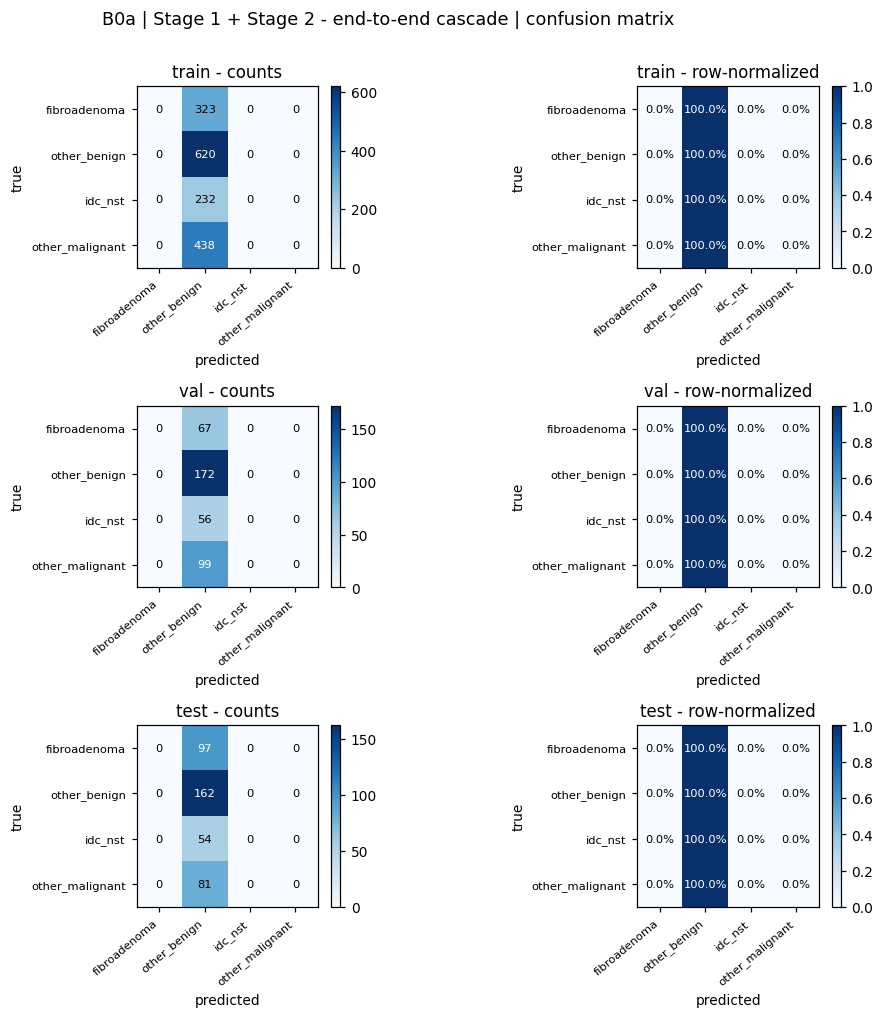

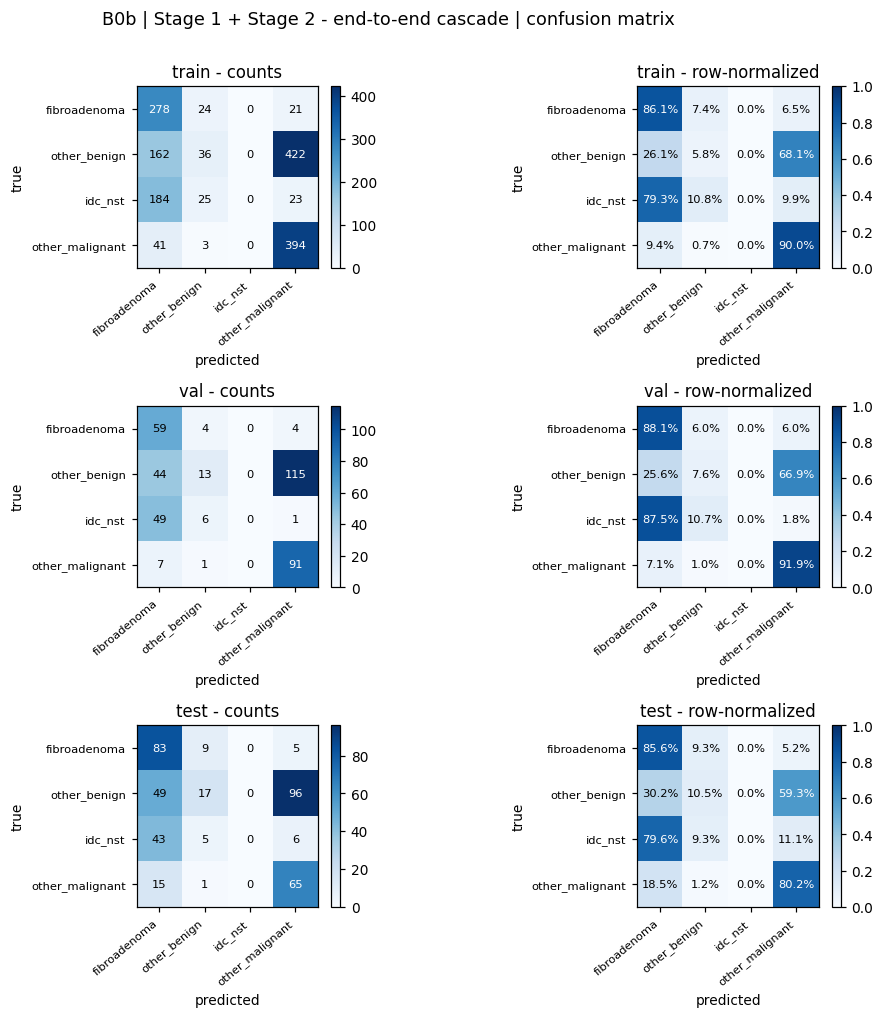

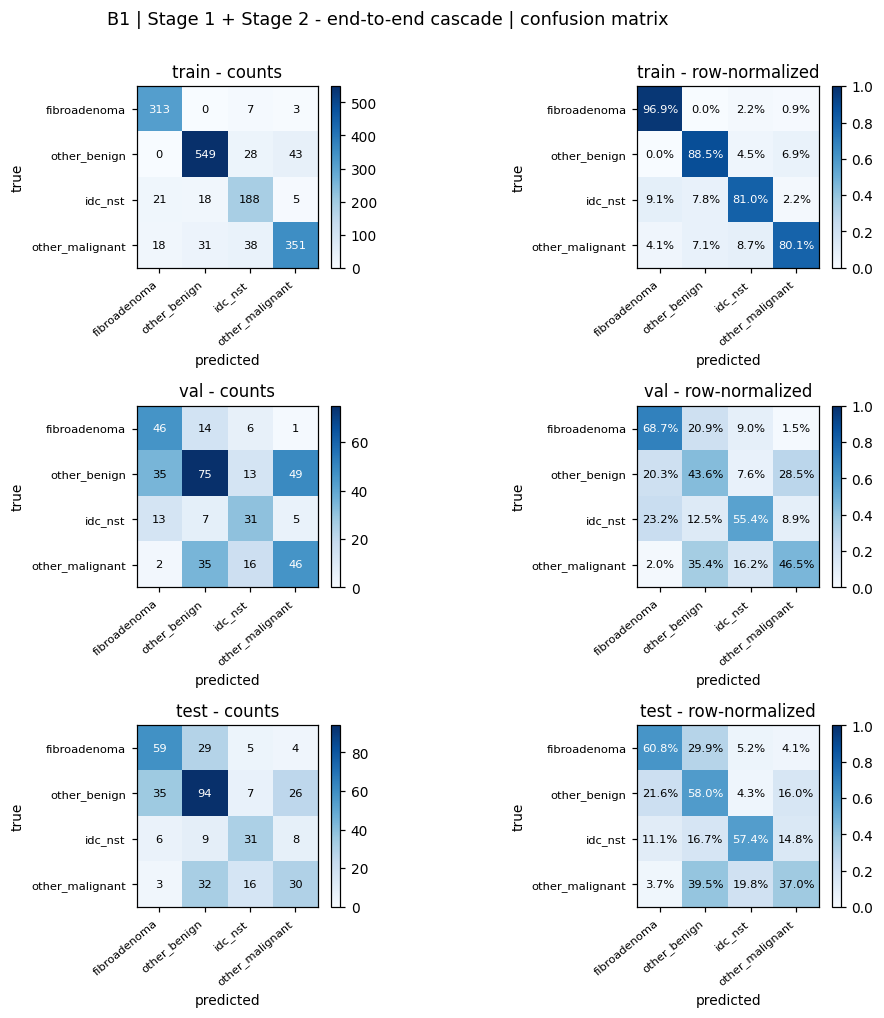

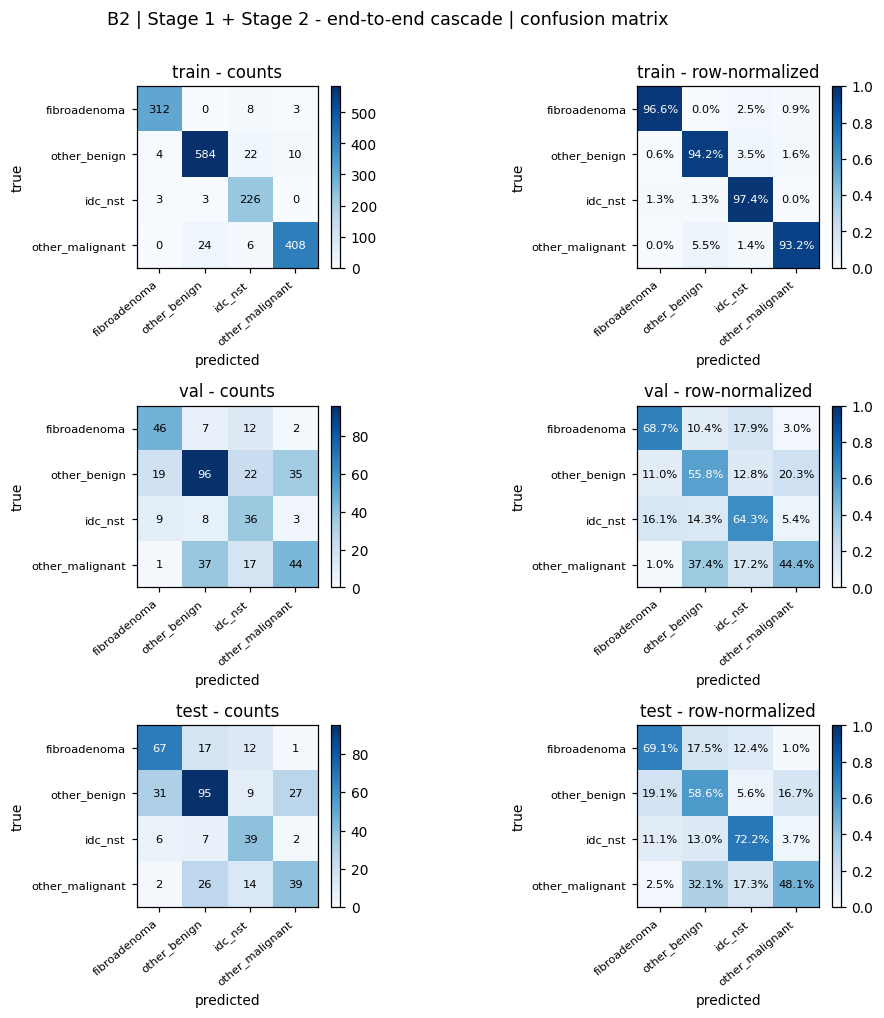

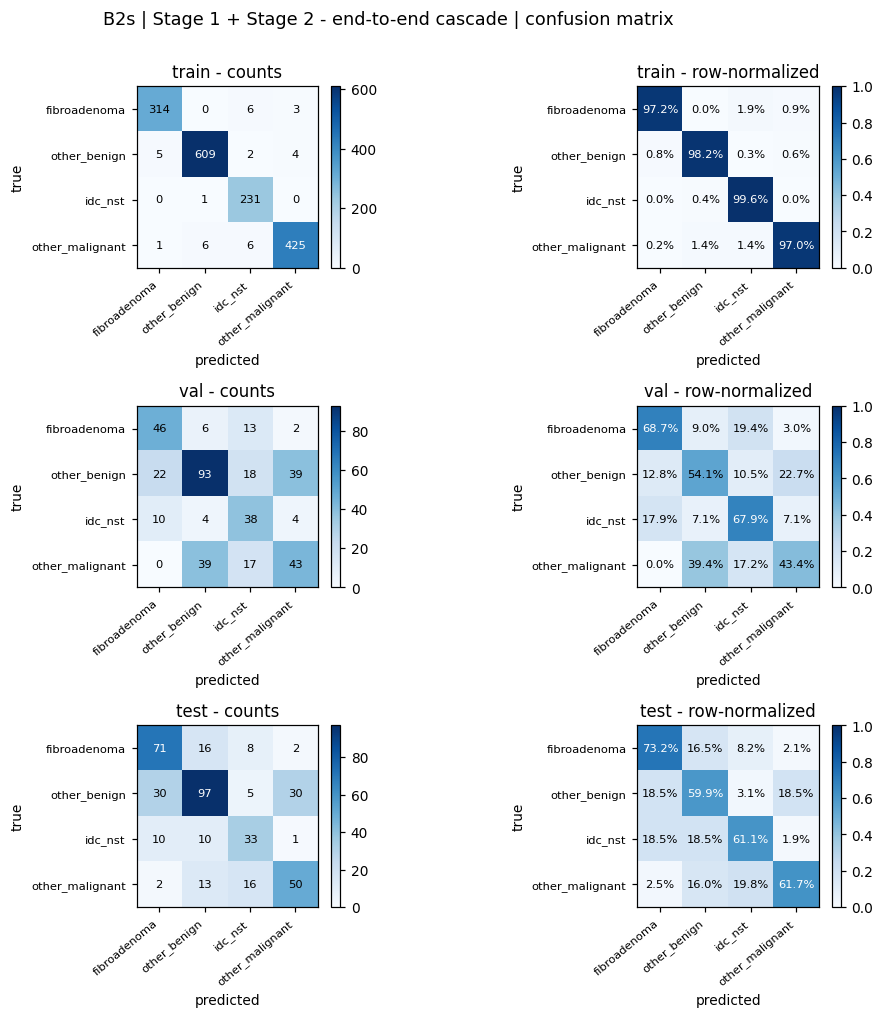

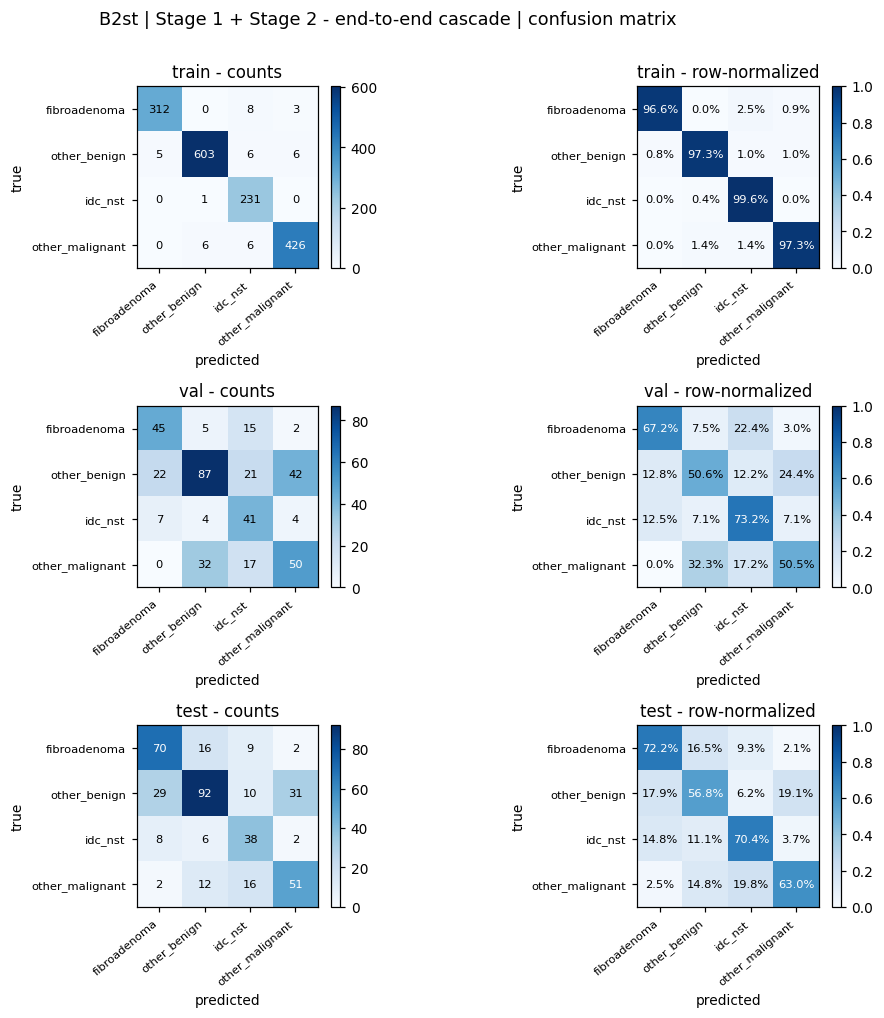

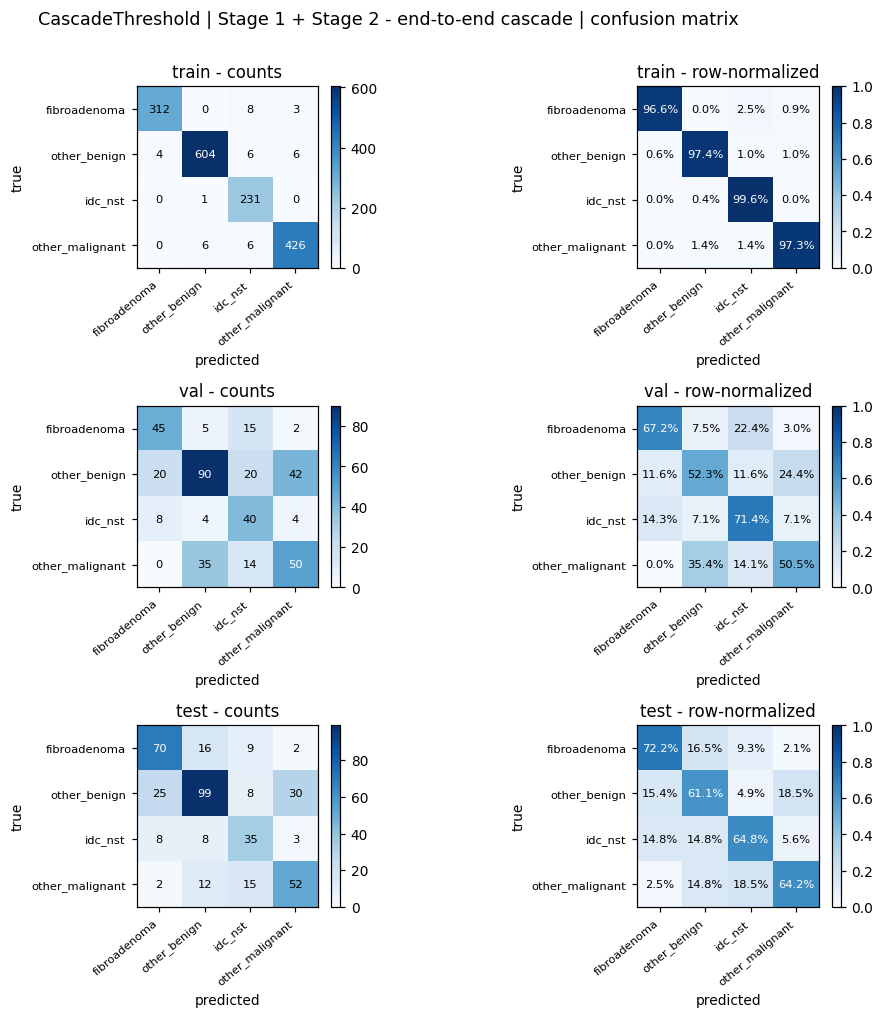

Stage 1 + Stage 2 - per-class precision


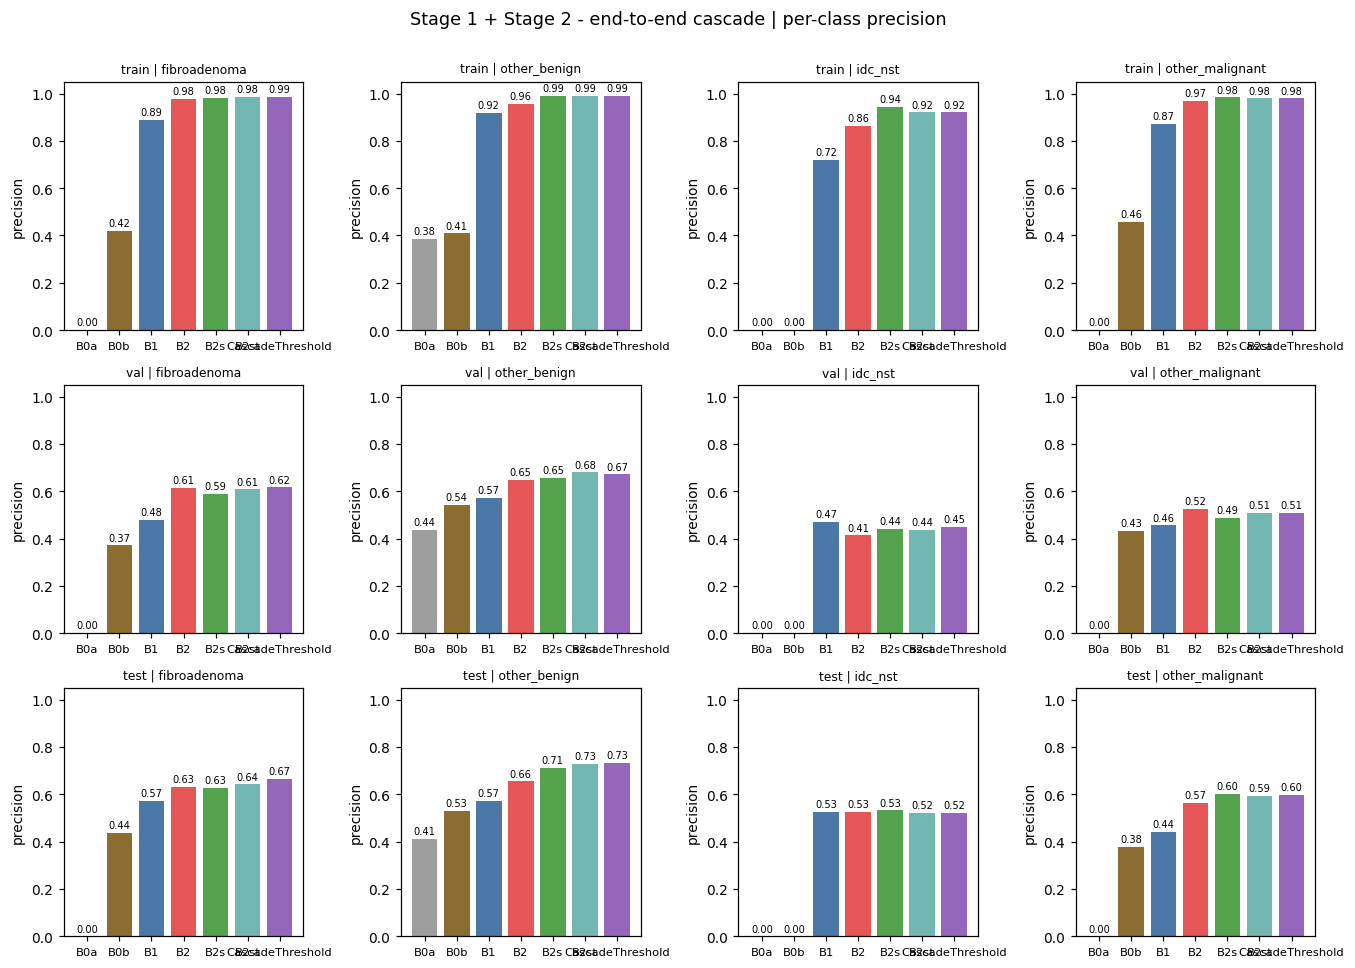

Stage 1 + Stage 2 - per-class recall


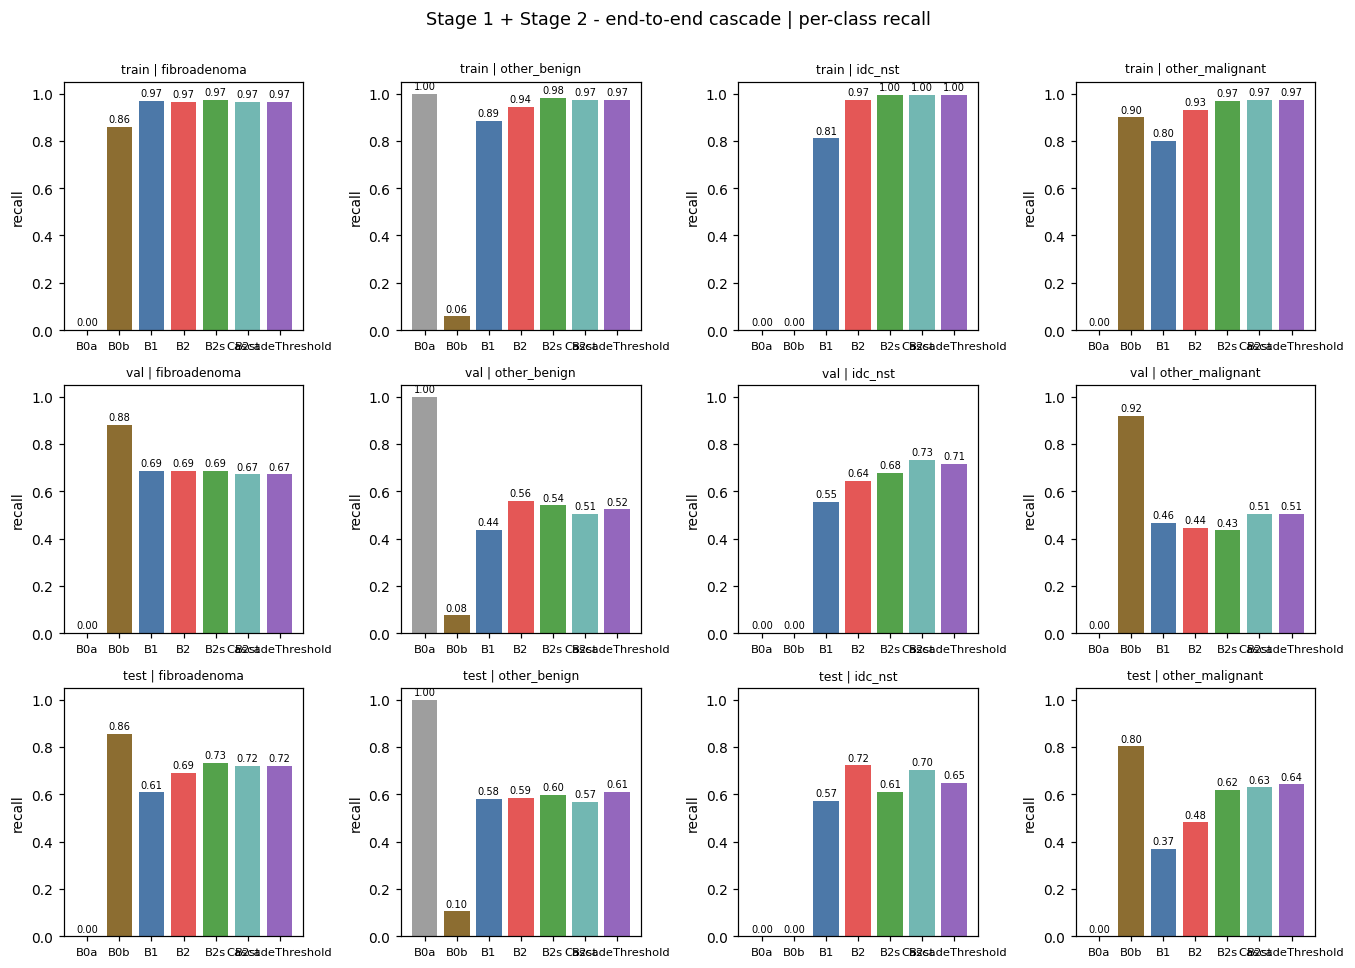

Stage 1 + Stage 2 - per-class f1


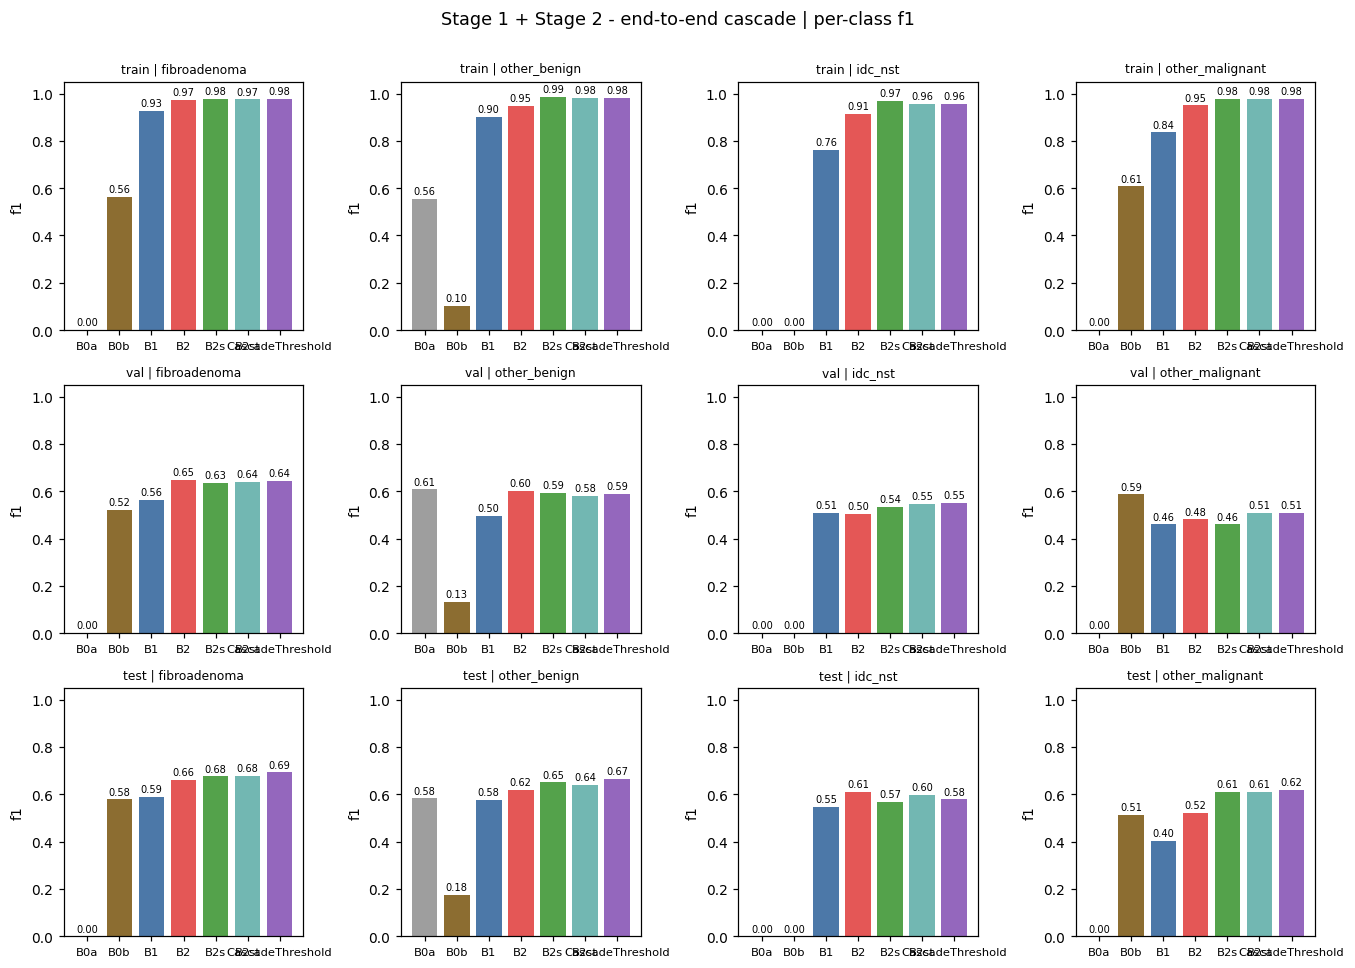

In [19]:
# ============================================================
# METRICS - end-to-end cascade plots
# branch = p1; subtype = p2a / p2b; 4-leaf metrics on labeled rows only.
# ============================================================
print("Stage 1 + Stage 2 - cascade confusion matrices")
xm_confusion_figure("cascade")

for _metric in ("precision", "recall", "f1"):
    print(f"Stage 1 + Stage 2 - per-class {_metric}")
    xm_perclass_figure("cascade", _metric)


--- accuracy ---


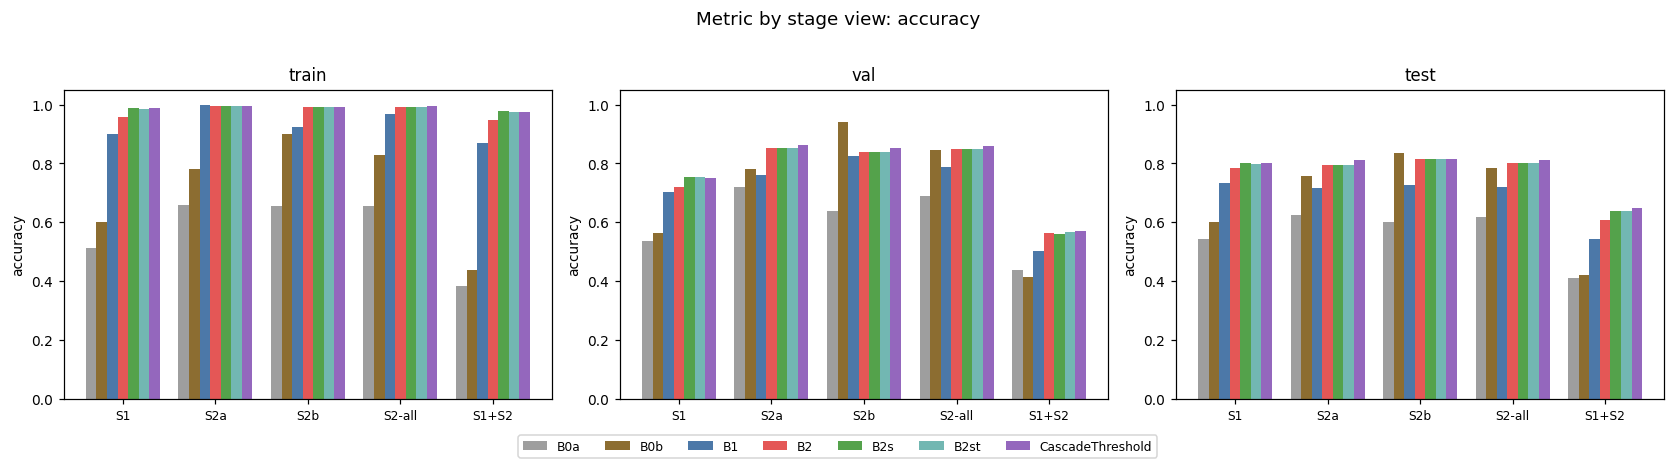


--- balanced_accuracy ---


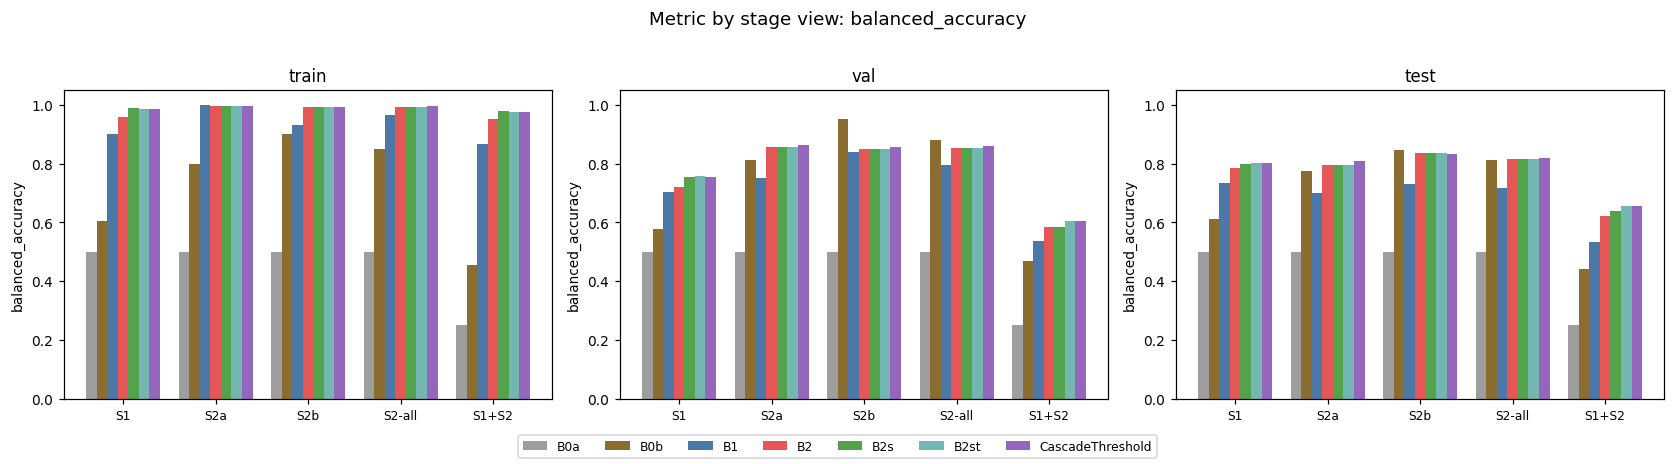


--- precision_macro ---


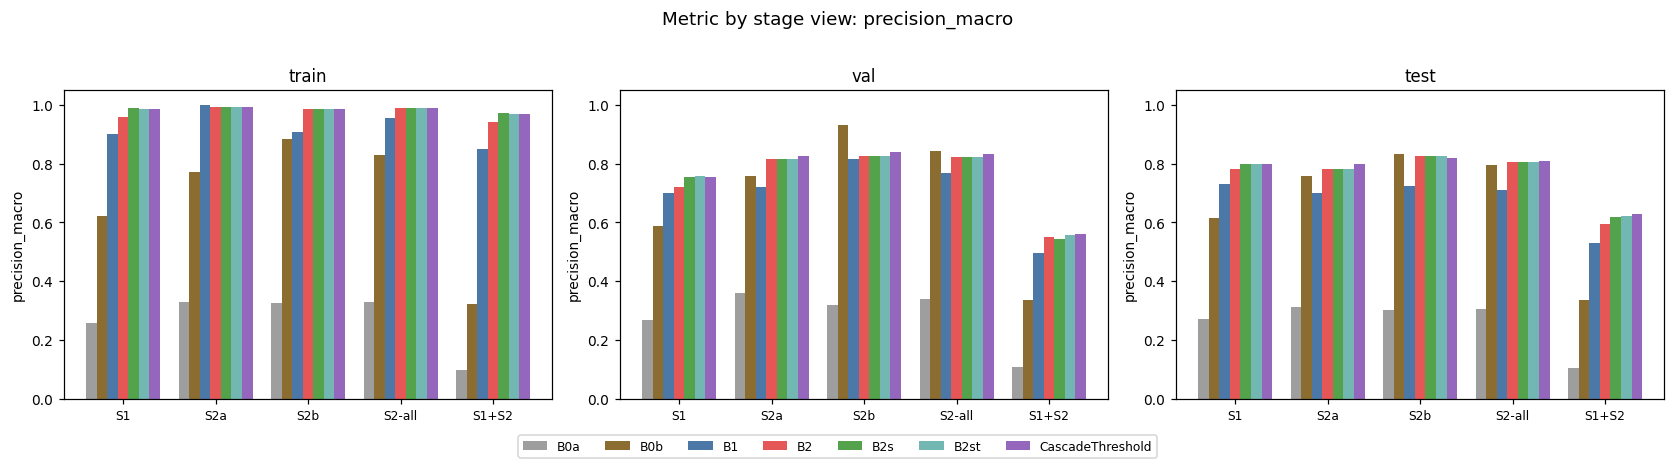


--- recall_macro ---


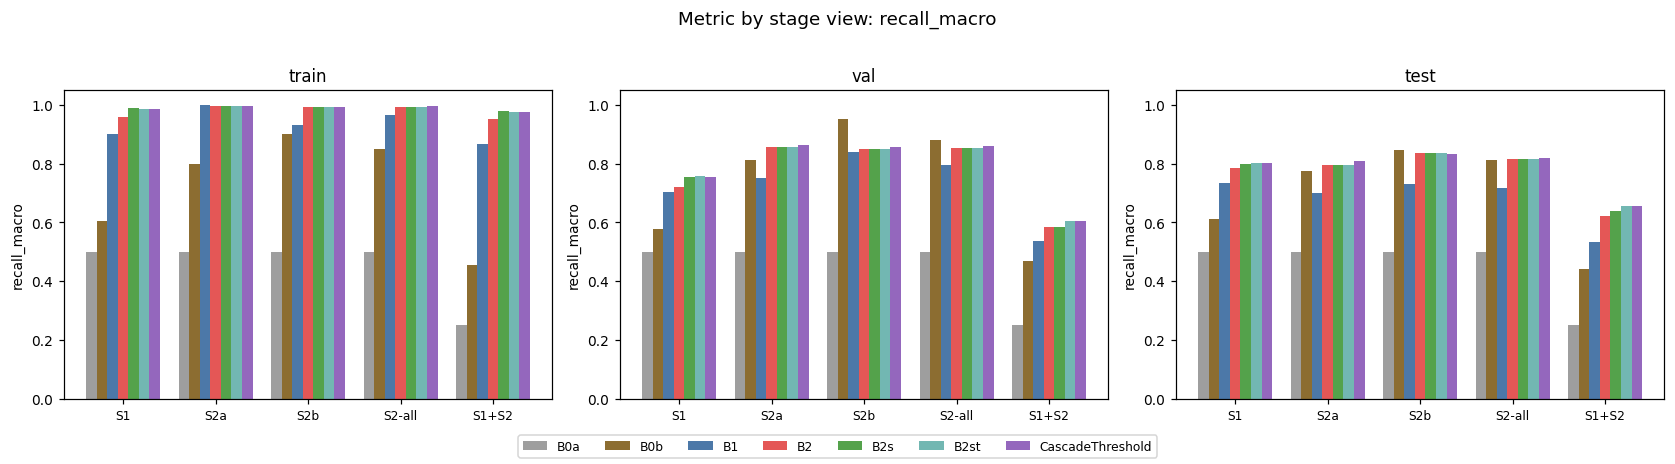


--- f1_macro ---


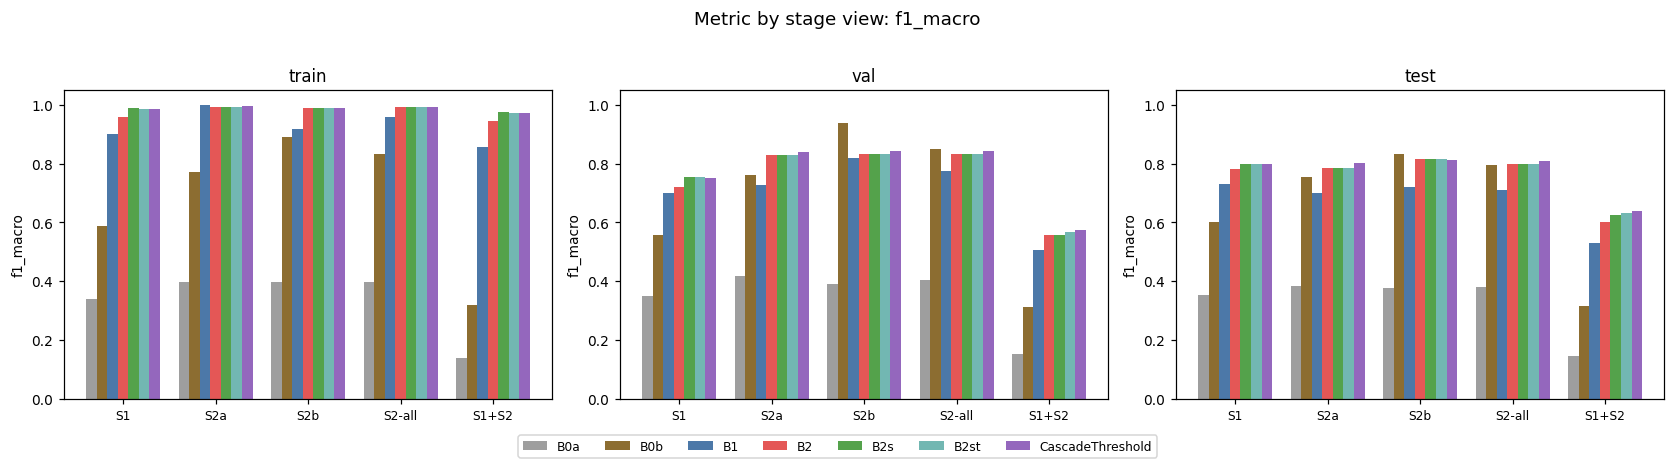


--- f1_weighted ---


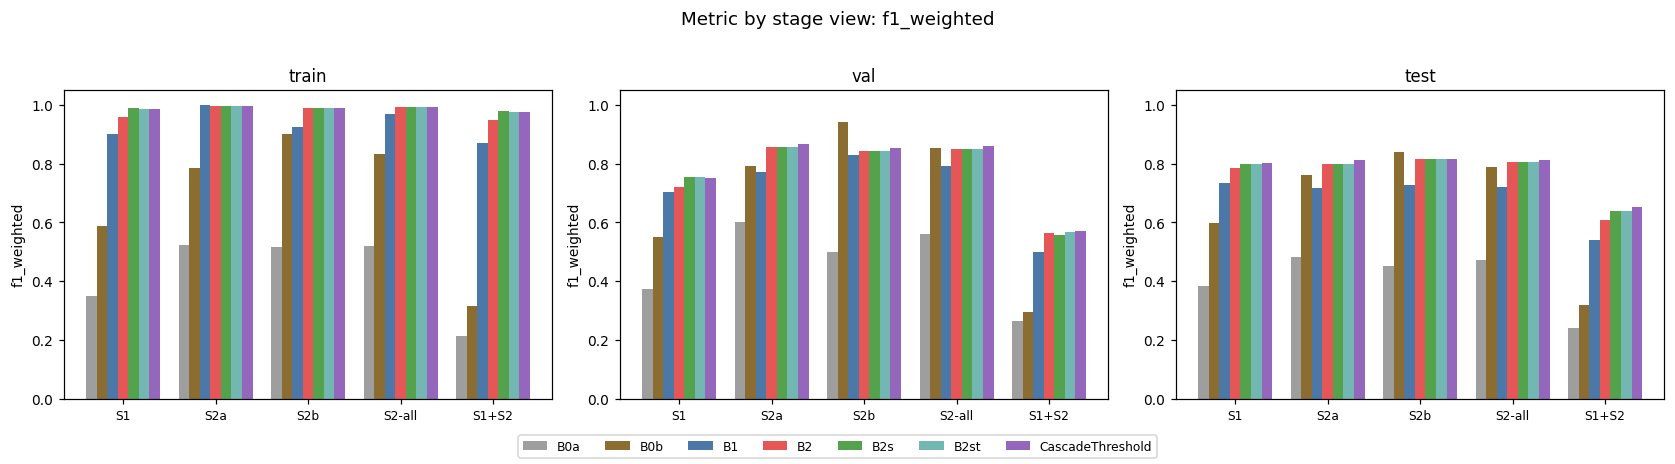


--- specificity_macro ---


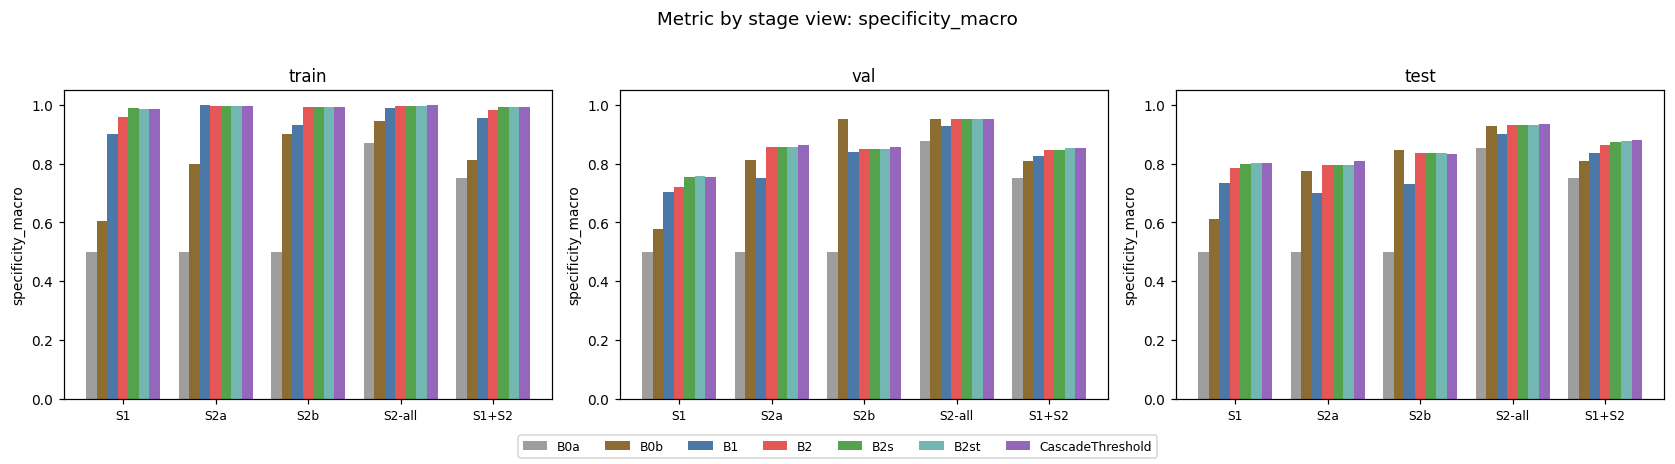


--- npv_macro ---


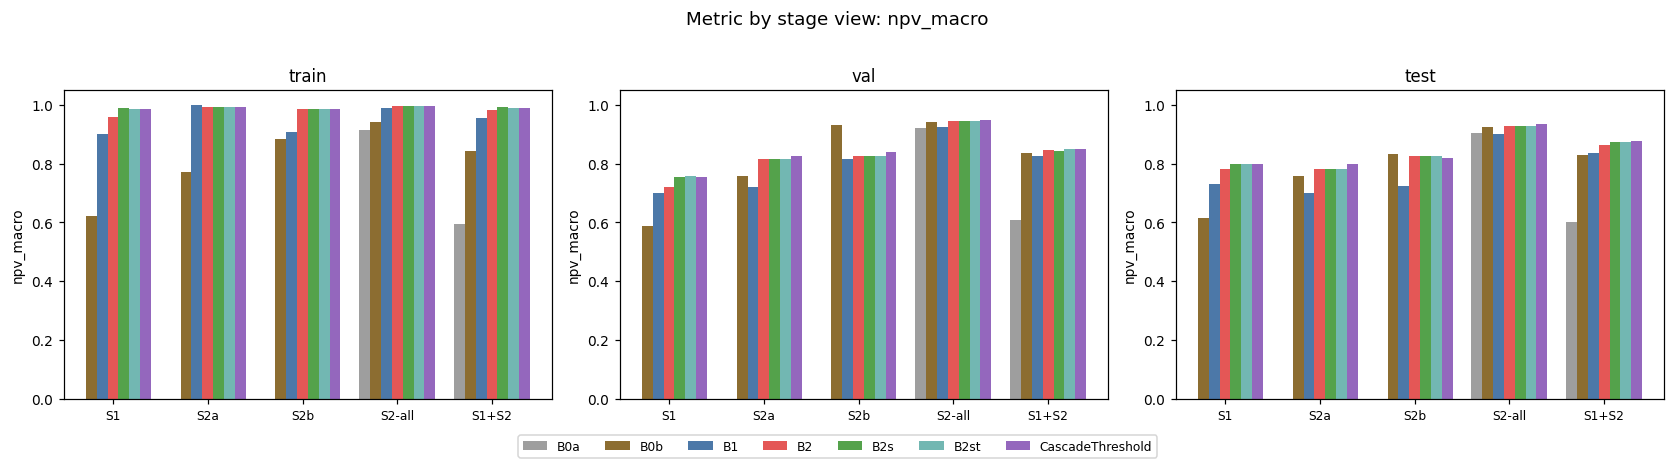


--- mcc ---


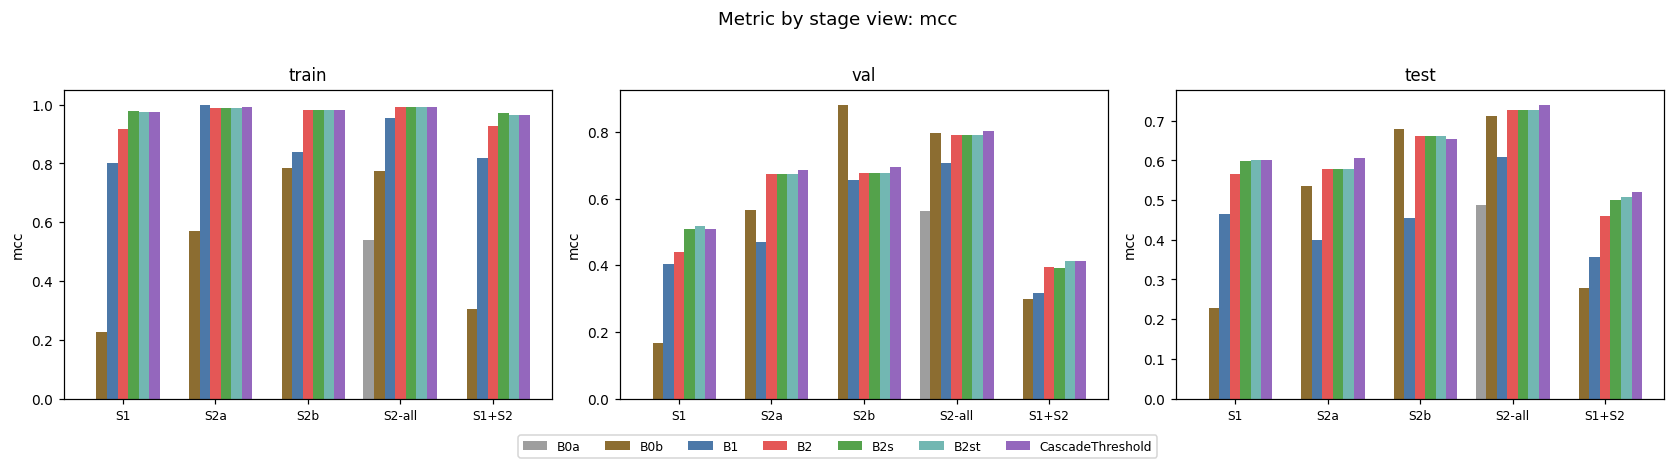


--- cohen_kappa ---


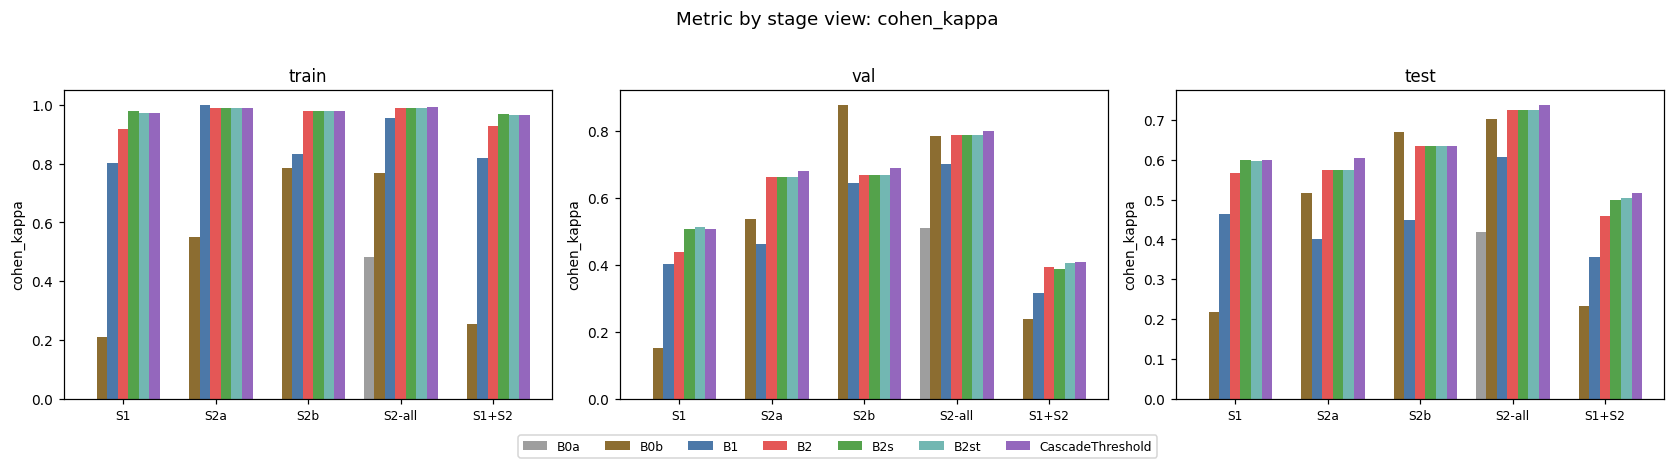


--- jaccard_macro ---


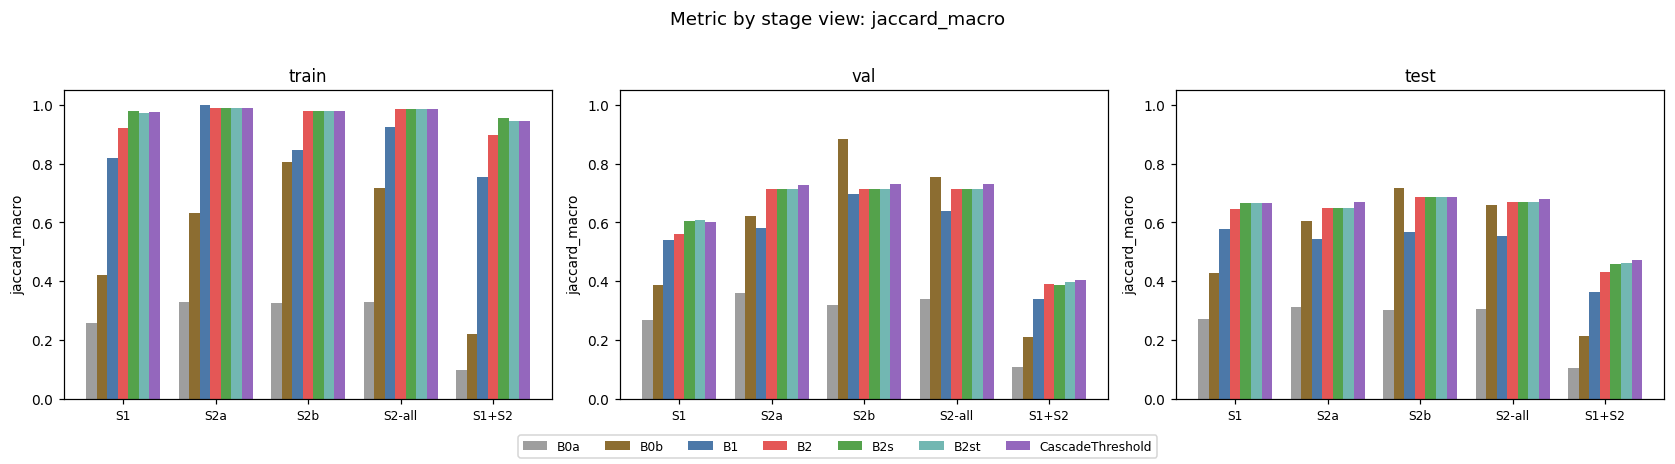


--- hamming_loss ---
(lower is better)


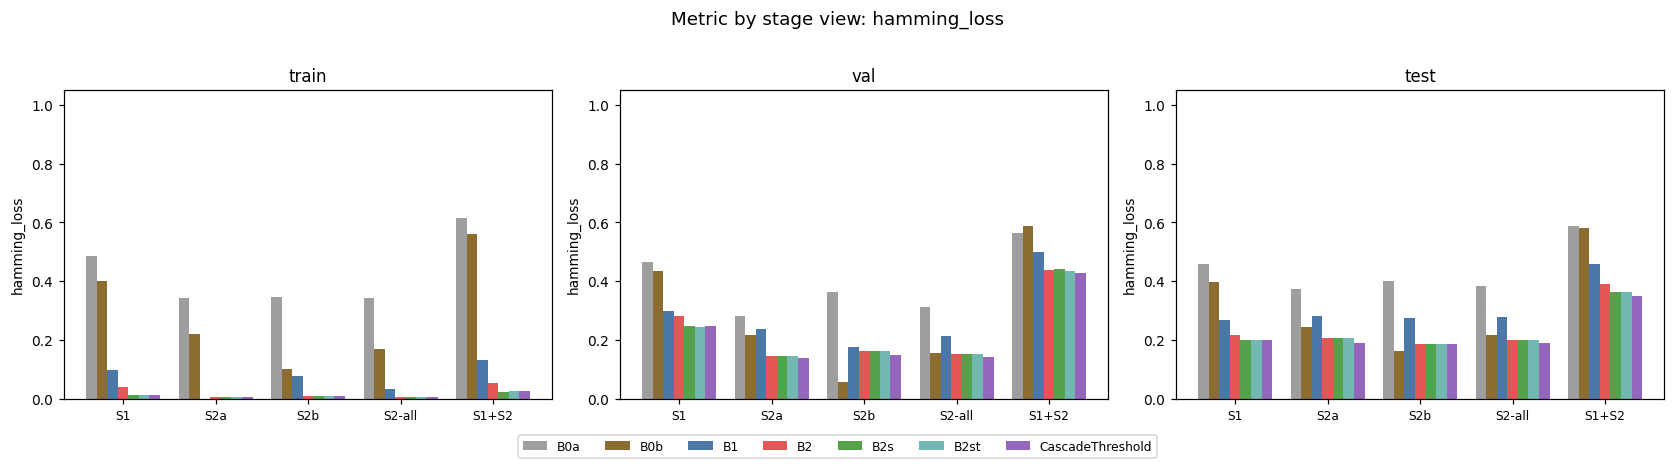


--- roc_auc ---


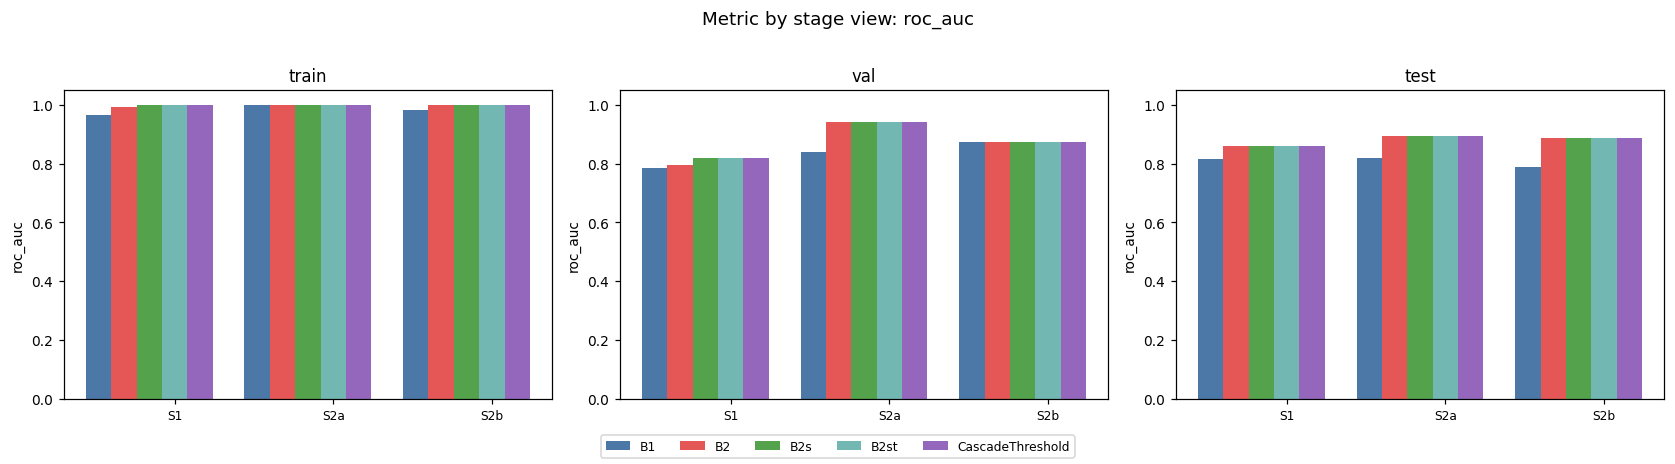


--- pr_auc ---


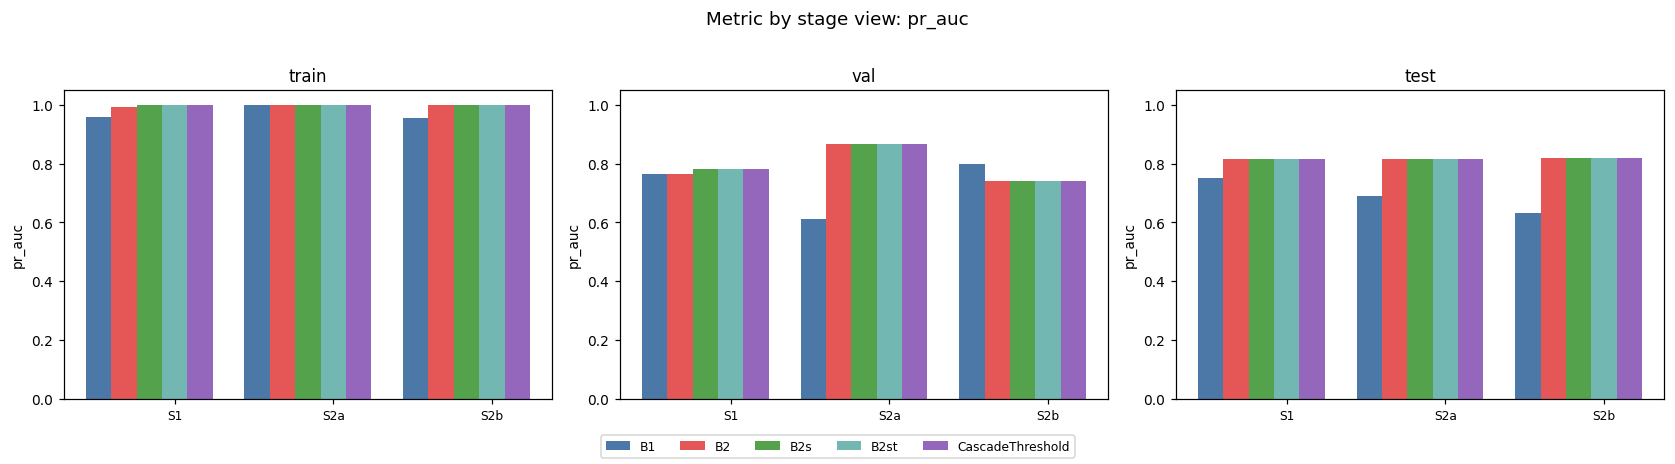


--- youden_j ---


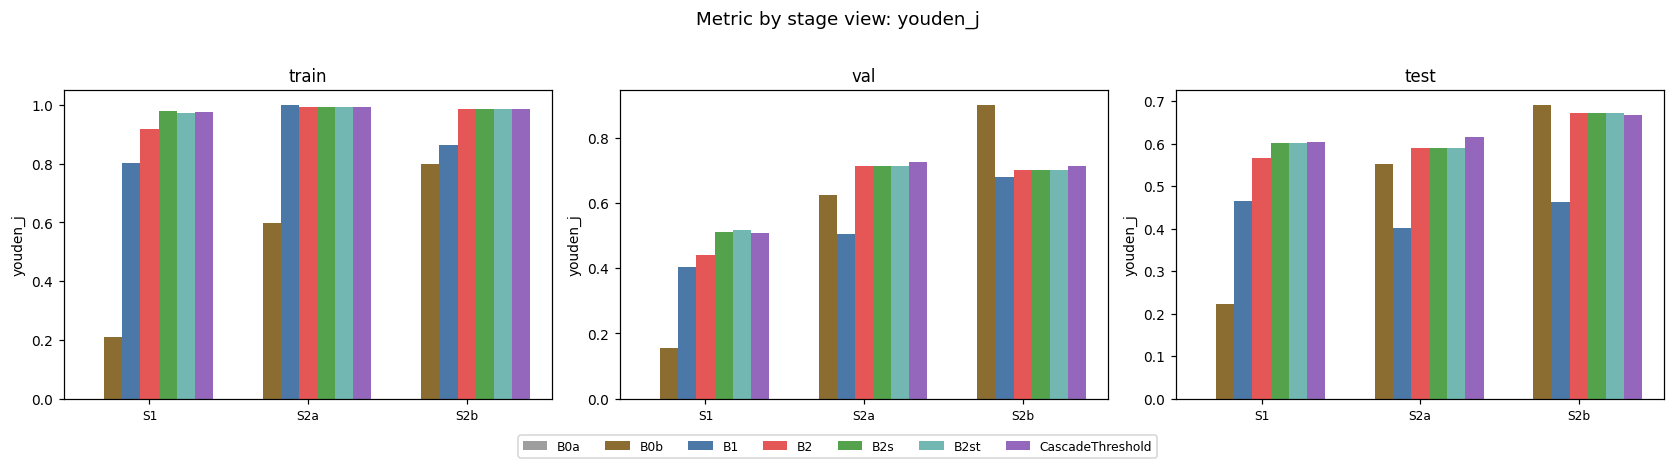

In [20]:
# ============================================================
# METRICS - metric-by-metric comparison
# One figure per metric: x = stage view, bars = models, panels = train/val/test.
# ============================================================
for _metric in XM_PLOT_METRICS:
    print(f"\n--- {_metric} ---")
    if _metric in ("hamming_loss", "zero_one_loss", "error_rate"):
        print("(lower is better)")
    xm_metric_by_view_figure(_metric)

## Known limits

- **Single seed (99):** seed-to-seed variance is not measured; small point-estimate differences should not be over-interpreted.
- **Threshold selection:** CascadeThreshold is the top point estimate (0.6393), but its paired cascade difference versus B2 is +0.0372 with CI [-0.0090, 0.0828]; versus B2s it is +0.0128 with CI [-0.0074, 0.0334]. Neither interval excludes zero.
- **Source confounding:** B0b reaches 0.8344 macro-F1 on stage 2b without image input. This makes source/label association a material limitation, not proof that image models rely on shortcuts.
- **Small subtype test sets and one public multi-source dataset:** stage 2b has 135 test cases; external-site validation is absent.
- **Clinical scope:** scores are not calibrated confidence estimates; no referral threshold, clinical utility, or diagnostic claim is established. Calibration, risk-coverage analysis, and Grad-CAM remain future work.